# Exploratory hypotheses

A first **descriptive** pass over four open questions. Plots only — no API calls, no new
pipeline stages, no inferential tests. Every error bar is a **95% percentile bootstrap CI over
participants**; the unit of analysis is always the participant, so each participant's 5
sessions are collapsed to one value before any group mean is taken.

| | question | where |
|---|---|---|
| **Q1a** | Are perception descriptions better than memory descriptions? | §1 |
| **Q1b** | Does feedback improve descriptions across attempts? | §2 |
| **Q2** | Did immediate vs delayed fail to differ because 4/5 images are high-memorability? | §3 |
| **Q3** | Which objects do people report, and do they agree with each other? | §4 |
| **Q4** | Which objects get *added* on attempts 2–3, and are they the same across people? | §5 |

### Two things to keep in mind while reading every figure

**1. The semantic data is one collection round stale.** `docs/data_log.md` records that
pipeline stages 4–7 have not been re-run since the last two top-up rounds. The combined
validated table holds **1981 rows / 192 participants**, against 2101 rows in the current
`trials_final.csv`. This is the only validated data that exists, so it is what is plotted; the
load cell prints the N of every cell so nothing here is read as final. Re-running stages 6–7
and re-executing this notebook is the fix — no code below needs to change.

**2. Task and generation are between-participants; attempt and image are within.** Each of the
9 condition slugs is a separate participant group (17–25 participants each). So
perception-vs-memory is an *unpaired* comparison, while attempt-to-attempt (§2, §5) and
image-to-image (§3) are *paired* within participant — which is why those sections use
per-participant deltas and slopes rather than group means.

In [1]:
import sys
import json
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Shared style constants + count/plot helpers, lifted out of the per-notebook config cells.
sys.path.insert(0, str(Path.cwd() if (Path.cwd() / "plot_helpers.py").exists()
                       else Path.cwd() / "analysis" / "notebooks"))
from plot_helpers import *          # noqa: F403

config = import_config()
set_style()
print("project root:", config.ROOT)

project root: /mnt/hdd/anatkorol/Imagination_in_translation


## Load

Four inputs, all already on disk:

- **`df`** — the combined validated semantic table (all 9 conditions), plus the similarity
  metrics merged on `(uid, session, attempt)` and the derived rate measures §1 needs.
- **`items`** — `df` exploded to **one row per tagged item** out of the `item_evaluations`
  JSON. This is the only column carrying item text, its category and the judge's verdict
  together, so every object-level analysis in §4–§5 runs off it.
- **`ceil`** — the GPT-with-the-image baseline: one description per GT image, same tagger,
  same judge. Used both as a reference line and as the per-image normaliser.
- **`lm`** — the LabelMe polygon annotations of the GT photos: the objective inventory of what
  is actually in each image.

`COUNT_MODE = "validated"` means every count below is the **image-supported** count, with the
rejected tags carried separately as `h_<cat>` and drawn as a hollow cap.

In [2]:
COUNT_MODE = "validated"
FULL = config.ROOT / "Data" / "processed_data" / "Full_experiment" / "combined" / "full_data"

GRAPHS = config.COMBINED_ANALYSIS_DIR / "graphs" / "exploratory_hypotheses"
GRAPHS.mkdir(parents=True, exist_ok=True)

df = prep_counts(pd.read_csv(FULL / "trials_final_semantic_tag_image_validation_full_data.csv"),
                 "trials", mode=COUNT_MODE)

# --- similarity metrics, merged on the trial key ---------------------------------
# validate="1:1" is the assertion that the two tables describe the same trials: if the
# similarity stage were re-run at a different time than the semantic one, this raises.
sim = pd.read_csv(FULL / "trials_final_sim_full_data.csv")
SIM_COLS = ["token_num", "clip_cosine_distance", "vgg_fc7_distance", "clip_vis_text_similarity"]
df = df.merge(sim[["uid", "session", "attempt"] + SIM_COLS],
              on=["uid", "session", "attempt"], how="left", validate="1:1")

# Distances -> similarities, so every metric in this notebook points the same way (up = better).
df["clip_similarity"] = 1 - df["clip_cosine_distance"]
df["vgg_similarity"] = 1 - df["vgg_fc7_distance"]

ceil = load_gpt_ceiling(config, mode=COUNT_MODE)
lm = load_labelme(config)
items = explode_items(df)
objs = items[items["category"] == "objects"].copy()      # the frame §4-§5 work on

df["memorability"] = df["gt"].map(MEMORABILITY)
objs["memorability"] = objs["gt"].map(MEMORABILITY)

loaded gpt-5.5_desc from gpt_ceiling/: 5 descriptions, 5 GT images
loaded LabelMe: 65 annotated object types over 5 GT images
exploded items: 34525 rows, 8789 distinct item strings


In [3]:
# --- Derived per-trial measures -------------------------------------------------
# Rates are NaN (not 0) when nothing was extracted: a participant who wrote no objects has no
# defined accuracy, and averaging a 0 in would understate the group.
def _rate(num, den):
    return np.where(den > 0, num / den.replace(0, np.nan), np.nan)

for cat in VALIDATED_CATEGORIES:
    ext = df[f"n_extracted_{cat}"]
    df[f"precision_{cat}"] = _rate(df[f"n_in_image_{cat}"], ext)
    df[f"halluc_rate_{cat}"] = _rate(df[f"n_not_in_image_{cat}"], ext)

# Pooled over the five judged categories - the overall "how much of what you said was there".
df["precision_all"] = _rate(df["n_in_image"], df["n_extracted"])
df["halluc_rate_all"] = _rate(df["n_not_in_image"], df["n_extracted"])

# Density: is perception simply *longer*, or actually denser?
df["objects_per_100_tok"] = 100 * df["n_in_image_objects"] / df["token_num"]

# Ceiling-normalised: each image scored against what GPT extracts from that same image while
# looking at it. Makes the five GTs commensurable despite very different scene richness.
CEIL_OBJECTS = ceil.set_index("gt")["n_objects"].to_dict()
df["ceil_frac_objects"] = df["n_in_image_objects"] / df["gt"].map(CEIL_OBJECTS)

# subjective_score exists only where a generated image was shown back to the participant.
print("subjective_score present for:",
      sorted(df.loc[df["subjective_score"].notna(), "generation"].unique()))

subjective_score present for: ['aigen']


In [4]:
# --- Sanity checks: these must all pass before any figure is trusted -------------
print(f"rows={len(df)}  participants={df['uid'].nunique()}  "
      f"validation errors={int(df['error'].notna().sum())}")

# The explode must neither lose nor duplicate items.
assert len(items) == df["n_extracted"].sum(), "explode lost or duplicated items"
for c in VALIDATED_CATEGORIES:
    a = int(((items["category"] == c) & items["in_image"]).sum())
    b = int(df[f"n_in_image_{c}"].sum())
    assert a == b, f"{c}: exploded {a} != n_in_image {b}"
print("explode integrity: OK "
      f"({len(items)} items, {objs['item'].nunique()} distinct object strings)")

# One judge configuration across the whole table, or the counts are not comparable.
for col in ("judge_model", "tagger_model", "image_detail", "judged_categories"):
    vals = sorted(set(df[col].dropna().astype(str)))
    assert len(vals) == 1, f"mixed {col}: {vals} - revalidate before trusting these counts"
print("single judge/tagger config: OK")

# N per cell - the caveat that every figure below has to be read against.
n_tab = (df[df["attempt"] == 1]
         .pivot_table(index=["generation", "task"], columns="gt", values="uid",
                      aggfunc="nunique", fill_value=0))
print("\nparticipants per cell (attempt 1):")
display(n_tab)

rows=1981  participants=192  validation errors=0
explode integrity: OK (34525 items, 1591 distinct object strings)
single judge/tagger config: OK

participants per cell (attempt 1):


gt                     bedroom_l.jpg  conference_room_h.jpg  lighthouse_h.jpg  \
generation task                                                                 
aigen      delay                  21                     21                19   
           immediate              21                     23                21   
           perception             19                     19                18   
nogen      delay                  16                     14                15   
           immediate              20                     19                19   
           perception             17                     17                12   
plain      delay                  19                     20                18   
           immediate              22                     24                21   
           perception             24                     24                24   

gt                     living_room_h.jpg  playground_h.jpg  
generation task                                             
aigen      delay                      20                18  
           immediate                  22                22  
           perception                 19                18  
nogen      delay                      16                13  
           immediate                  20                18  
           perception                 16                17  
plain      delay                      19                20  
           immediate                  25                22  
           perception                 25                24

## Plot primitives for this notebook

`plot_helpers` supplies the style and the bar decorations. These three add the layouts this
notebook needs and `full_data_comparisons.ipynb` does not have: a **generic** grouped-bar
draw that works on any measure column (not just the count/cap pair), and a paired
per-participant view.

In [5]:
GEN_ORDER = ["aigen", "nogen", "plain"]
FB_GENS = ["aigen", "nogen"]        # the two with a feedback loop; plain has one attempt
GT_ORDER = ["bedroom_l.jpg", "living_room_h.jpg", "conference_room_h.jpg",
            "lighthouse_h.jpg", "playground_h.jpg"]
GT_LABELS = {g: g.replace(".jpg", "") for g in GT_ORDER}
MEM_ORDER = ["low", "high"]
MEM_LABELS = {"low": "Low memorability\n(bedroom_l)", "high": "High memorability\n(other 4)"}


def enumerate_tasks(axes):
    """Pair a 3-panel axes row with TASK_ORDER - the layout used all through the notebook."""
    return zip(np.atleast_1d(axes).ravel(), TASK_ORDER)


def gens_present(data, order=GEN_ORDER):
    """The generations actually in `data`, in canonical order - so a legend never shows an
    empty swatch and a dropped arm is visible as an absence rather than a blank bar."""
    return [g for g in order if g in set(data["generation"])]


def draw_bars(ax, data, x_col, x_order, hue_col, hue_order, value_col,
              cap_col=None, palette=None, dots=True, values=True, fmt="{:.2f}"):
    """Grouped bars + participant dots + bootstrap CI + value labels, for ANY measure.

    Generalises the count/cap version in full_data_comparisons.ipynb: `value_col` is whatever
    is being plotted and `cap_col` is optional, so the same call draws validated counts with a
    hallucination cap, a precision rate, or a similarity score. Returns the height everything
    fits under, for the caller's y limit.
    """
    palette = palette or GEN_COLORS
    dodge = hue_col != x_col
    g = geom(hue_order, dodge=dodge)
    x_index = {v: i for i, v in enumerate(x_order)}

    sns.barplot(data=data, x=x_col, y=value_col, hue=hue_col, order=x_order,
                hue_order=hue_order, palette=palette, errorbar=None, legend=False,
                ax=ax, zorder=2)

    plot = data.rename(columns={value_col: "count"})
    plot["cap"] = data[cap_col] if cap_col else 0.0
    means = plot.groupby([x_col] if not dodge else [x_col, hue_col])[["count", "cap"]].mean()
    if not dodge:
        means.index = pd.MultiIndex.from_arrays([means.index, means.index])

    if cap_col:
        add_caps(ax, x_index, hue_order, bottoms=means["count"].to_dict(),
                 caps=means["cap"].to_dict(), geom=g,
                 color_of=lambda xv, s: palette[s])
    if dots:
        sns.stripplot(data=data, x=x_col, y=value_col, hue=hue_col, order=x_order,
                      hue_order=hue_order, palette=palette, dodge=dodge, jitter=0.16,
                      size=4.0, alpha=0.45, linewidth=0.4, edgecolor="white",
                      legend=False, ax=ax, zorder=3)
    cis = add_ci(ax, x_index, hue_order, data, x_col, hue_col, value_col, g)

    vmax = float(np.nanmax([data[value_col].max(), means.sum(axis=1).max()]))
    if values:
        add_bar_labels(ax, x_index, hue_order, means, cis, g, headroom=vmax, fmt=fmt)
        vmax *= 1.09
    return vmax


def draw_lines(ax, data, x_col, x_order, hue_col, hue_order, value_col, palette=None,
               labels=None):
    """Mean +/- bootstrap CI as connected points - the view for an interaction, where the
    *slope* between two levels is the thing being read rather than the heights."""
    palette = palette or GEN_COLORS
    for s in hue_order:
        xs, ms, los, his = [], [], [], []
        for i, xv in enumerate(x_order):
            v = data[(data[hue_col] == s) & (data[x_col] == xv)][value_col].dropna()
            if len(v) < 2:
                continue
            lo, hi = boot_ci(v)
            xs.append(i); ms.append(v.mean()); los.append(lo); his.append(hi)
        if not xs:
            continue
        ax.errorbar(xs, ms, yerr=[np.array(ms) - los, np.array(his) - ms],
                    color=palette[s], lw=3, marker="o", markersize=11, capsize=5,
                    capthick=2, elinewidth=2, label=(labels or {}).get(s, s), zorder=3)
    ax.set_xticks(range(len(x_order)))

---
# 1. Q1a — are perception descriptions better than memory descriptions?

**Attempt 1 only**, all three arms. Attempt 1 is the only attempt `plain` has, and the only
one untouched by feedback, so it is the one place all three arms describe the same thing.

"Better" is not one number, so this section separates three things that a raw count confounds:

1. **How much** was said (validated counts per category)
2. **How accurate** it was (precision, hallucination rate)
3. **How dense** it was (counts per 100 tokens) — the guard against the trivial reading that
   perception simply produces *longer* text

plus the ceiling-normalised count, which puts the five images on one scale, and the image
similarity metrics.

In [6]:
A1 = df[df["attempt"] == 1].copy()          # every figure in this section
print(f"attempt 1: {len(A1)} trials, {A1['uid'].nunique()} participants")


def plot_measure_by_task(measure, label, data=None, gens=None, cap=None, title=None,
                         fname=None, fmt="{:.2f}", ylim0=True, save=True):
    """One panel: x = task, one bar per generation, for a single measure column."""
    data = A1 if data is None else data
    gens = gens or gens_present(data)
    ppt = (data.groupby(["generation", "task", "uid"], as_index=False)
               [[measure] + ([cap] if cap else [])].mean())
    ppt = ppt.dropna(subset=[measure])

    fig, ax = plt.subplots(figsize=(11, 6.8))
    vmax = draw_bars(ax, ppt, "task", TASK_ORDER, "generation", gens, measure,
                     cap_col=cap, fmt=fmt)
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t] for t in TASK_ORDER])
    style_count_axis(ax, vmax=vmax) if ylim0 else None
    fig.suptitle(title or f"{label} by task (attempt 1)")
    figure_legend(fig, gens, marker="bar", caps=bool(cap), ci=True, y=0.94)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    if save and fname:
        save_fig(fig, GRAPHS / fname)
    plt.show()

attempt 1: 881 trials, 192 participants


### 1.1 How much — validated counts, every semantic category

Solid bar = tags the judge found in the image. Hollow cap = tags it rejected. The dashed line
is the GPT-with-the-image baseline for that category, averaged over the five GT images: the
ceiling a describer reaches when memory is not a constraint at all.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_counts_by_task_all_categories.png


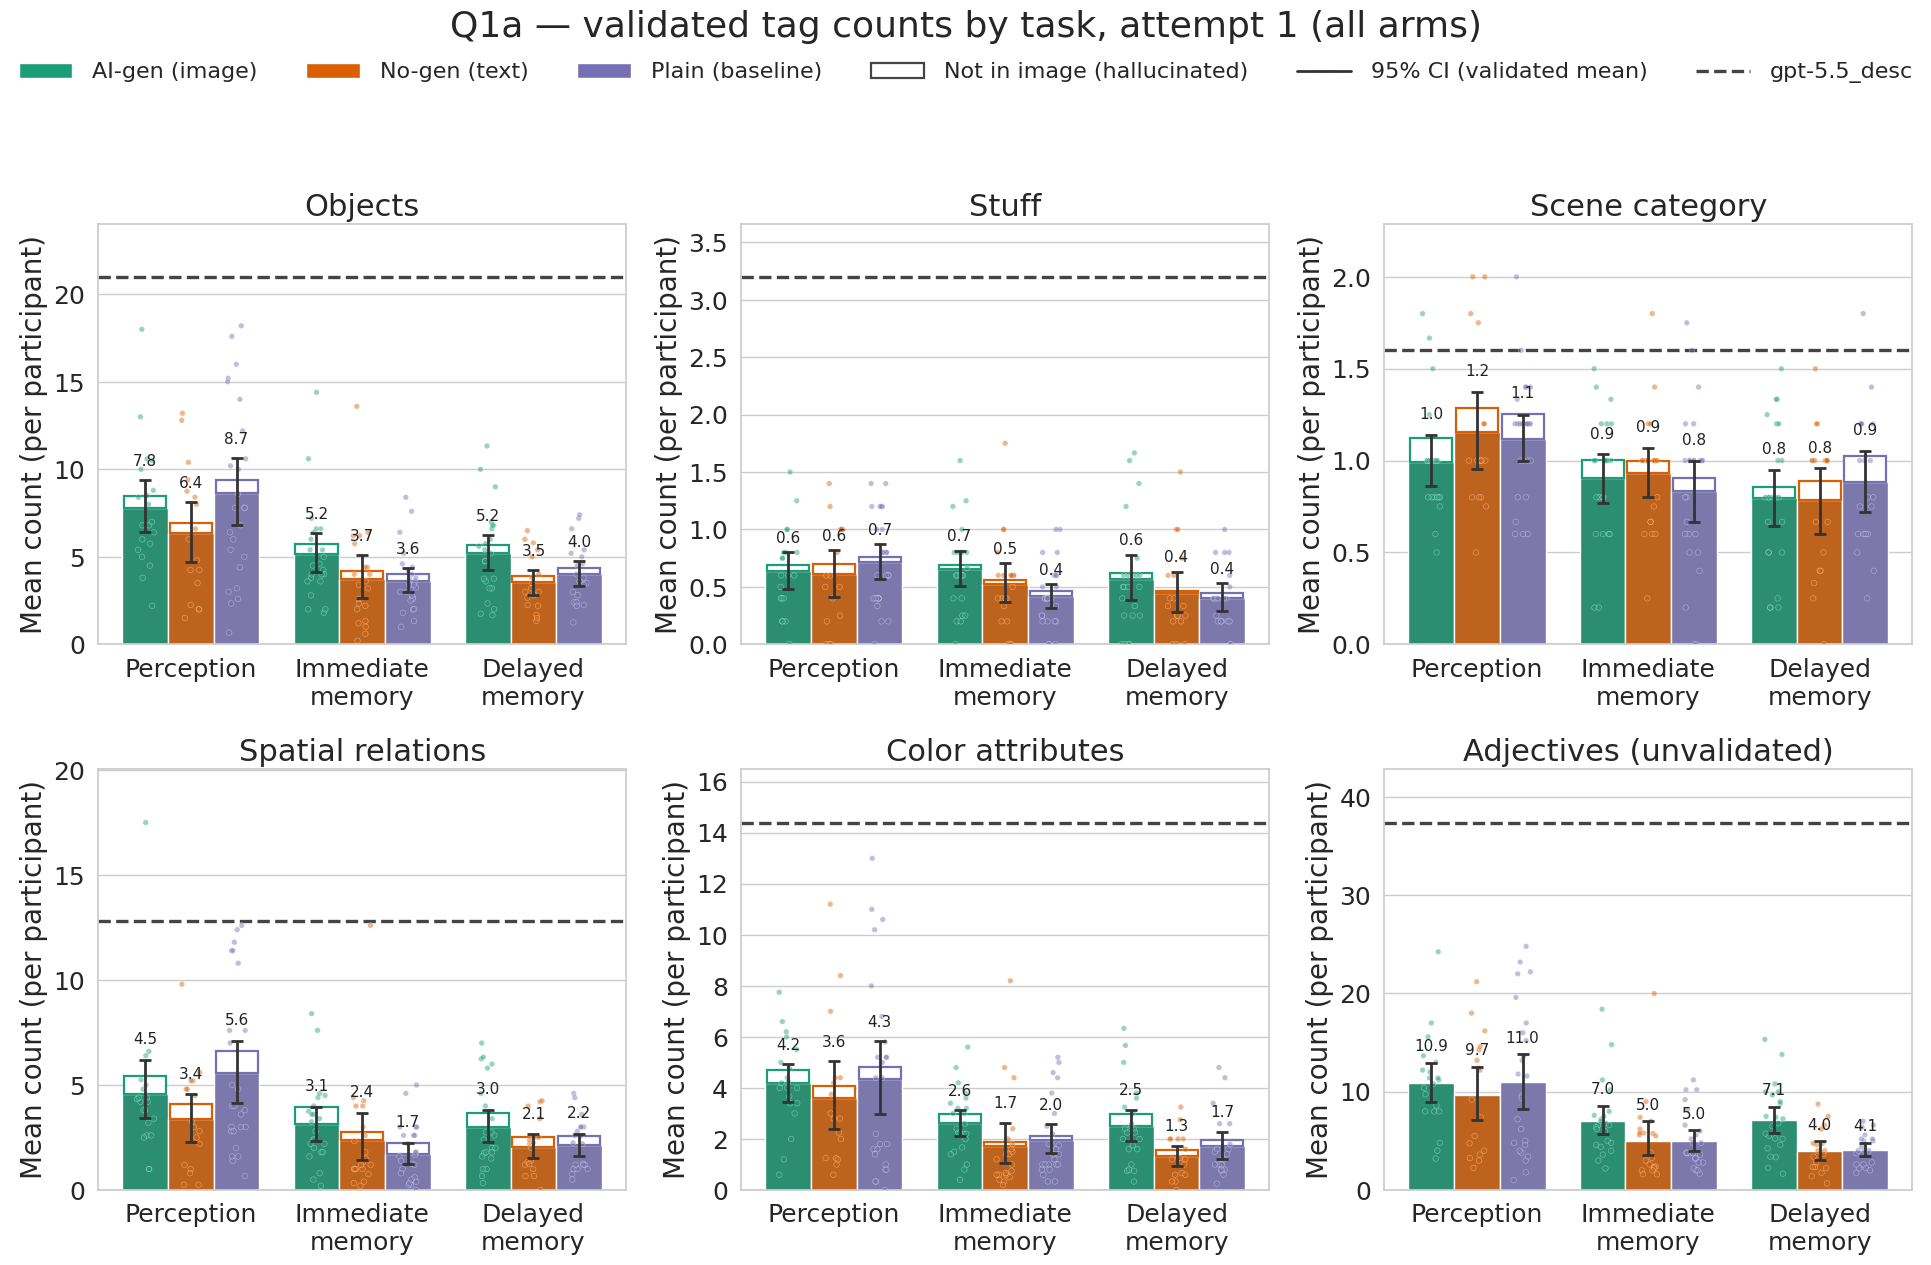

In [7]:
GPT_MEAN = {c: ceil[f"n_{c}"].mean() for c in CATEGORIES} if ceil is not None else {}

fig, axes = plt.subplots(2, 3, figsize=(19.5, 13))
gens = gens_present(A1)
for ax, cat in zip(axes.ravel(), CATEGORIES):
    ppt = ppt_means(A1, ["generation", "task", "uid"], cat)
    vmax = draw_bars(ax, ppt, "task", TASK_ORDER, "generation", gens, "count",
                     cap_col="cap" if is_validated(cat, COUNT_MODE) else None, fmt="{:.1f}")
    if cat in GPT_MEAN:
        ax.axhline(GPT_MEAN[cat], color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
        vmax = max(vmax, GPT_MEAN[cat] * 1.09)
    ax.set_title(cat_label(cat, COUNT_MODE))
    ax.set_xlabel("")
    ax.set_ylabel("Mean count (per participant)")
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t].replace(" ", "\n") for t in TASK_ORDER])
    style_count_axis(ax, vmax=vmax)
fig.suptitle("Q1a — validated tag counts by task, attempt 1 (all arms)")
figure_legend(fig, gens, marker="bar", caps=True, ci=True, gpt=bool(GPT_MEAN), y=0.955)
fig.tight_layout(rect=(0, 0, 1, 0.91))
save_fig(fig, GRAPHS / "q1a_counts_by_task_all_categories.png")
plt.show()

### 1.2 How accurate — precision and hallucination rate

Counts alone cannot separate "memory says *less*" from "memory says *wrong things*". These two
are rates over what the participant actually produced, so a participant who wrote little is
not penalised for it.

**Read the hallucination rate against the judge's own floor, not against zero.** The GPT
descriptions were written *while looking at the image* and still had some tags rejected; that
rate is the judge's false-positive floor and is printed below.

JUDGE FALSE-POSITIVE FLOOR: 5/270 = 1.85% of tags rejected in descriptions written WITH the image in view.
saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_precision_objects_by_task.png


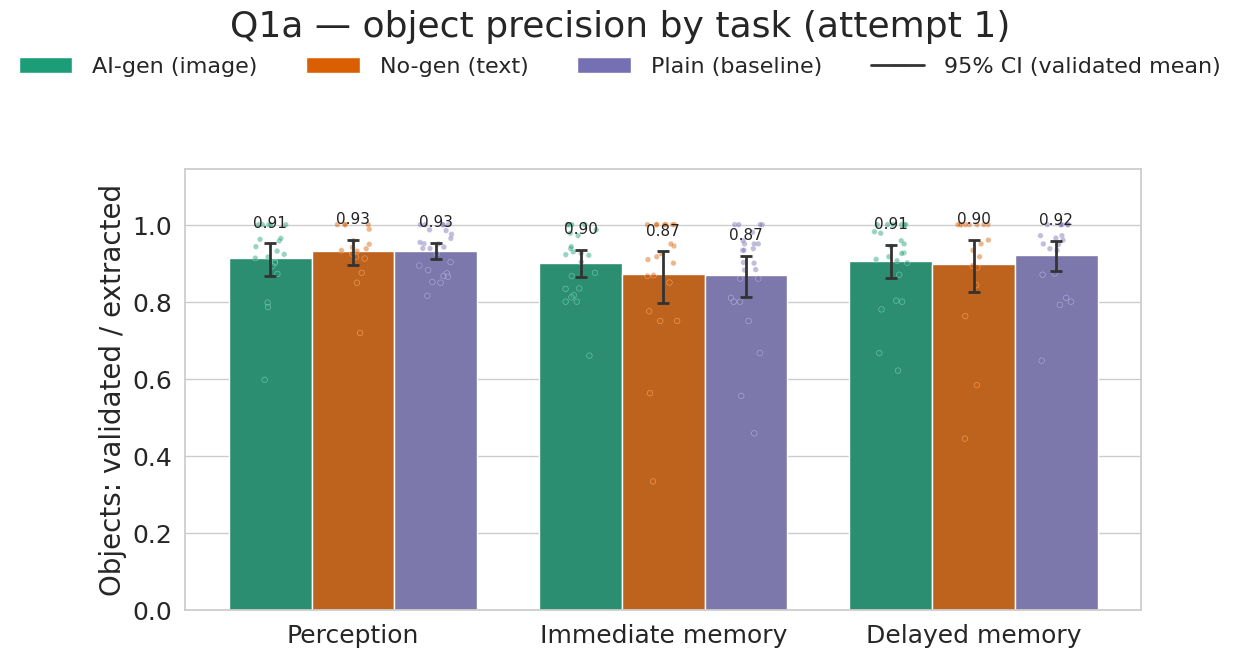

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_precision_all_by_task.png


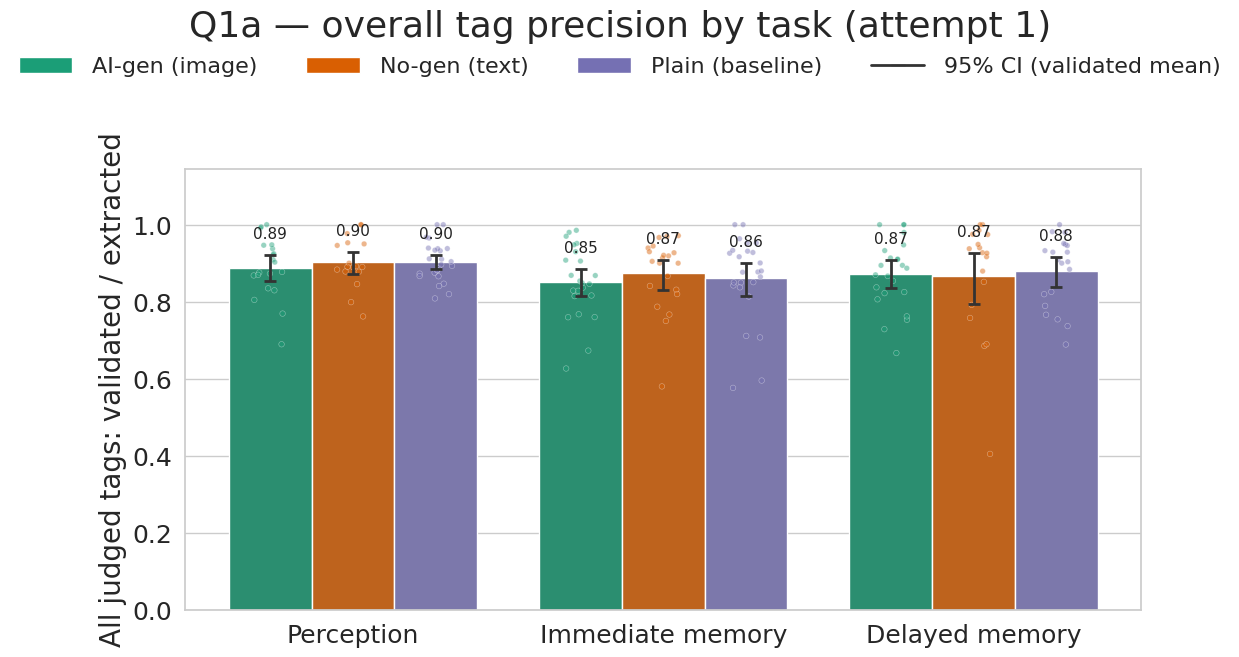

In [8]:
if ceil is not None:
    n_val = sum(ceil[f"n_{c}"].sum() for c in VALIDATED_CATEGORIES)
    n_inv = sum(ceil[f"h_{c}"].sum() for c in VALIDATED_CATEGORIES)
    FLOOR = n_inv / (n_val + n_inv)
    print(f"JUDGE FALSE-POSITIVE FLOOR: {n_inv:.0f}/{n_val + n_inv:.0f} = {100 * FLOOR:.2f}% "
          "of tags rejected in descriptions written WITH the image in view.")
else:
    FLOOR = None

plot_measure_by_task("precision_objects", "Objects: validated / extracted",
                     title="Q1a — object precision by task (attempt 1)",
                     fname="q1a_precision_objects_by_task.png")

plot_measure_by_task("precision_all", "All judged tags: validated / extracted",
                     title="Q1a — overall tag precision by task (attempt 1)",
                     fname="q1a_precision_all_by_task.png")

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_halluc_objects_by_task.png


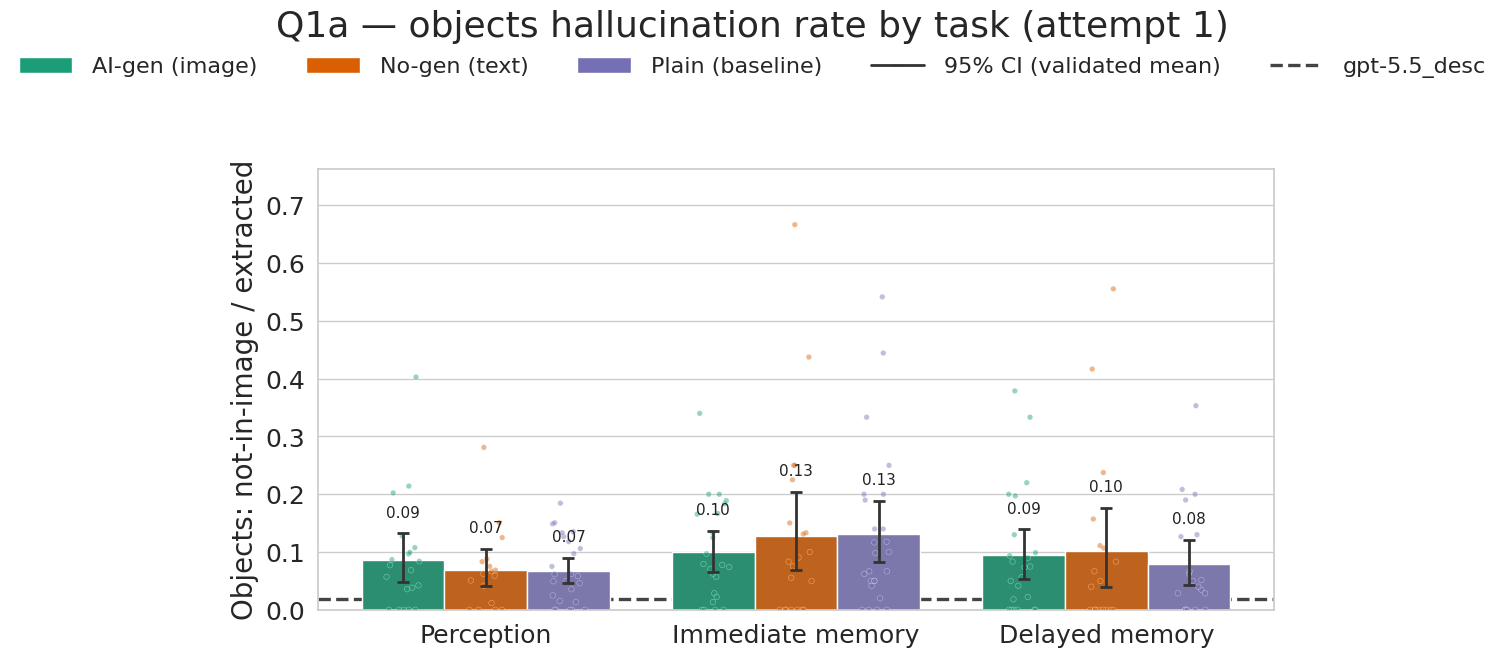

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_halluc_all_by_task.png


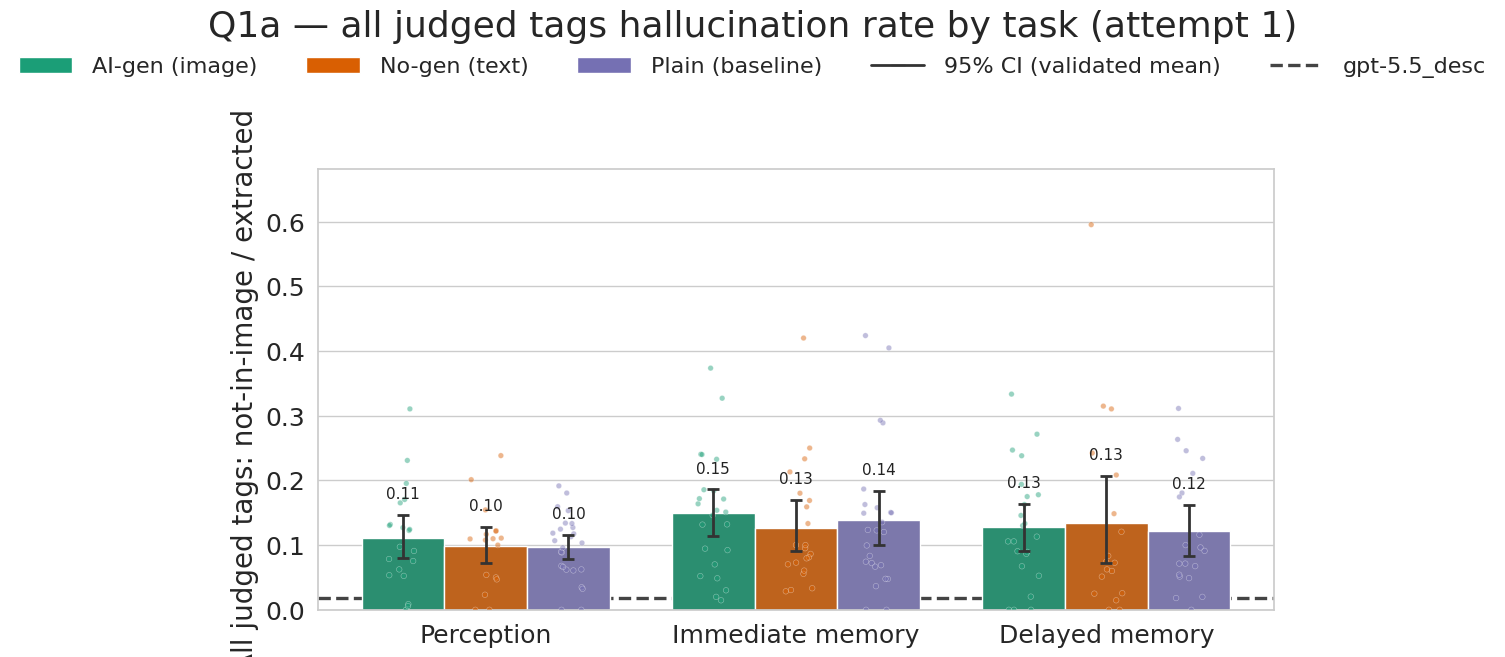

In [9]:
# Hallucination rate, with the judge's floor drawn in - the line these bars are read against.
for measure, label, fname in [
    ("halluc_rate_objects", "Objects: not-in-image / extracted", "q1a_halluc_objects_by_task.png"),
    ("halluc_rate_all", "All judged tags: not-in-image / extracted", "q1a_halluc_all_by_task.png"),
]:
    ppt = (A1.groupby(["generation", "task", "uid"], as_index=False)[measure]
             .mean().dropna(subset=[measure]))
    gens = gens_present(ppt)
    fig, ax = plt.subplots(figsize=(11, 6.8))
    vmax = draw_bars(ax, ppt, "task", TASK_ORDER, "generation", gens, measure, fmt="{:.2f}")
    if FLOOR is not None:
        ax.axhline(FLOOR, color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
    ax.set_xlabel(""); ax.set_ylabel(label)
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t] for t in TASK_ORDER])
    style_count_axis(ax, vmax=vmax)
    fig.suptitle(f"Q1a — {label.split(':')[0].lower()} hallucination rate by task (attempt 1)")
    figure_legend(fig, gens, marker="bar", ci=True, gpt=FLOOR is not None, y=0.94)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    save_fig(fig, GRAPHS / fname)
    plt.show()

### 1.3 How dense — the length control

If perception descriptions contain more objects only because they are longer, the count effect
is about *typing*, not about *access to the scene*. The left panel is length; the right is
validated objects per 100 CLIP tokens. A task difference that survives on the right is a real
density difference.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_length_and_density_by_task.png


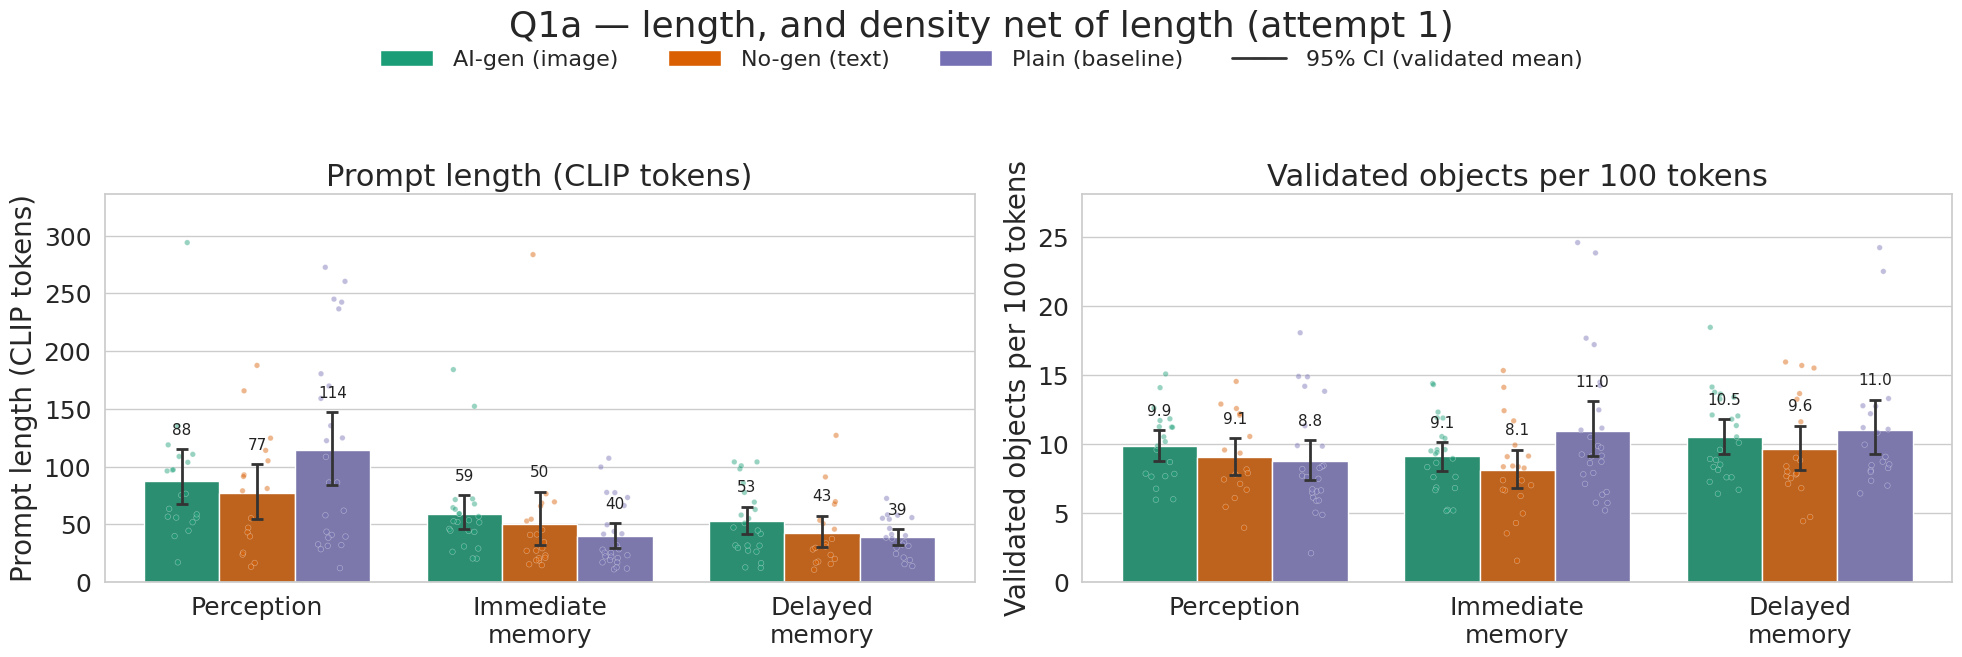

In [10]:
gens = gens_present(A1)
fig, axes = plt.subplots(1, 2, figsize=(20, 6.8))
for ax, (measure, label, fmt) in zip(axes, [
    ("token_num", "Prompt length (CLIP tokens)", "{:.0f}"),
    ("objects_per_100_tok", "Validated objects per 100 tokens", "{:.1f}"),
]):
    ppt = (A1.groupby(["generation", "task", "uid"], as_index=False)[measure]
             .mean().dropna(subset=[measure]))
    vmax = draw_bars(ax, ppt, "task", TASK_ORDER, "generation", gens, measure, fmt=fmt)
    ax.set_xlabel(""); ax.set_ylabel(label); ax.set_title(label)
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t].replace(" ", "\n") for t in TASK_ORDER])
    style_count_axis(ax, vmax=vmax)
fig.suptitle("Q1a — length, and density net of length (attempt 1)")
figure_legend(fig, gens, marker="bar", ci=True, y=0.95)
fig.tight_layout(rect=(0, 0, 1, 0.89))
save_fig(fig, GRAPHS / "q1a_length_and_density_by_task.png")
plt.show()

### 1.4 Ceiling-normalised objects

Validated object count divided by what GPT extracts from that same image while looking at it.
1.0 would mean a participant matched the ceiling. This is the version of §1.1 that is not
dominated by which images happen to be object-rich.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_ceiling_fraction_by_task.png


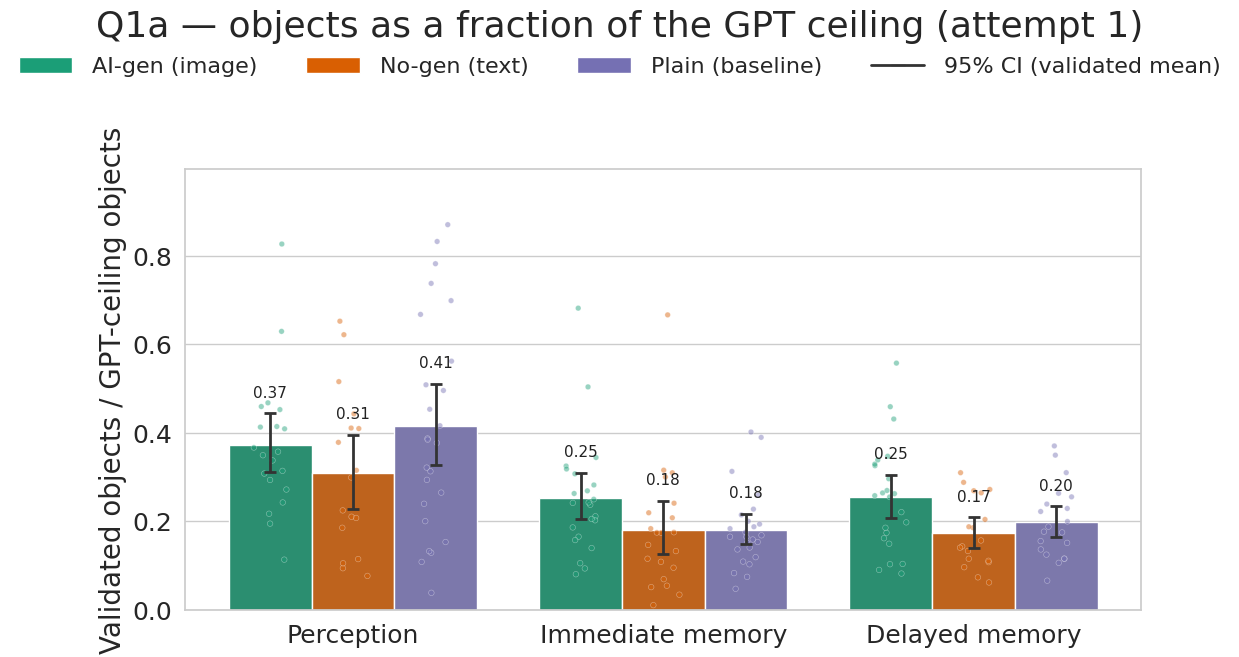

In [11]:
plot_measure_by_task("ceil_frac_objects", "Validated objects / GPT-ceiling objects",
                     title="Q1a — objects as a fraction of the GPT ceiling (attempt 1)",
                     fname="q1a_ceiling_fraction_by_task.png")

### 1.5 The images themselves

The same comparison on the generated pictures rather than the words. Both similarity metrics
are oriented so higher = closer to the target. `subjective_score` exists only for **aigen** —
it is the participant's rating of an image they were actually shown — so that panel is one arm
by construction.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_similarity_by_task.png


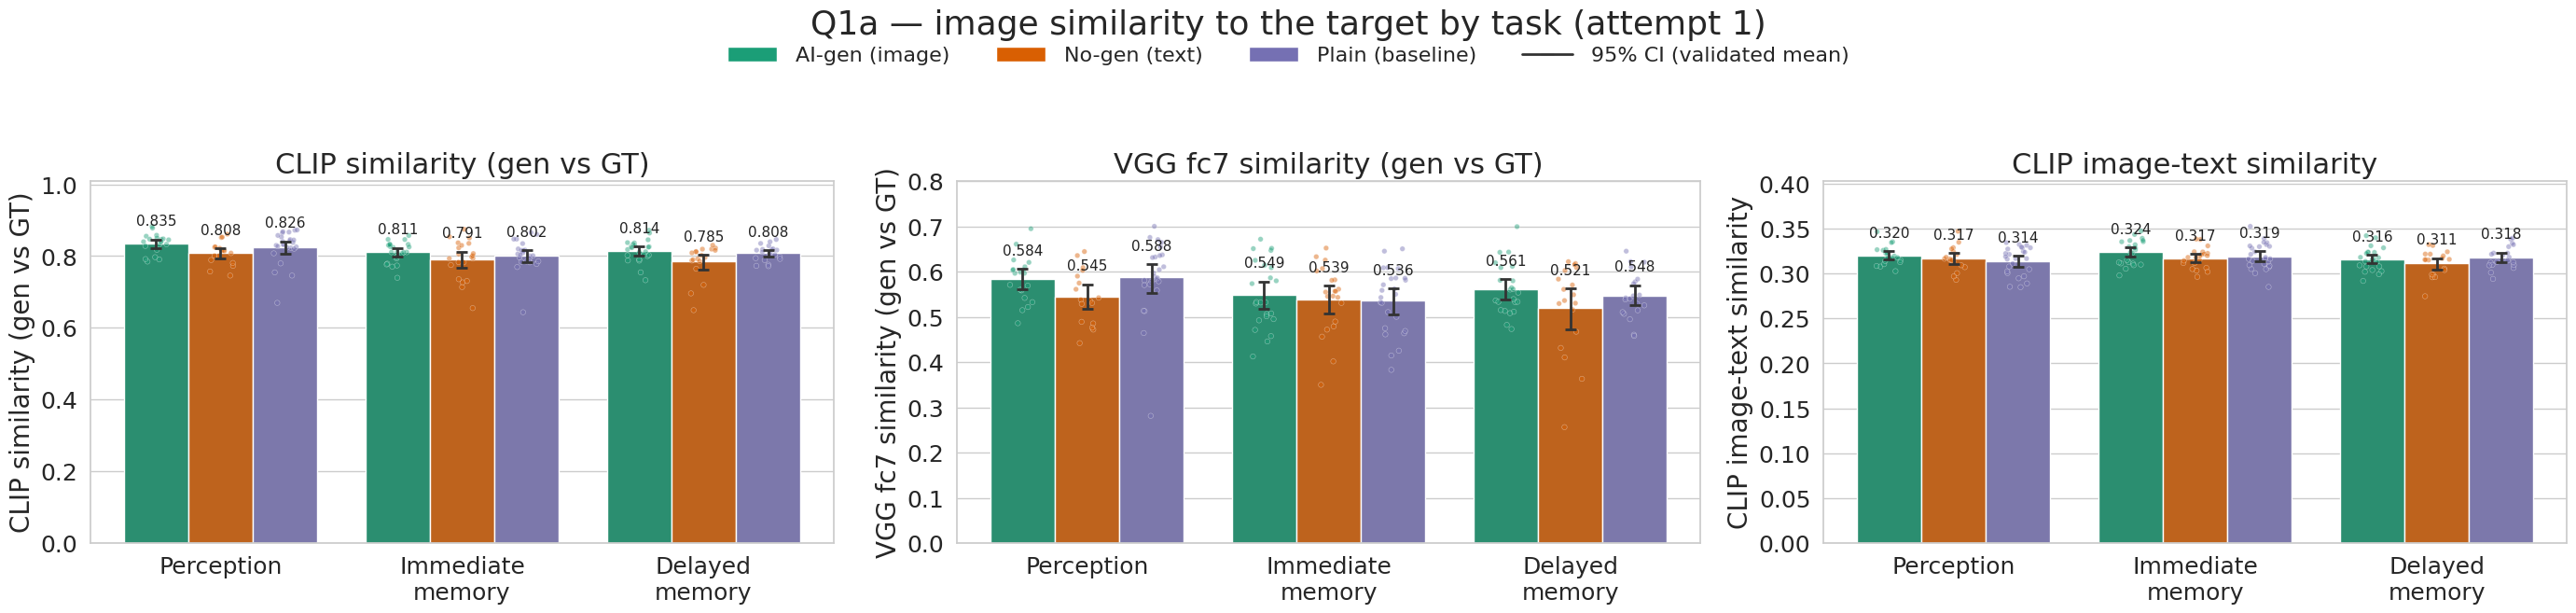

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1a_subjective_by_task.png


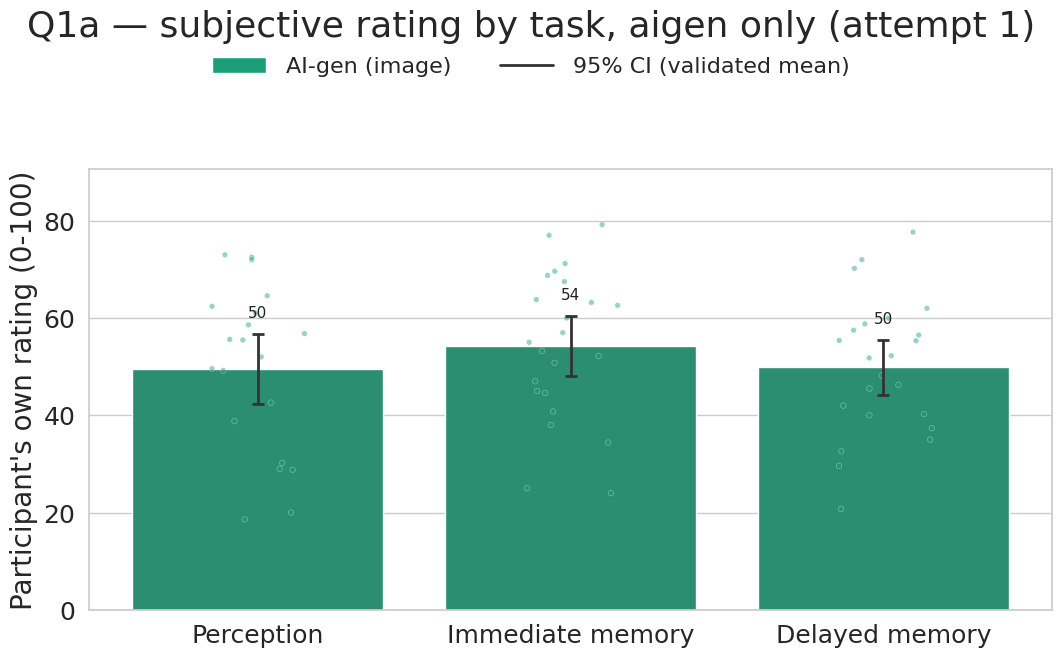

In [12]:
gens = gens_present(A1)
fig, axes = plt.subplots(1, 3, figsize=(28, 6.8))
for ax, (measure, label, fmt) in zip(axes, [
    ("clip_similarity", "CLIP similarity (gen vs GT)", "{:.3f}"),
    ("vgg_similarity", "VGG fc7 similarity (gen vs GT)", "{:.3f}"),
    ("clip_vis_text_similarity", "CLIP image-text similarity", "{:.3f}"),
]):
    ppt = (A1.groupby(["generation", "task", "uid"], as_index=False)[measure]
             .mean().dropna(subset=[measure]))
    vmax = draw_bars(ax, ppt, "task", TASK_ORDER, "generation", gens, measure, fmt=fmt)
    ax.set_xlabel(""); ax.set_ylabel(label); ax.set_title(label)
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t].replace(" ", "\n") for t in TASK_ORDER])
    style_count_axis(ax, vmax=vmax)
fig.suptitle("Q1a — image similarity to the target by task (attempt 1)")
figure_legend(fig, gens, marker="bar", ci=True, y=0.95)
fig.tight_layout(rect=(0, 0, 1, 0.89))
save_fig(fig, GRAPHS / "q1a_similarity_by_task.png")
plt.show()

plot_measure_by_task("subjective_score", "Participant's own rating (0-100)",
                     gens=["aigen"], fmt="{:.0f}",
                     title="Q1a — subjective rating by task, aigen only (attempt 1)",
                     fname="q1a_subjective_by_task.png")

---
# 2. Q1b — does the feedback allow improvement across attempts?

**aigen + nogen only.** `plain` has a single attempt by design and is absent from this section
rather than drawn as empty slots.

Attempt is *within* participant, so this section uses the paired views that the
group-mean-over-attempts figures elsewhere cannot give: how many individual participants
actually improve, and by how much.

In [8]:
FB = df[df["generation"].isin(FB_GENS)].copy()

# One value per participant per attempt (collapsing their 5 images), then the 3-1 delta.
# Only participants present at BOTH attempts contribute - a delta needs its own baseline.
def attempt_table(measure, data=None, gens=FB_GENS):
    d = (FB if data is None else data)
    d = d[d["generation"].isin(gens)]
    return (d.groupby(["generation", "task", "uid", "attempt"], as_index=False)[measure]
             .mean().dropna(subset=[measure]))


def delta_table(measure, data=None, gens=FB_GENS, a_from=1, a_to=3):
    t = attempt_table(measure, data, gens)
    w = t.pivot_table(index=["generation", "task", "uid"], columns="attempt",
                      values=measure)
    w = w.dropna(subset=[a_from, a_to])
    out = w.reset_index()[["generation", "task", "uid"]]
    out["delta"] = (w[a_to] - w[a_from]).values
    out["start"] = w[a_from].values
    return out


DELTA_MEASURES = [
    ("n_in_image_objects", "Validated objects", "{:.2f}"),
    ("n_not_in_image_objects", "Hallucinated objects", "{:.2f}"),
    ("precision_objects", "Object precision", "{:.3f}"),
    ("clip_similarity", "CLIP similarity to GT", "{:.4f}"),
]

### 2.1 Per-participant change, attempt 1 → attempt 3

Each dot is one participant's own change. The zero line is the thing to read against: a group
mean can rise while most participants sit still and a few move a lot, and only this view shows
which. The number printed under each cell is the **share of participants above zero**.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1b_participant_deltas.png


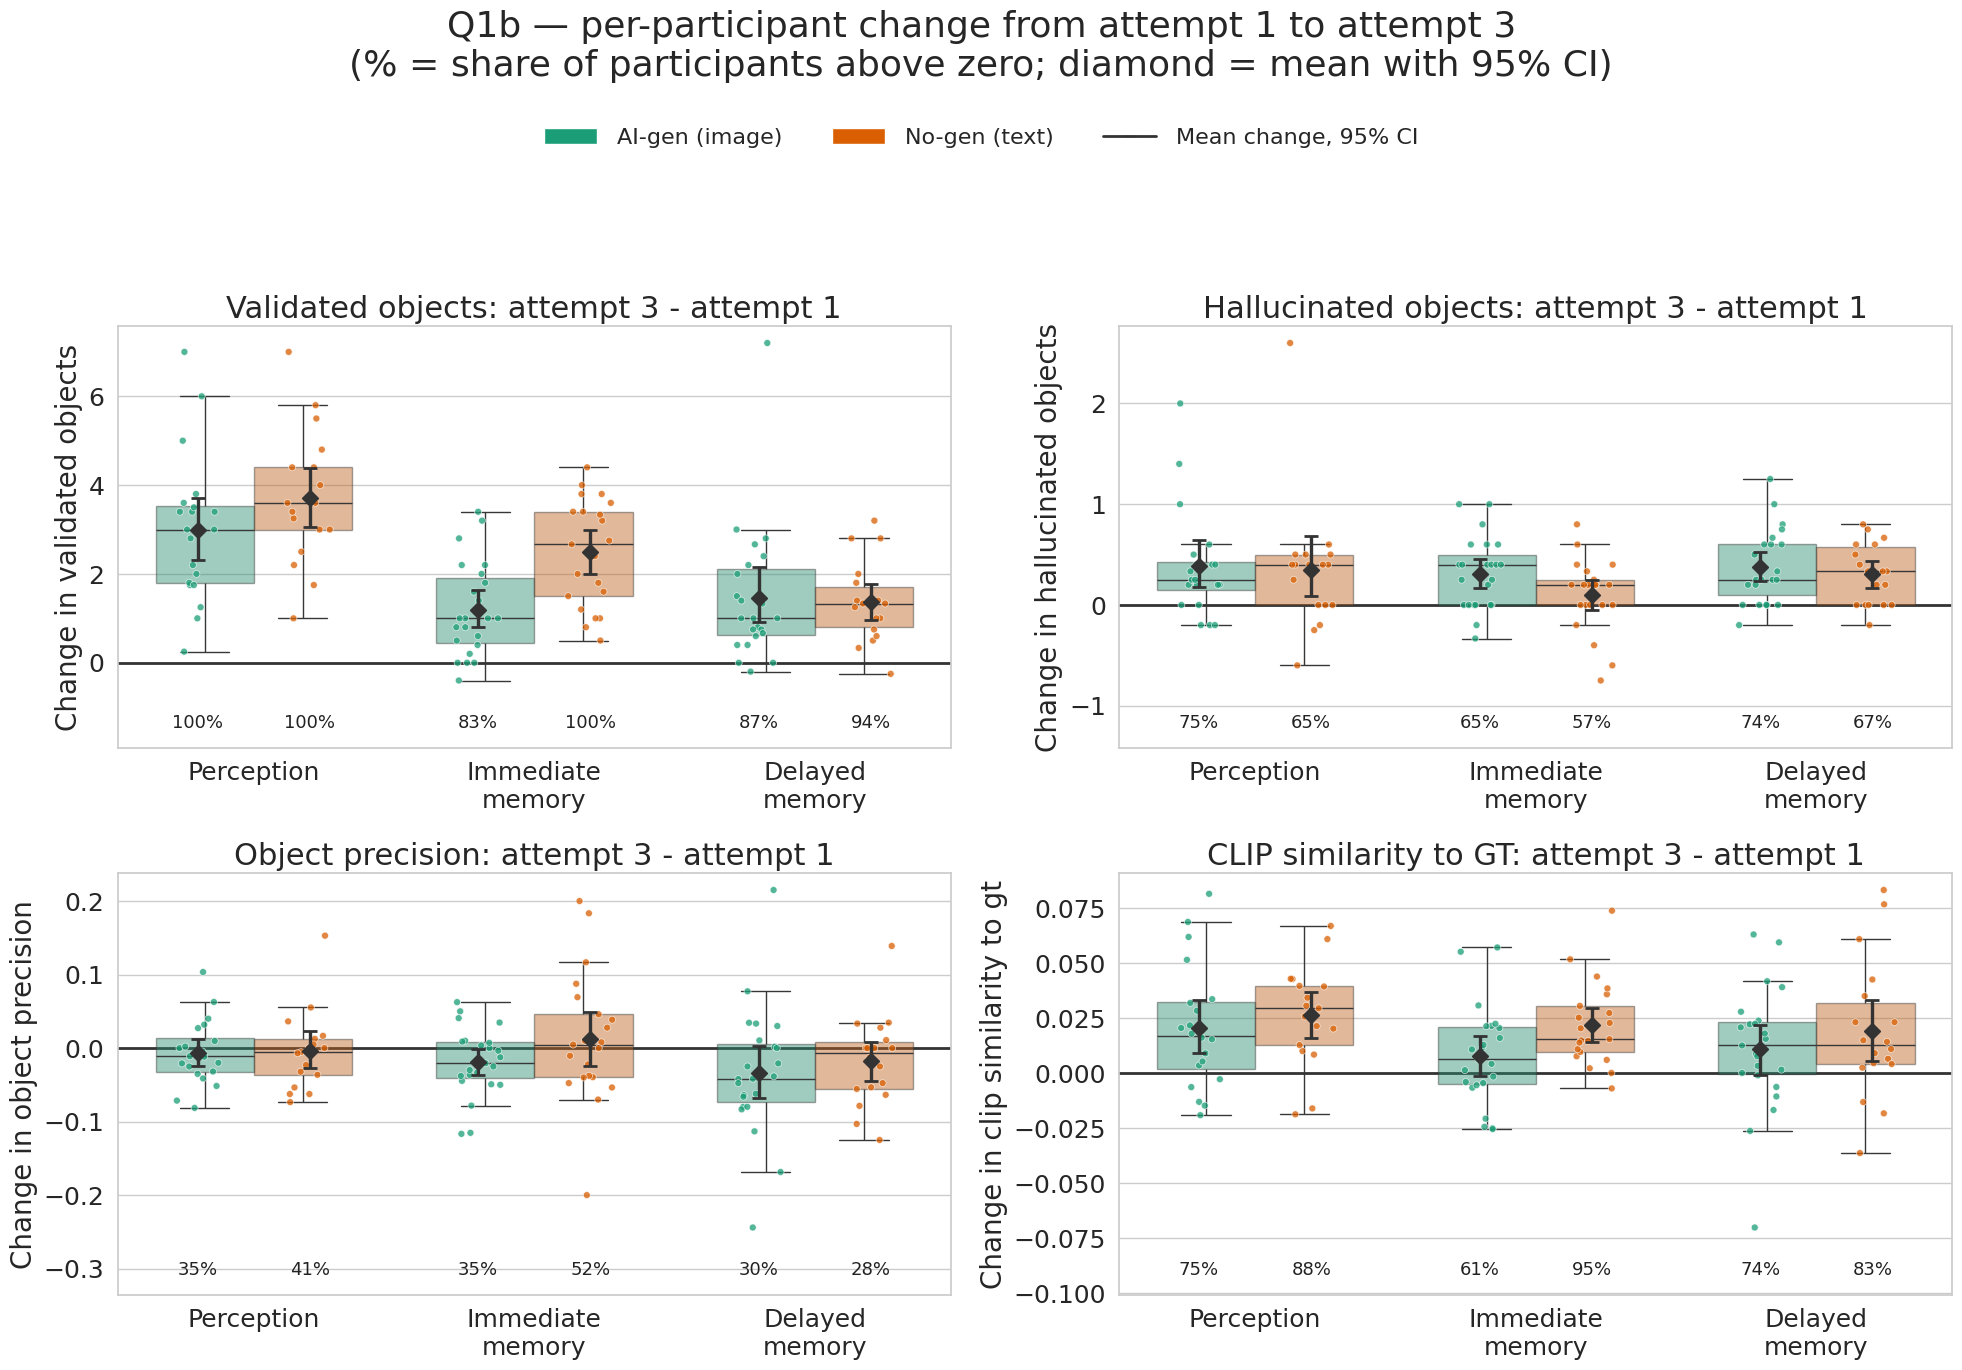

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
for ax, (measure, label, fmt) in zip(axes.ravel(), DELTA_MEASURES):
    d = delta_table(measure)
    if d.empty:
        ax.set_visible(False)
        continue
    sns.boxplot(data=d, x="task", y="delta", hue="generation", order=TASK_ORDER,
                hue_order=FB_GENS, palette=GEN_COLORS, showfliers=False, width=0.7,
                boxprops=dict(alpha=0.45), legend=False, ax=ax, zorder=2)
    sns.stripplot(data=d, x="task", y="delta", hue="generation", order=TASK_ORDER,
                  hue_order=FB_GENS, palette=GEN_COLORS, dodge=True, jitter=0.16,
                  size=5, alpha=0.75, linewidth=0.5, edgecolor="white", legend=False,
                  ax=ax, zorder=3)
    ax.axhline(0, color="#333333", lw=2, ls="-", zorder=1)

    # Mean delta with a bootstrap CI, plus the share of participants who improved at all.
    offsets, _ = geom(FB_GENS)
    lo_y = d["delta"].min()
    span = d["delta"].max() - lo_y
    for i, task in enumerate(TASK_ORDER):
        for g in FB_GENS:
            v = d[(d["task"] == task) & (d["generation"] == g)]["delta"]
            if len(v) < 2:
                continue
            lo, hi = boot_ci(v)
            ax.errorbar(i + offsets[g], v.mean(), yerr=[[v.mean() - lo], [hi - v.mean()]],
                        fmt="D", color=CI_COLOR, markersize=8, capsize=5, capthick=2,
                        elinewidth=2.4, zorder=5)
            ax.text(i + offsets[g], lo_y - 0.10 * span, f"{100 * (v > 0).mean():.0f}%",
                    ha="center", va="top", fontsize=13, color=BAR_LABEL_COLOR)
    ax.set_ylim(lo_y - 0.20 * span, None)
    ax.set_title(f"{label}: attempt 3 - attempt 1")
    ax.set_xlabel(""); ax.set_ylabel(f"Change in {label.lower()}")
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t].replace(" ", "\n") for t in TASK_ORDER])

fig.suptitle("Q1b — per-participant change from attempt 1 to attempt 3\n"
             "(% = share of participants above zero; diamond = mean with 95% CI)", y=0.985)
figure_legend(fig, FB_GENS, marker="bar", ci="Mean change, 95% CI", y=0.915)
fig.tight_layout(rect=(0, 0, 1, 0.875))
save_fig(fig, GRAPHS / "q1b_participant_deltas.png")
plt.show()

### 2.2 The trajectories themselves

Every thin line is one participant across their three attempts; the bold line is the group mean
with a bootstrap CI. This shows whether a mean increase is a broad shift or a few large movers,
and whether the two feedback types have different shapes.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1b_slopes_n_validated_objects.png


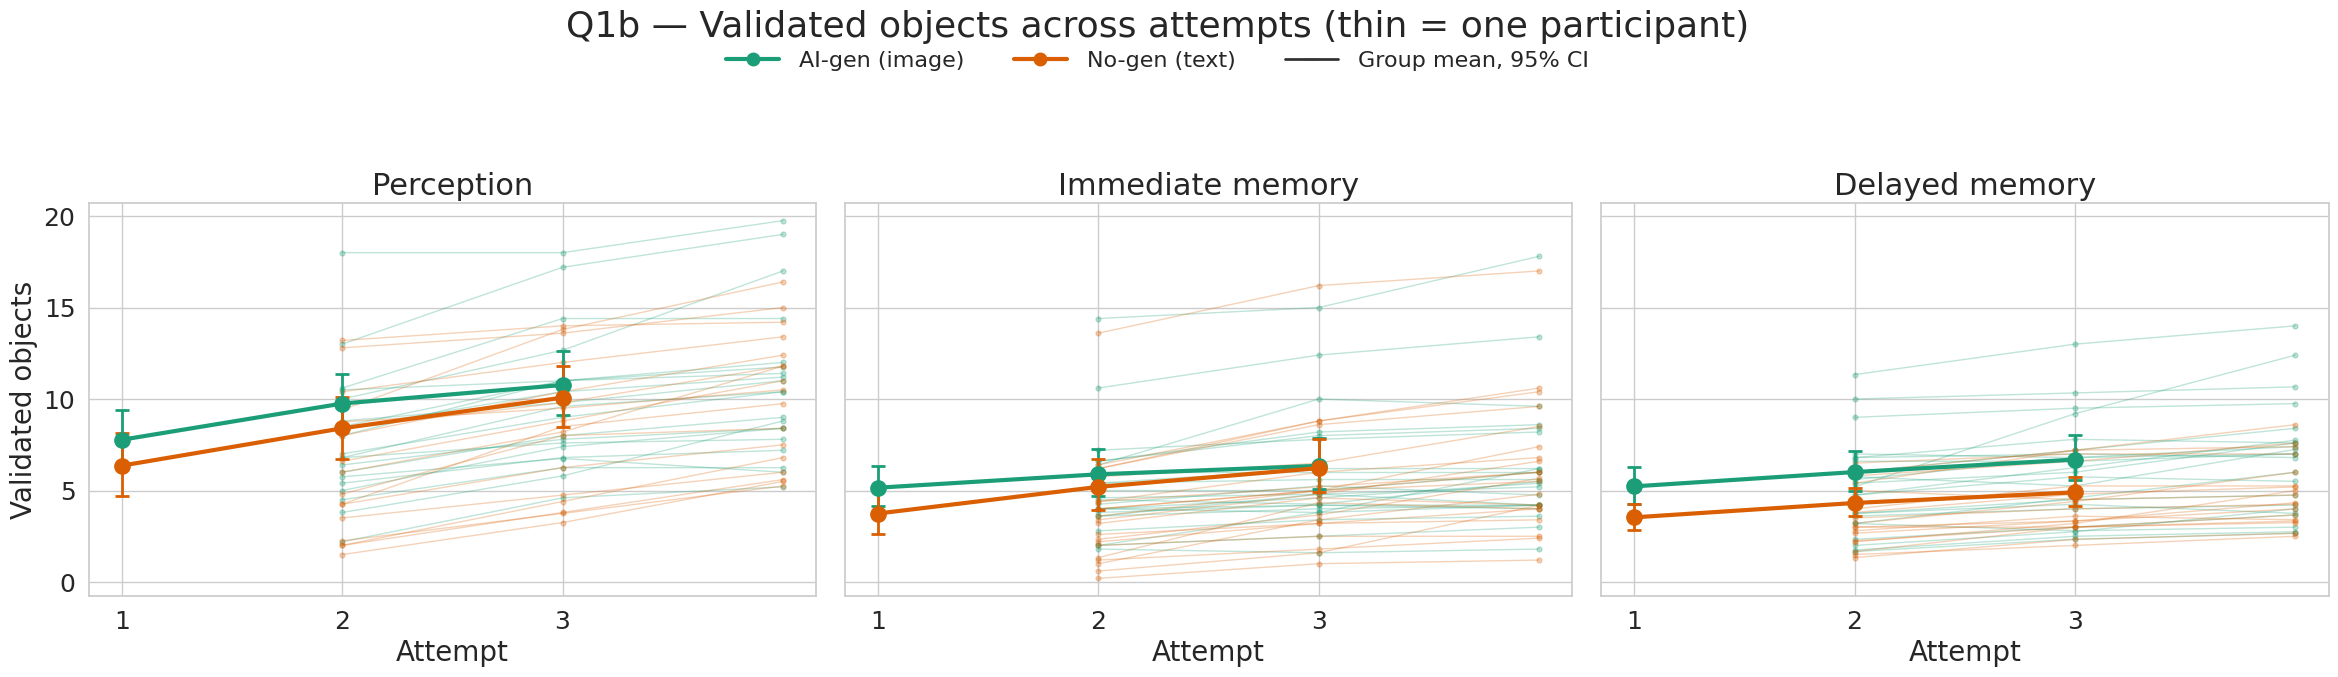

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1b_slopes_n_invalid_not_in_image_objects.png


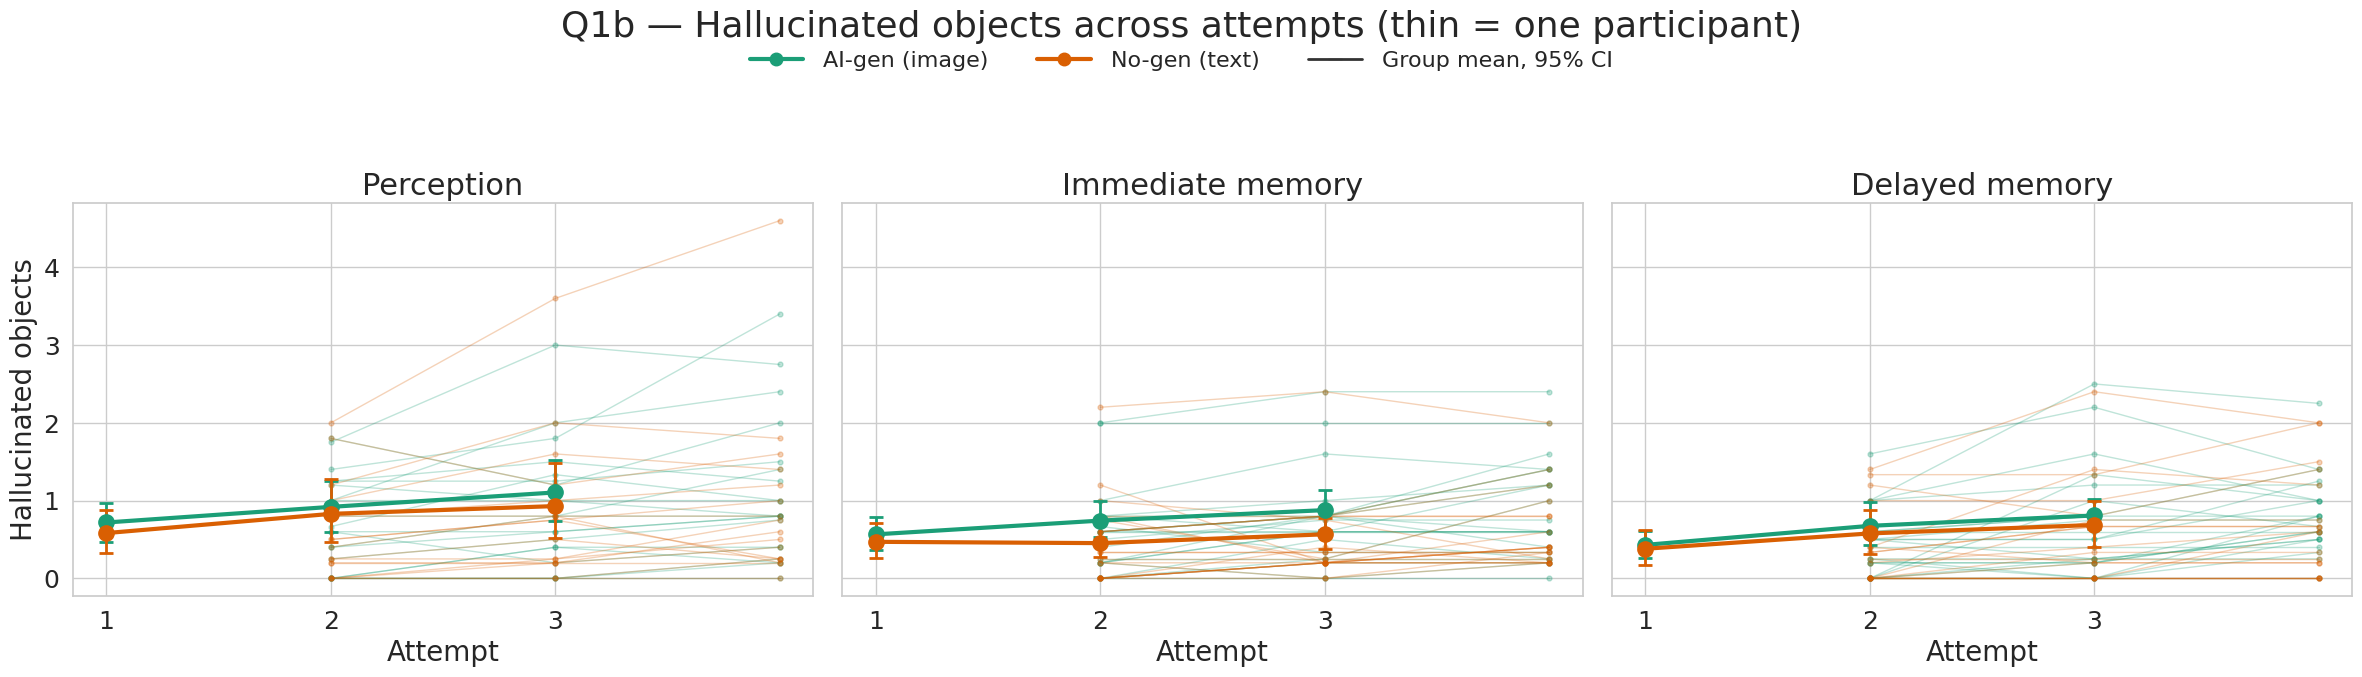

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1b_slopes_clip_similarity.png


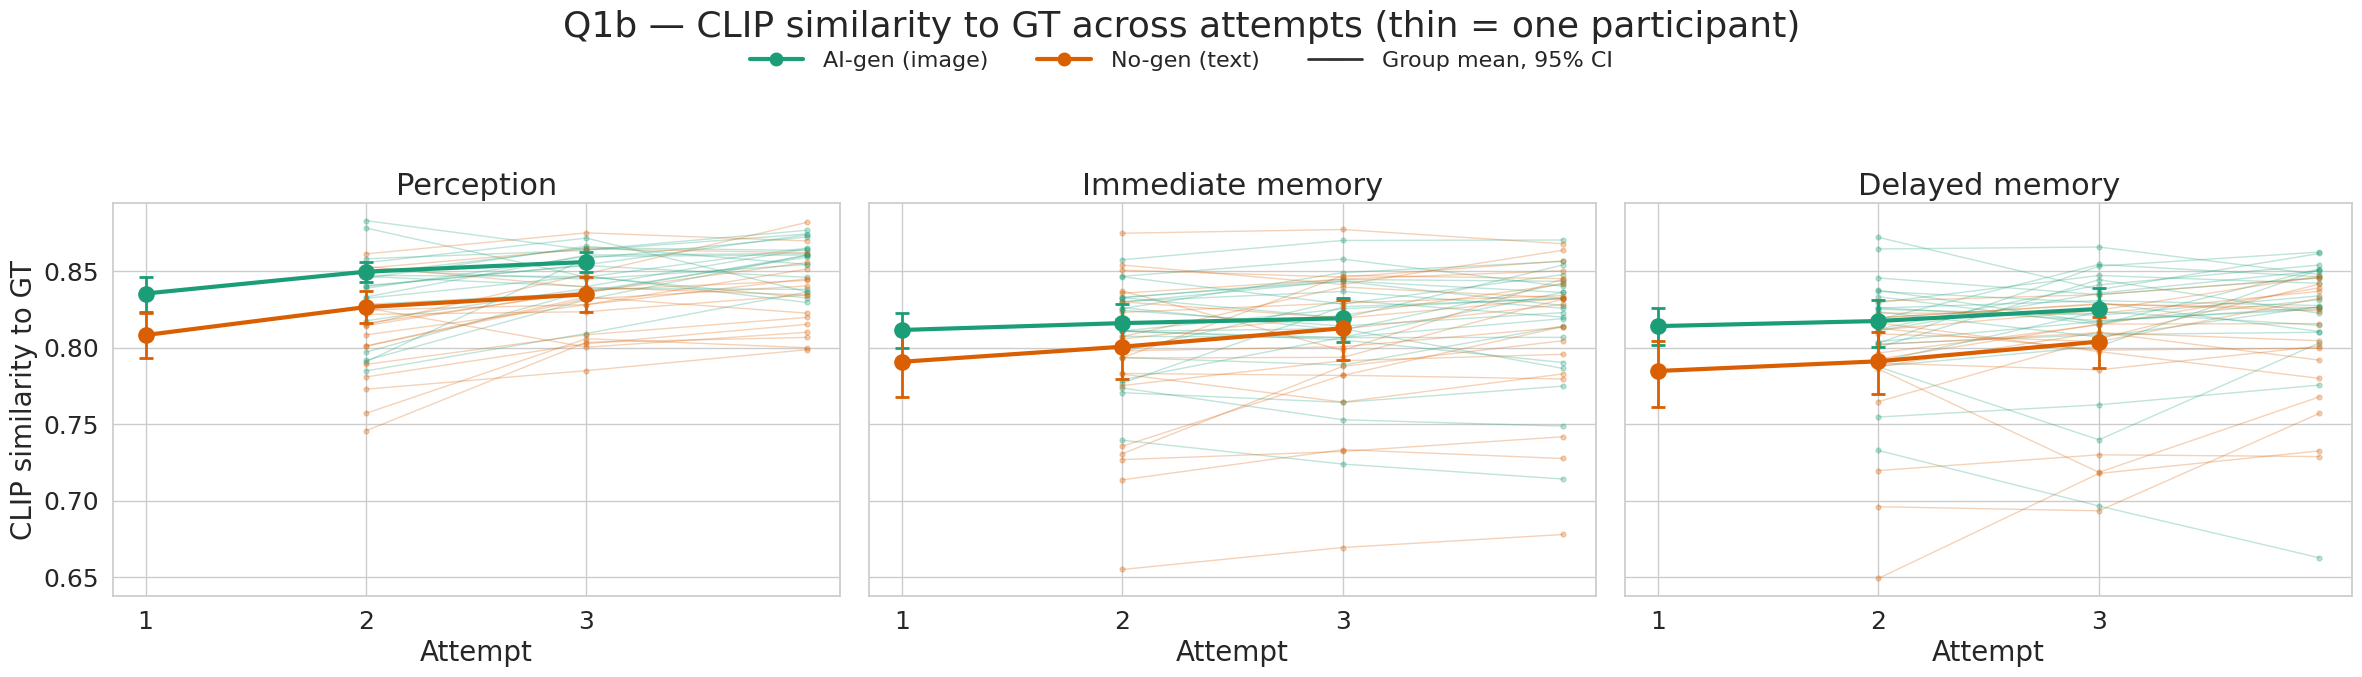

In [15]:
for measure, label, fmt in DELTA_MEASURES[:2] + [DELTA_MEASURES[3]]:
    t = attempt_table(measure)
    fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharey=True)
    for ax, task in enumerate_tasks(axes):
        sub = t[t["task"] == task]
        for g in FB_GENS:
            s = sub[sub["generation"] == g]
            for _, grp in s.groupby("uid"):
                grp = grp.sort_values("attempt")
                ax.plot(grp["attempt"], grp[measure], color=GEN_COLORS[g], lw=1.0,
                        alpha=0.28, marker="o", markersize=3.5, zorder=2)
        draw_lines(ax, sub, "attempt", ATTEMPTS, "generation", FB_GENS, measure)
        ax.set_xticklabels(ATTEMPTS)
        ax.set_title(TASK_LABELS[task]); ax.set_xlabel("Attempt")
        ax.set_ylabel(label if ax is axes[0] else "")
    fig.suptitle(f"Q1b — {label} across attempts (thin = one participant)")
    figure_legend(fig, FB_GENS, marker="o", ci="Group mean, 95% CI", y=0.95)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    save_fig(fig, GRAPHS / f"q1b_slopes_{measure}.png")
    plt.show()

### 2.3 Does *image* feedback beat *text* feedback?

The delta from §2.1, as bars. If seeing the generated image is doing work beyond simply
re-reading your own words, aigen's change should exceed nogen's. A CI crossing zero means that
measure did not move at all in that cell.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q1b_aigen_vs_nogen_delta.png


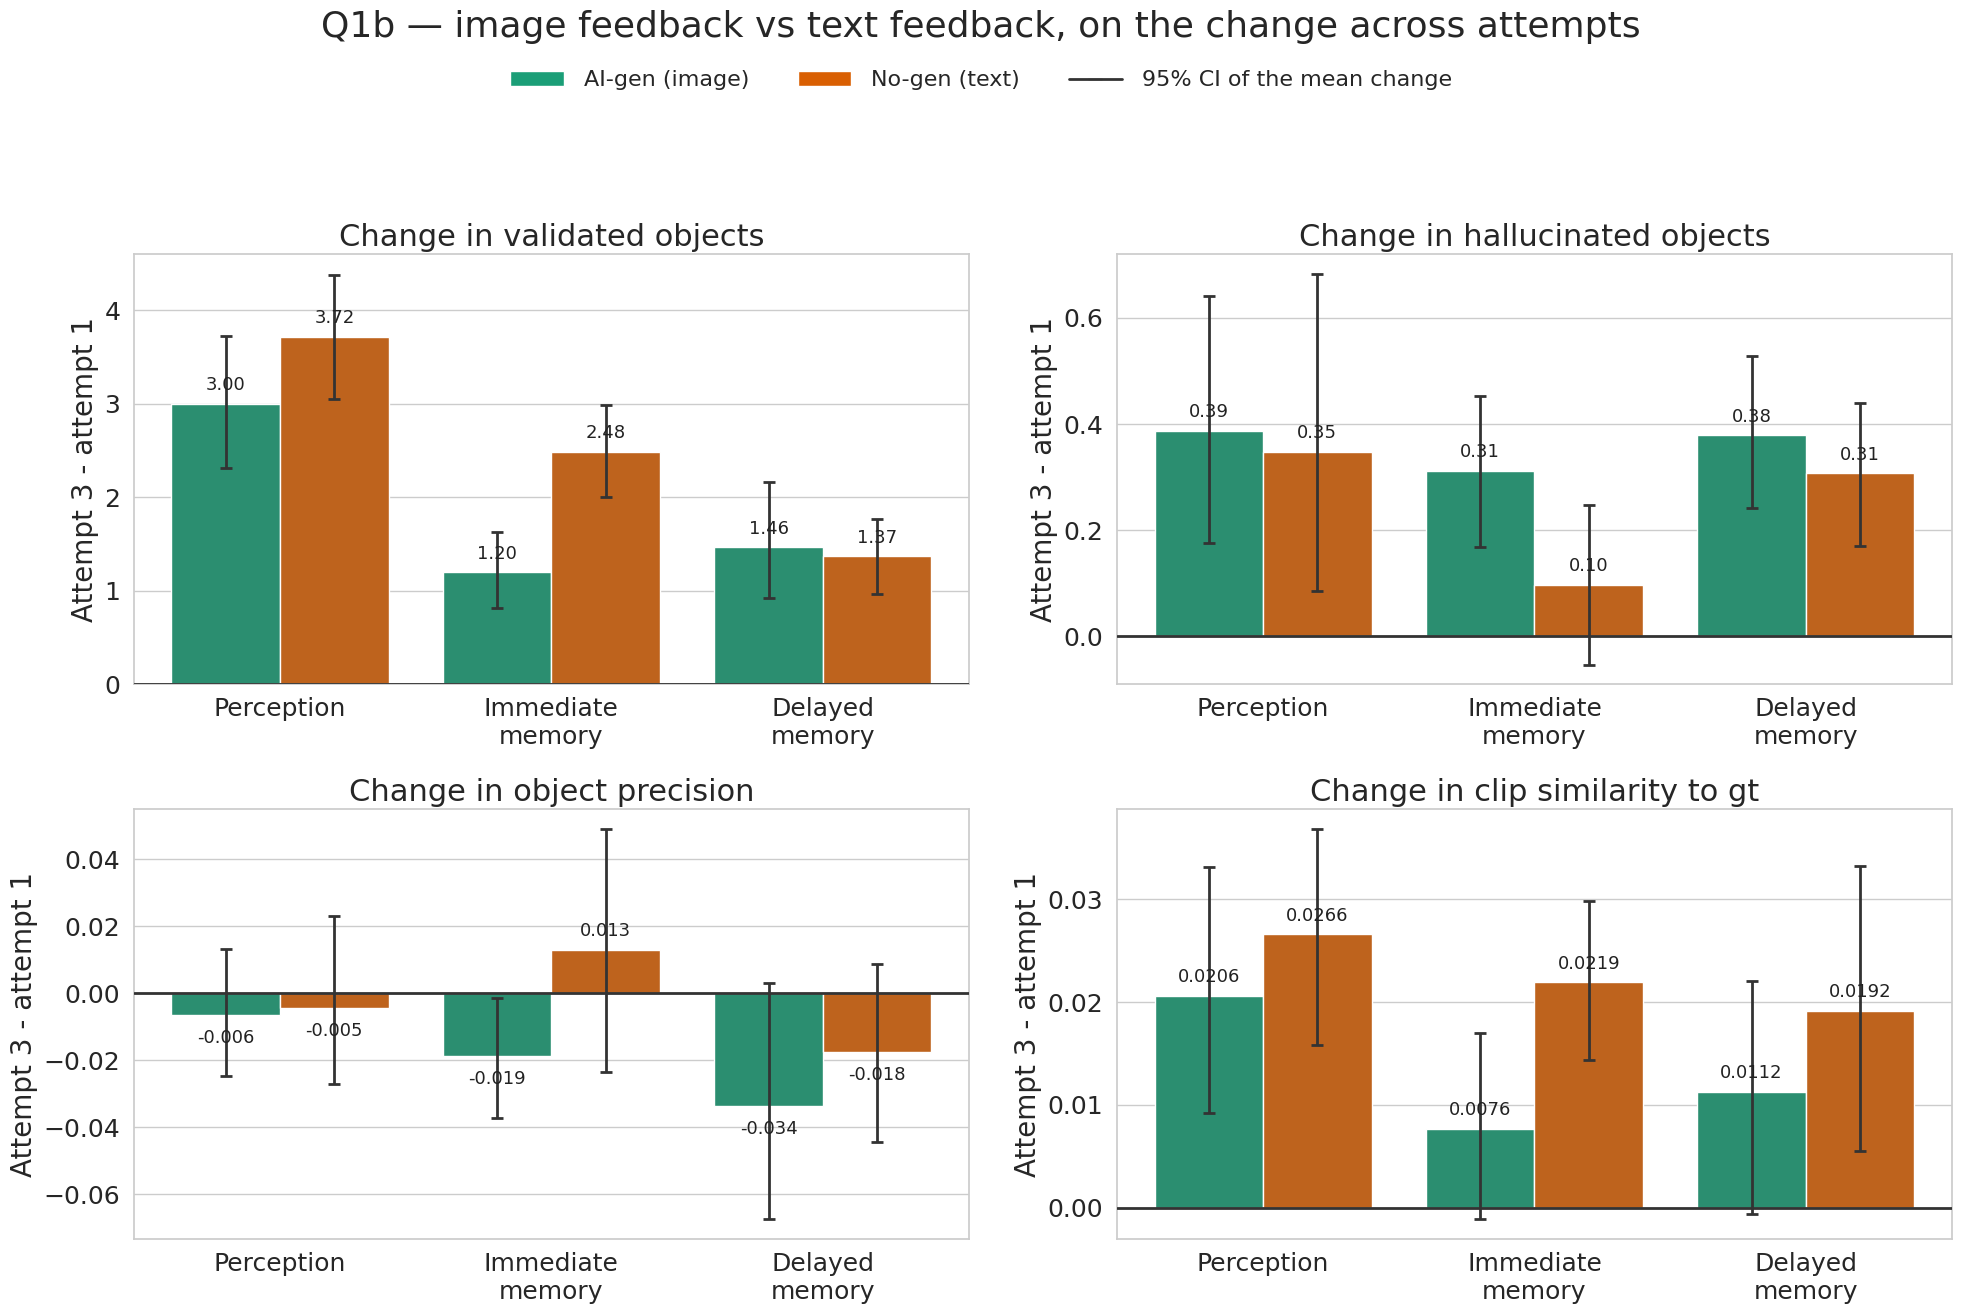

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(20, 13.5))
for ax, (measure, label, fmt) in zip(axes.ravel(), DELTA_MEASURES):
    d = delta_table(measure)
    if d.empty:
        ax.set_visible(False)
        continue
    sns.barplot(data=d, x="task", y="delta", hue="generation", order=TASK_ORDER,
                hue_order=FB_GENS, palette=GEN_COLORS, errorbar=None, legend=False,
                ax=ax, zorder=2)
    g_ = geom(FB_GENS)
    add_ci(ax, {t: i for i, t in enumerate(TASK_ORDER)}, FB_GENS, d,
           "task", "generation", "delta", g_)
    ax.axhline(0, color="#333333", lw=2, zorder=4)
    offsets, _ = g_
    for i, task in enumerate(TASK_ORDER):
        for gg in FB_GENS:
            v = d[(d["task"] == task) & (d["generation"] == gg)]["delta"]
            if len(v):
                ax.annotate(fmt.format(v.mean()), (i + offsets[gg], v.mean()),
                            textcoords="offset points", xytext=(0, 10 if v.mean() >= 0 else -20),
                            ha="center", fontsize=13, color=BAR_LABEL_COLOR, zorder=6)
    ax.set_title(f"Change in {label.lower()}")
    ax.set_xlabel(""); ax.set_ylabel("Attempt 3 - attempt 1")
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t].replace(" ", "\n") for t in TASK_ORDER])
fig.suptitle("Q1b — image feedback vs text feedback, on the change across attempts")
figure_legend(fig, FB_GENS, marker="bar", ci="95% CI of the mean change", y=0.95)
fig.tight_layout(rect=(0, 0, 1, 0.89))
save_fig(fig, GRAPHS / "q1b_aigen_vs_nogen_delta.png")
plt.show()

### 2.4 Does the added content hold up?

The count going up is only progress if what was added is actually in the image. Solid = mean
validated objects, hollow cap = mean rejected objects, over the three attempts. If the cap
grows in step with the bar, the extra attempts are buying elaboration rather than accuracy.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharey=True)
for ax, task in enumerate_tasks(axes):
    sub = FB[FB["task"] == task]
    ppt = ppt_means(sub, ["generation", "uid", "attempt"], "objects")
    vmax = draw_bars(ax, ppt, "attempt", ATTEMPTS, "generation", FB_GENS, "count",
                     cap_col="cap", fmt="{:.1f}")
    if "objects" in GPT_MEAN:
        ax.axhline(GPT_MEAN["objects"], color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
        vmax = max(vmax, GPT_MEAN["objects"] * 1.09)
    ax.set_title(TASK_LABELS[task]); ax.set_xlabel("Attempt")
    ax.set_ylabel("Mean objects (per participant)" if ax is axes[0] else "")
    style_count_axis(ax, vmax=vmax)
fig.suptitle("Q1b — validated vs hallucinated objects over attempts")
figure_legend(fig, FB_GENS, marker="bar", caps=True, ci=True, gpt=bool(GPT_MEAN), y=0.95)
fig.tight_layout(rect=(0, 0, 1, 0.88))
save_fig(fig, GRAPHS / "q1b_validated_vs_hallucinated_over_attempts.png")
plt.show()

---
# 3. Q2 — did immediate and delayed fail to differ because the images are too memorable?

Adva's hypothesis: 4 of the 5 GT images are **high**-memorability (`_h`), so a delay of a few
minutes costs nothing and the immediate-vs-delayed contrast is floored. `bedroom_l` is the only
**low**-memorability image, so it is the place a delay effect should show up if the hypothesis
is right.

> **Read this section as hypothesis-generating, not as a test.** There is exactly one image in
> the low group, so "low memorability" and "is the bedroom" are perfectly confounded. Anything
> found here is a reason to run more low-memorability images, not a result.

### 3.1 The confound check, first

Before reading any bedroom effect: is `bedroom_l` different from the other four in ways that
have nothing to do with memorability? These are the two objective inventories of scene content
— what GPT extracts while looking at each image, and what LabelMe annotators drew polygons
around. If `bedroom_l` is simply the richest scene, a larger number of objects reported for it
is about content, not memory.

,gpt_ceiling_objects,labelme_object_types,memorability
gt,,,
bedroom_l.jpg,27,19,low
living_room_h.jpg,19,12,high
conference_room_h.jpg,18,17,high
lighthouse_h.jpg,25,9,high
playground_h.jpg,16,8,high


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_scene_richness_per_gt.png


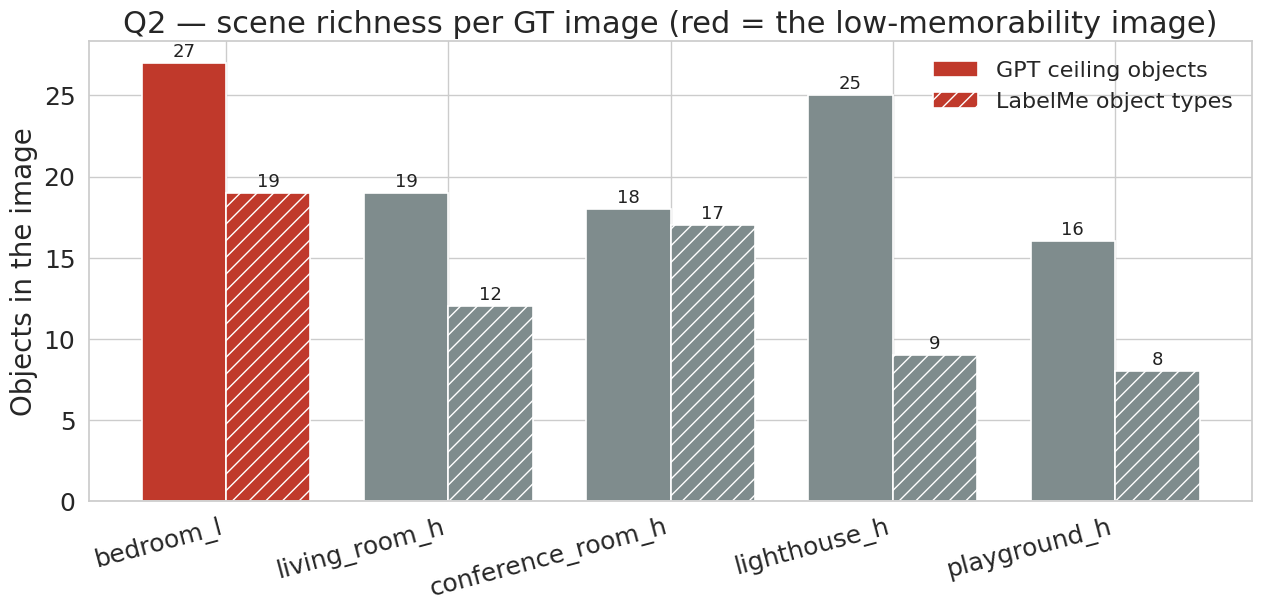

In [11]:
lm_counts = lm.groupby("gt").size().rename("labelme_object_types")
ceil_counts = ceil.set_index("gt")["n_objects"].rename("gpt_ceiling_objects")
richness = pd.concat([ceil_counts, lm_counts], axis=1).reindex(GT_ORDER)
richness["memorability"] = [MEMORABILITY[g] for g in richness.index]
display(richness)

fig, ax = plt.subplots(figsize=(13, 6.5))
x = np.arange(len(GT_ORDER))
w = 0.38
bar_colors = ["#c0392b" if MEMORABILITY[g] == "low" else "#7f8c8d" for g in GT_ORDER]
for k, (col, hatch, lab) in enumerate([("gpt_ceiling_objects", None, "GPT ceiling objects"),
                                       ("labelme_object_types", "//", "LabelMe object types")]):
    ax.bar(x + (k - 0.5) * w, richness[col], width=w, color=bar_colors, hatch=hatch,
           edgecolor="white", linewidth=1.2, label=lab)
    for xi, v in zip(x + (k - 0.5) * w, richness[col]):
        ax.text(xi, v + 0.4, f"{v:.0f}", ha="center", fontsize=13, color=BAR_LABEL_COLOR)
ax.set_xticks(x)
ax.set_xticklabels([GT_LABELS[g] for g in GT_ORDER], rotation=15, ha="right")
ax.set_ylabel("Objects in the image")
ax.set_title("Q2 — scene richness per GT image (red = the low-memorability image)")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
save_fig(fig, GRAPHS / "q2_scene_richness_per_gt.png")
plt.show()

### 3.2 Each image on its own

Validated objects at attempt 1, one panel per GT image. The prediction is narrow and specific:
an **immediate → delayed drop in the `bedroom_l` panel and flat lines in the other four**. The
bedroom panel is drawn first and framed so it is read against its neighbours.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_objects_by_task_per_gt.png


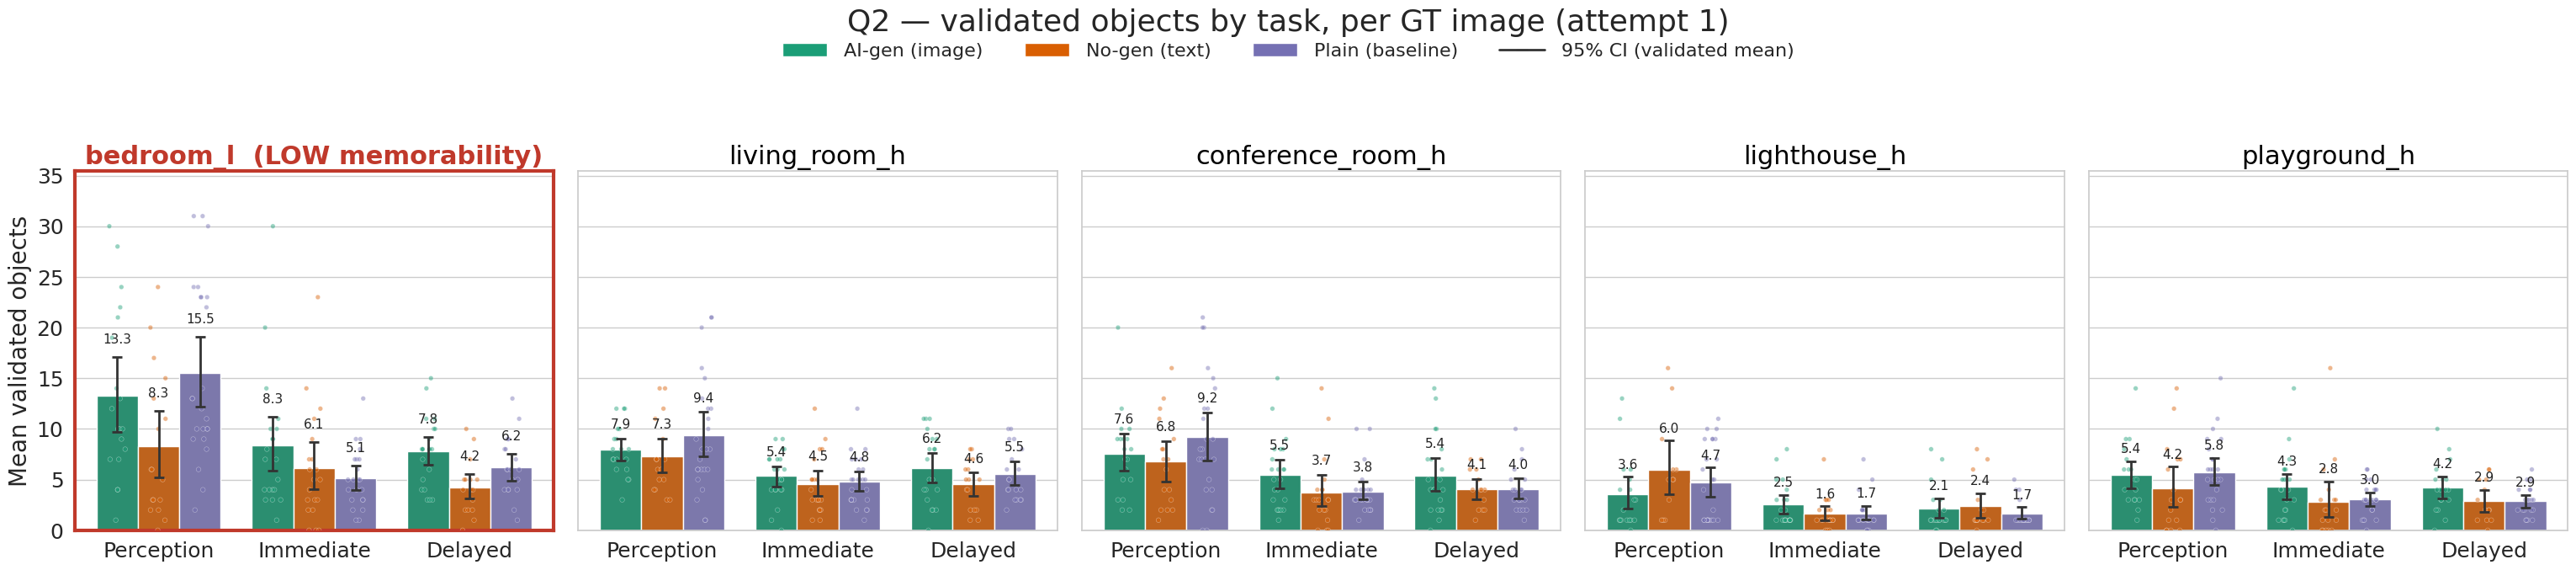

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_ceiling_fraction_by_task_per_gt.png


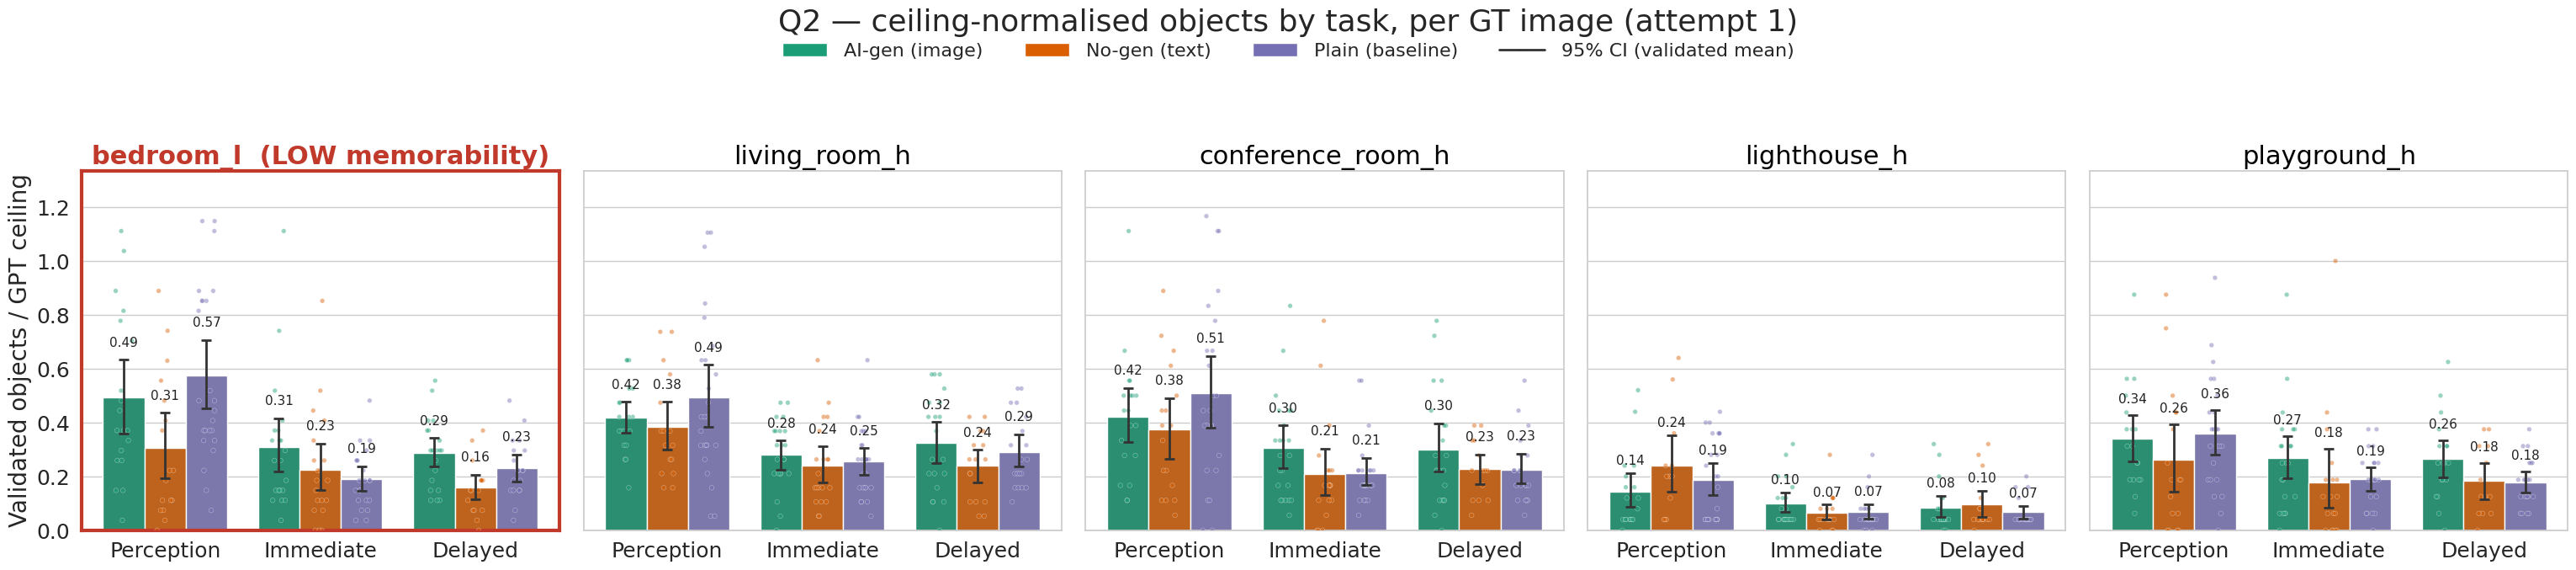

In [12]:
def plot_per_gt(measure, label, data=None, gens=None, attempt=1, fmt="{:.1f}",
                fname=None, title=None, save=True):
    """Five panels, one per GT image: x = task, one bar per generation."""
    d = (df if data is None else data)
    d = d[d["attempt"] == attempt] if attempt else d
    gens = gens or gens_present(d)
    fig, axes = plt.subplots(1, 5, figsize=(31, 7), sharey=True)
    vmax = 0
    for ax, gt in zip(axes, GT_ORDER):
        sub = d[d["gt"] == gt]
        ppt = (sub.groupby(["generation", "task", "uid"], as_index=False)[measure]
                  .mean().dropna(subset=[measure]))
        gg = [g for g in gens if g in set(ppt["generation"])]
        if not ppt.empty:
            vmax = max(vmax, draw_bars(ax, ppt, "task", TASK_ORDER, "generation", gg,
                                       measure, fmt=fmt))
        low = MEMORABILITY[gt] == "low"
        ax.set_title(GT_LABELS[gt] + ("  (LOW memorability)" if low else ""),
                     color="#c0392b" if low else "black",
                     fontweight="bold" if low else "normal")
        if low:                       # frame the one panel the hypothesis is about
            for spine in ax.spines.values():
                spine.set(visible=True, color="#c0392b", linewidth=3)
        ax.set_xlabel("")
        ax.set_ylabel(label if ax is axes[0] else "")
        ax.set_xticks(range(len(TASK_ORDER)))
        ax.set_xticklabels([TASK_LABELS[t].replace(" memory", "").replace(" ", "\n")
                            for t in TASK_ORDER])
    for ax in axes:
        style_count_axis(ax, vmax=vmax)
    fig.suptitle(title or f"{label} per GT image (attempt {attempt})")
    figure_legend(fig, gens, marker="bar", ci=True, y=0.95)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    if save and fname:
        save_fig(fig, GRAPHS / fname)
    plt.show()


plot_per_gt("n_in_image_objects", "Mean validated objects",
            title="Q2 — validated objects by task, per GT image (attempt 1)",
            fname="q2_objects_by_task_per_gt.png")

plot_per_gt("ceil_frac_objects", "Validated objects / GPT ceiling", fmt="{:.2f}",
            title="Q2 — ceiling-normalised objects by task, per GT image (attempt 1)",
            fname="q2_ceiling_fraction_by_task_per_gt.png")

### 3.3 The hypothesis in one figure

Collapse the four `_h` images into "high" and keep `bedroom_l` as "low", then plot the three
tasks as connected points. **The hypothesis is about the slope of the immediate → delayed
segment**: it should be flat on the right (high memorability) and fall on the left (low).
Perception is drawn as the reference level for how far there is to fall.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_memorability_interaction_objects.png


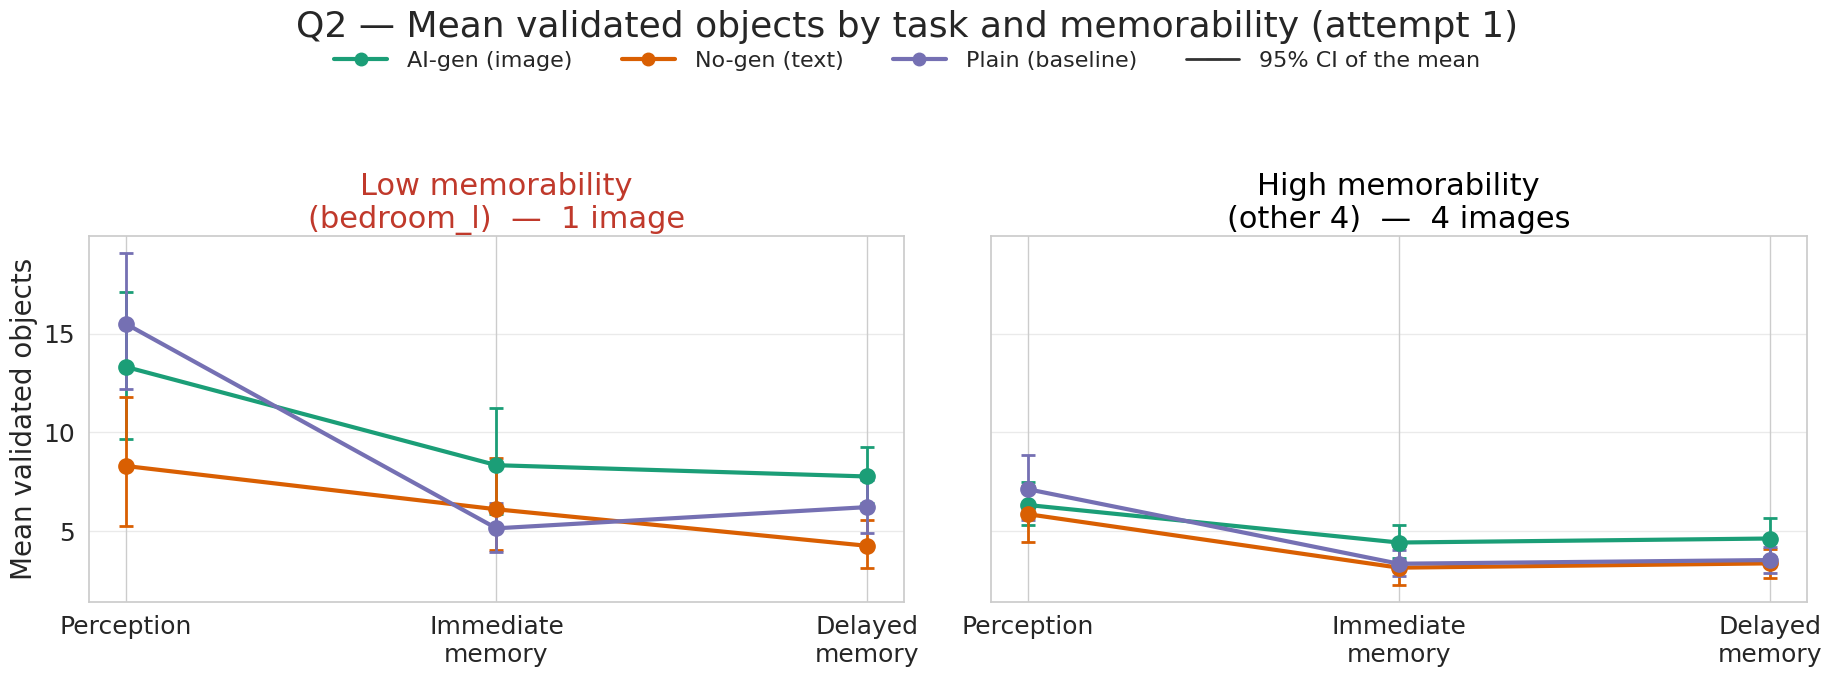

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_memorability_interaction_ceiling_frac.png


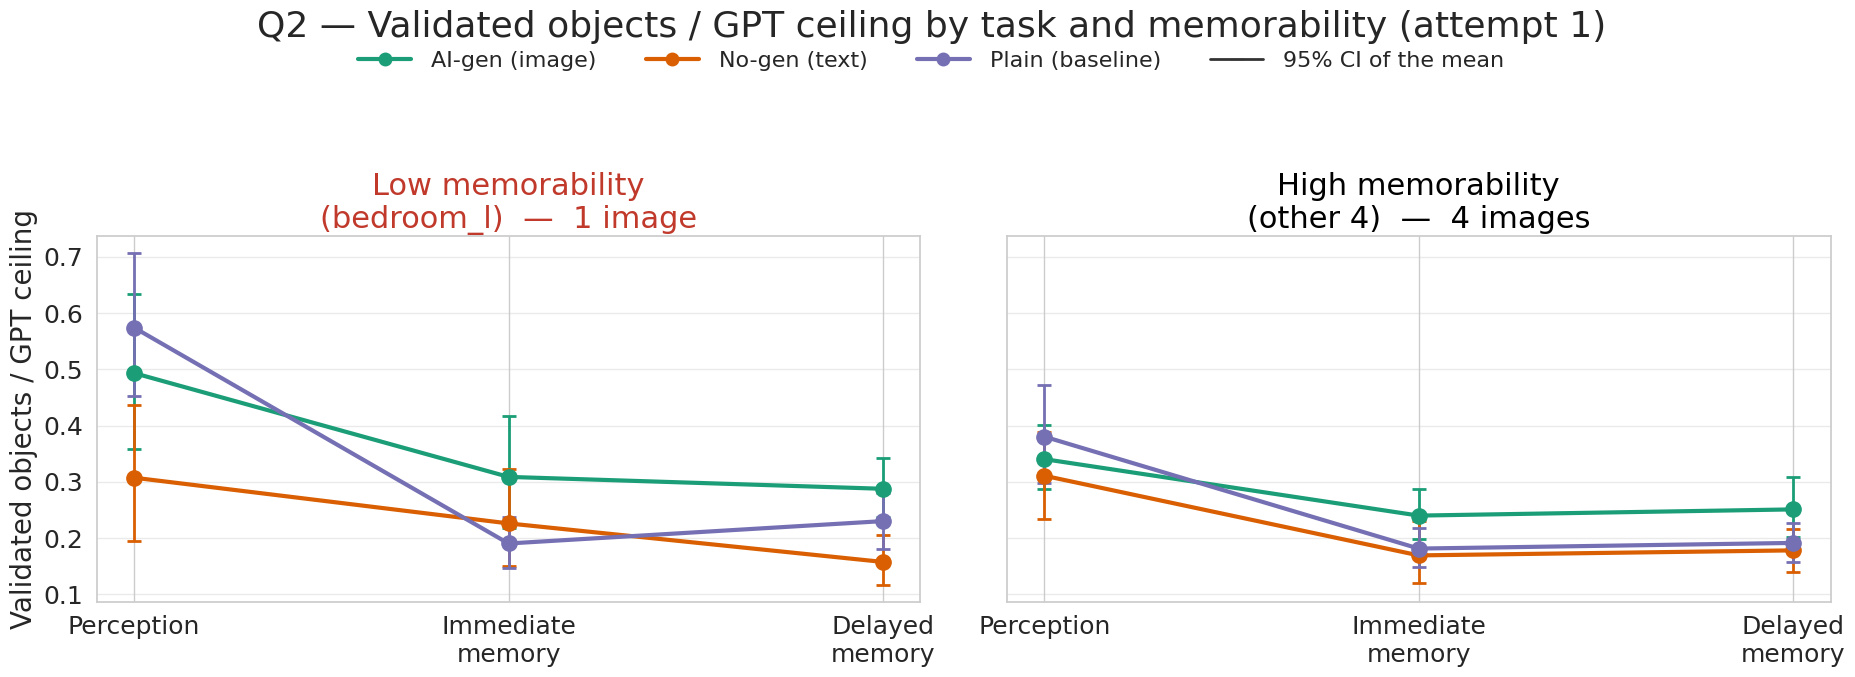

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_memorability_interaction_clip.png


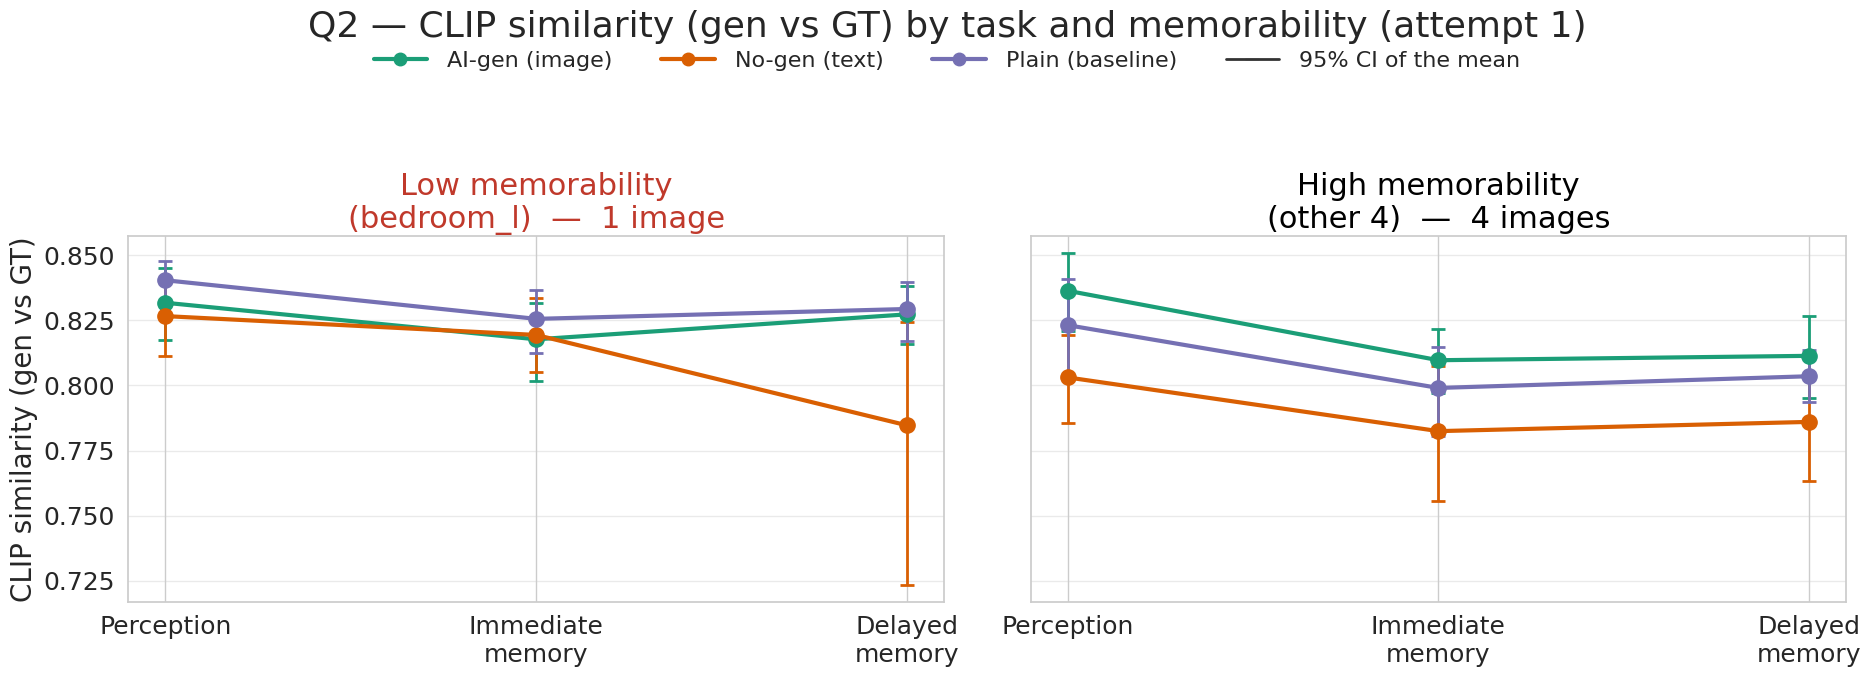

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_memorability_interaction_vgg.png


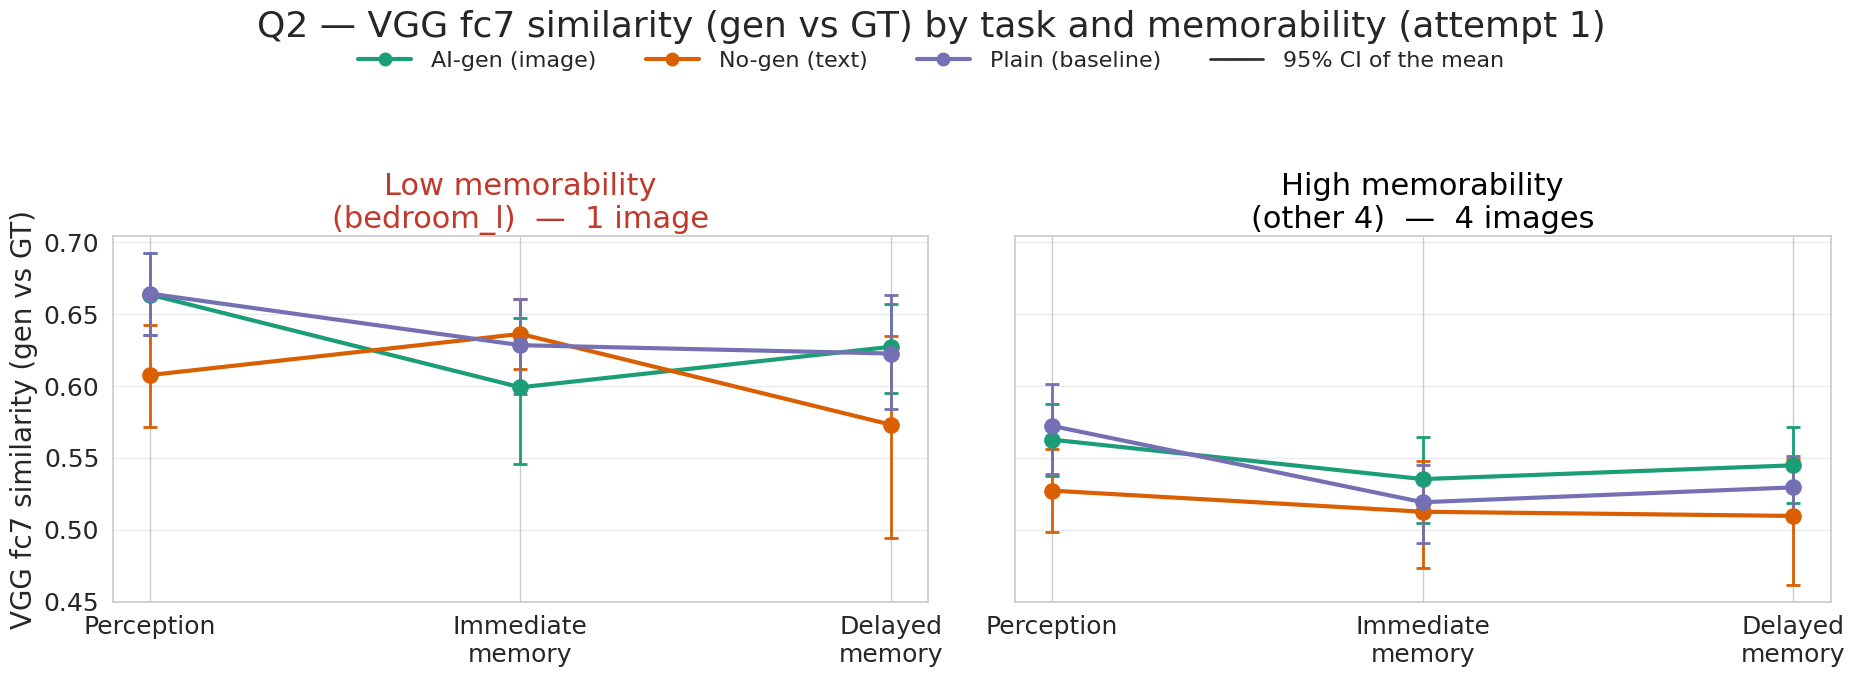

In [13]:
def plot_memorability(measure, label, data=None, gens=None, attempt=1, fname=None,
                      title=None, save=True):
    d = (df if data is None else data)
    d = d[d["attempt"] == attempt] if attempt else d
    gens = gens or gens_present(d)
    # Average within participant *within* memorability level first: the high group is 4 images
    # and the low group is 1, so an un-collapsed mean would weight the high group by trials.
    ppt = (d.groupby(["generation", "memorability", "task", "uid"], as_index=False)[measure]
             .mean().dropna(subset=[measure]))

    fig, axes = plt.subplots(1, 2, figsize=(19, 7), sharey=True)
    for ax, mem in zip(axes, MEM_ORDER):
        sub = ppt[ppt["memorability"] == mem]
        draw_lines(ax, sub, "task", TASK_ORDER, "generation", gens, measure)
        ax.set_xticklabels([TASK_LABELS[t].replace(" ", "\n") for t in TASK_ORDER])
        n_img = 1 if mem == "low" else 4
        ax.set_title(f"{MEM_LABELS[mem]}  —  {n_img} image{'s' if n_img > 1 else ''}",
                     color="#c0392b" if mem == "low" else "black")
        ax.set_xlabel(""); ax.set_ylabel(label if ax is axes[0] else "")
        ax.grid(True, axis="y", alpha=0.4)
    fig.suptitle(title or f"Q2 — {label} by task and memorability (attempt {attempt})")
    figure_legend(fig, gens, marker="o", ci="95% CI of the mean", y=0.95)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    if save and fname:
        save_fig(fig, GRAPHS / fname)
    plt.show()


plot_memorability("n_in_image_objects", "Mean validated objects",
                  fname="q2_memorability_interaction_objects.png")
plot_memorability("ceil_frac_objects", "Validated objects / GPT ceiling",
                  fname="q2_memorability_interaction_ceiling_frac.png")
plot_memorability("clip_similarity", "CLIP similarity (gen vs GT)",
                  fname="q2_memorability_interaction_clip.png")
plot_memorability("vgg_similarity", "VGG fc7 similarity (gen vs GT)",
                  fname="q2_memorability_interaction_vgg.png")

In [14]:
# The immediate -> delayed segment on its own, as a number: the quantity the hypothesis is
# about. Positive = delayed is worse. Paired is impossible here (task is between-participants),
# so this is a difference of two independent group means with a bootstrap CI on each.
rows = []
for measure, label in [("n_in_image_objects", "Validated objects"),
                       ("ceil_frac_objects", "Objects / ceiling"),
                       ("precision_objects", "Object precision"),
                       ("clip_similarity", "CLIP similarity")]:
    ppt = (A1.groupby(["generation", "memorability", "task", "uid"], as_index=False)[measure]
             .mean().dropna(subset=[measure]))
    for gen in gens_present(ppt):
        for mem in MEM_ORDER:
            s = ppt[(ppt["generation"] == gen) & (ppt["memorability"] == mem)]
            imm = s[s["task"] == "immediate"][measure]
            dl = s[s["task"] == "delay"][measure]
            if len(imm) < 2 or len(dl) < 2:
                continue
            rows.append({"measure": label, "generation": gen, "memorability": mem,
                         "immediate": imm.mean(), "delayed": dl.mean(),
                         "imm - del": imm.mean() - dl.mean(),
                         "n_imm": len(imm), "n_del": len(dl)})
gap = pd.DataFrame(rows)
print("Immediate minus delayed (positive = delayed is worse). "
      "The hypothesis predicts a larger gap in the 'low' rows.")
display(gap.pivot_table(index=["measure", "generation"], columns="memorability",
                        values="imm - del").round(3))

Immediate minus delayed (positive = delayed is worse). The hypothesis predicts a larger gap in the 'low' rows.


memorability                   high    low
measure           generation              
CLIP similarity   aigen      -0.002 -0.010
                  nogen      -0.004  0.035
                  plain      -0.005 -0.004
Object precision  aigen      -0.002  0.002
                  nogen      -0.026 -0.013
                  plain      -0.050 -0.052
Objects / ceiling aigen      -0.011  0.021
                  nogen      -0.009  0.069
                  plain      -0.010 -0.040
Validated objects aigen      -0.203  0.571
                  nogen      -0.218  1.850
                  plain      -0.186 -1.074

### 3.4 The missing analysis — aigen on `bedroom_l` alone, every semantic category

This has never been run. All six categories, aigen only, `bedroom_l` only, across the three
attempts, with `bedroom_l`'s **own** ceiling line per panel rather than the five-image average.

Cells here are small (19–21 participants per task), which is exactly why the participant dots
are drawn: the sample size should be visible in the figure rather than stated beside it.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_bedroom_aigen_categories_perception.png


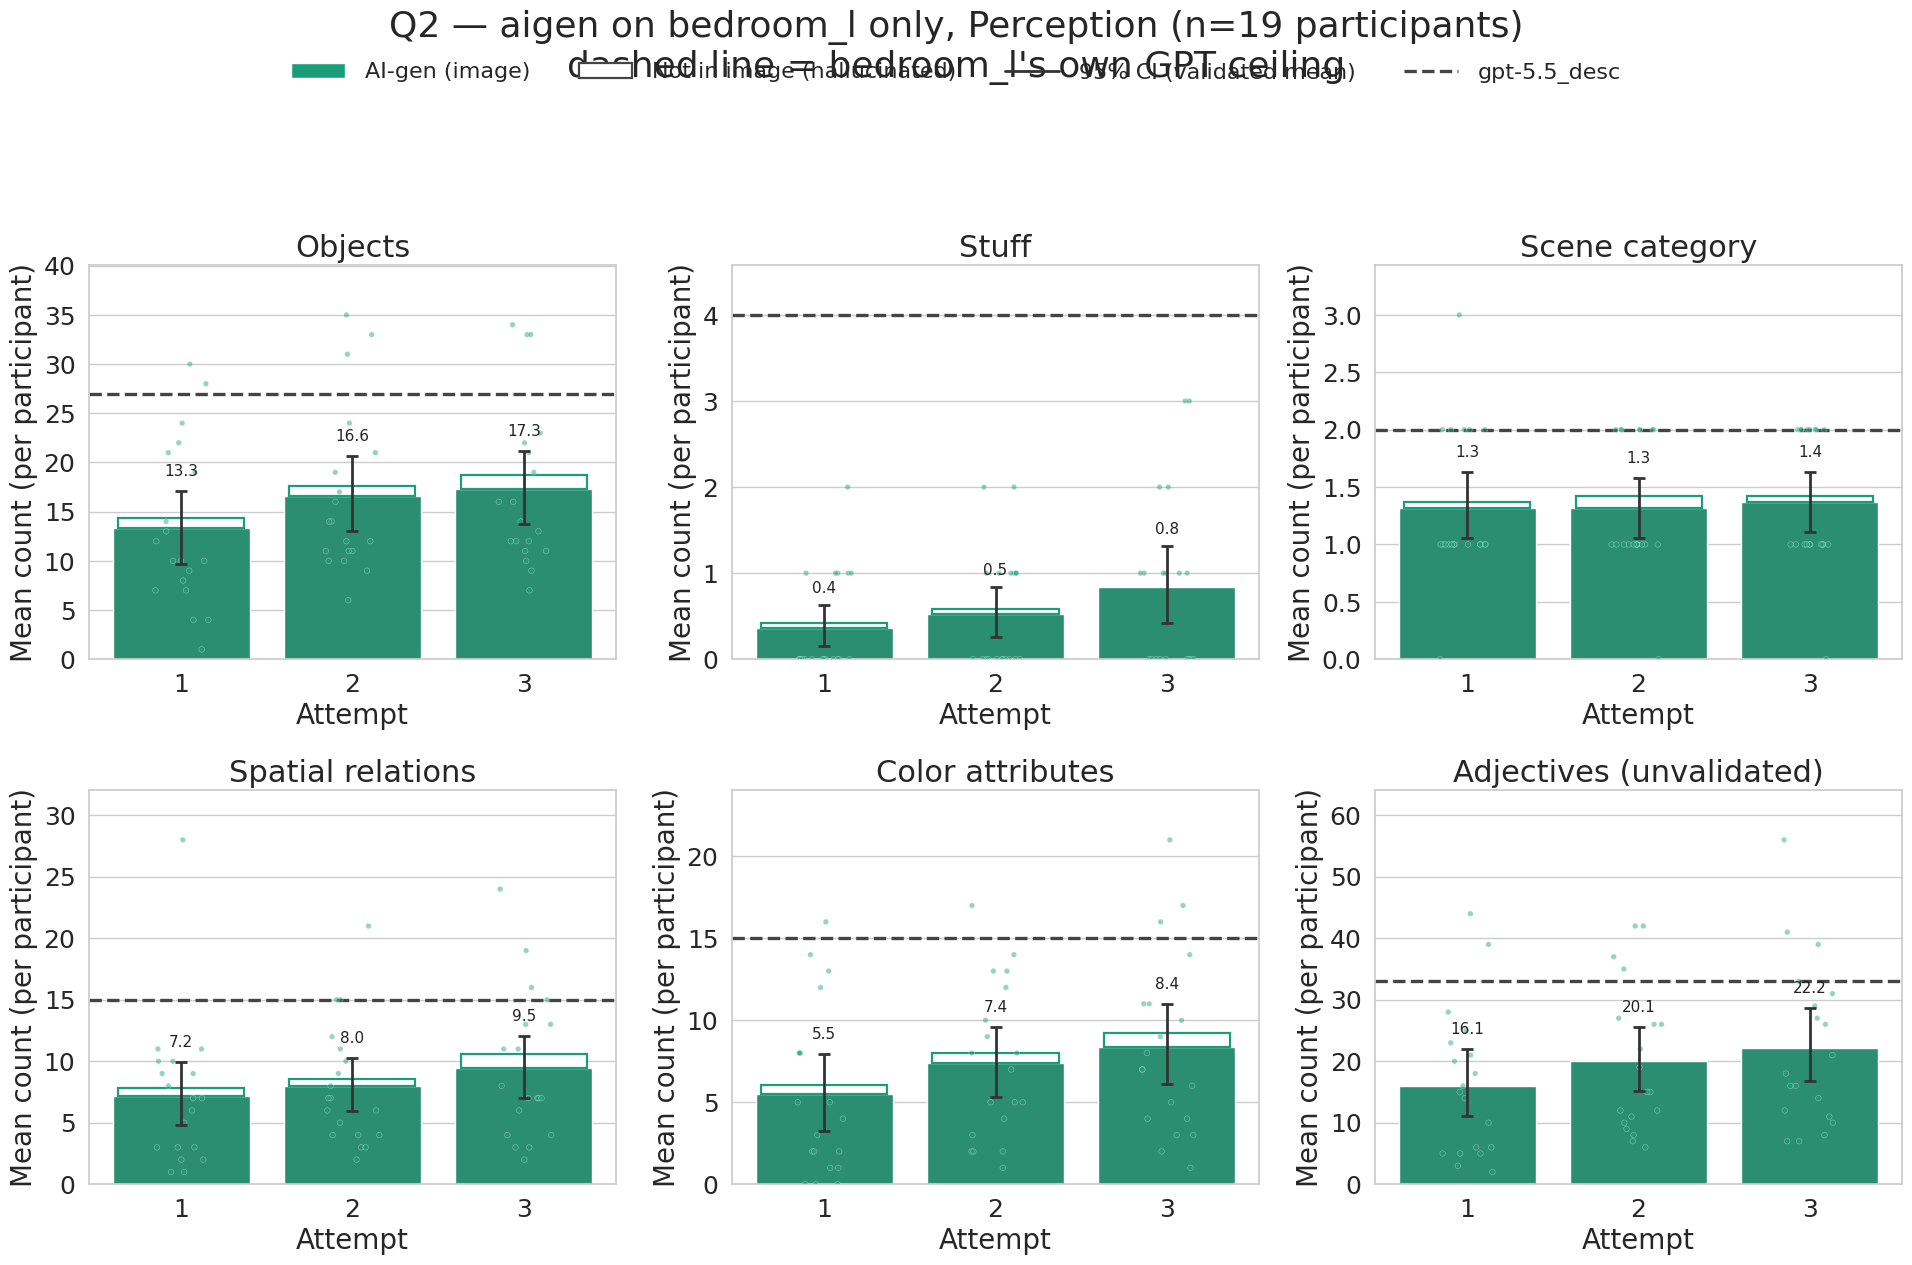

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_bedroom_aigen_categories_immediate.png


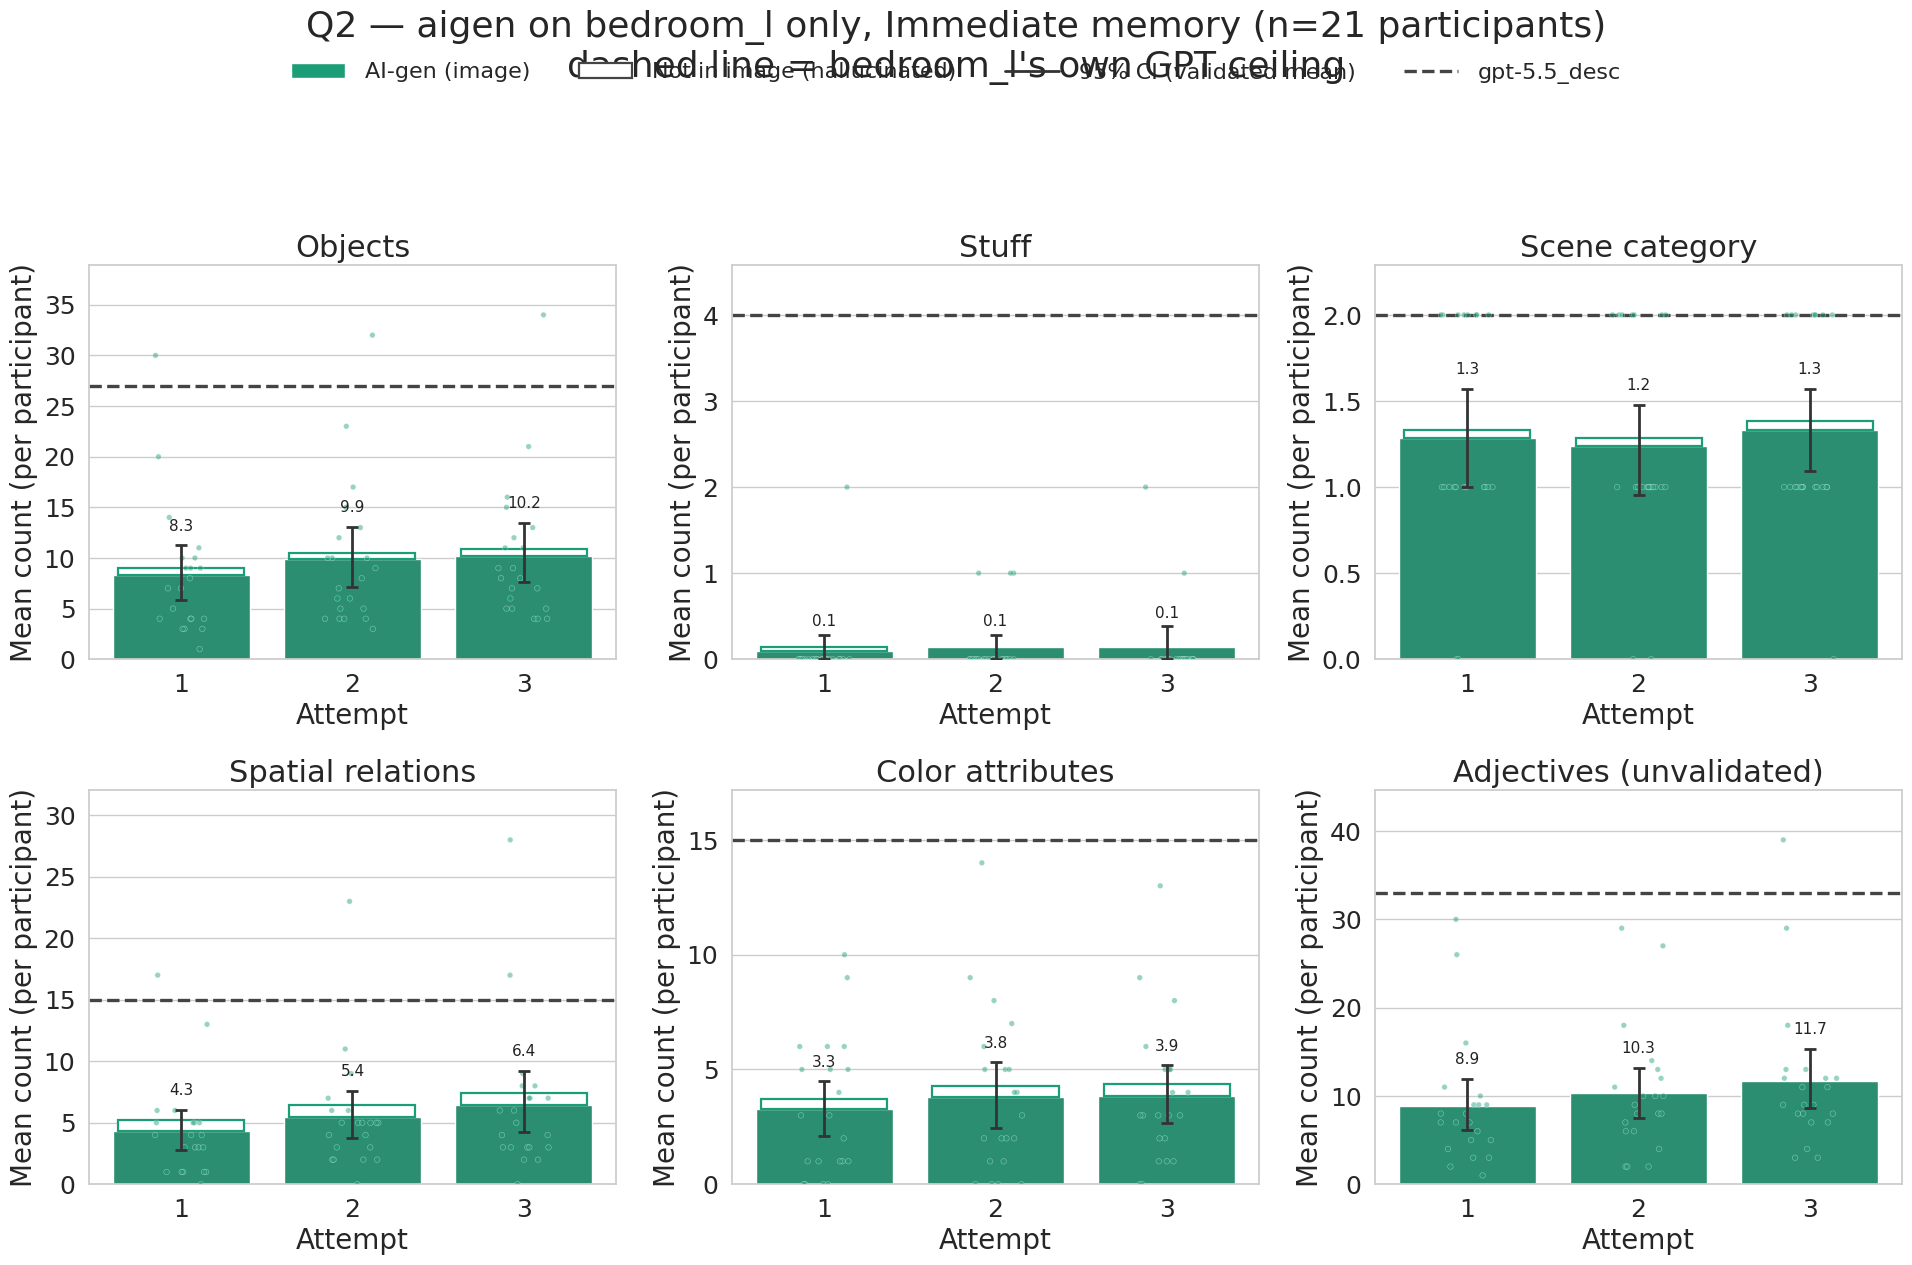

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_bedroom_aigen_categories_delay.png


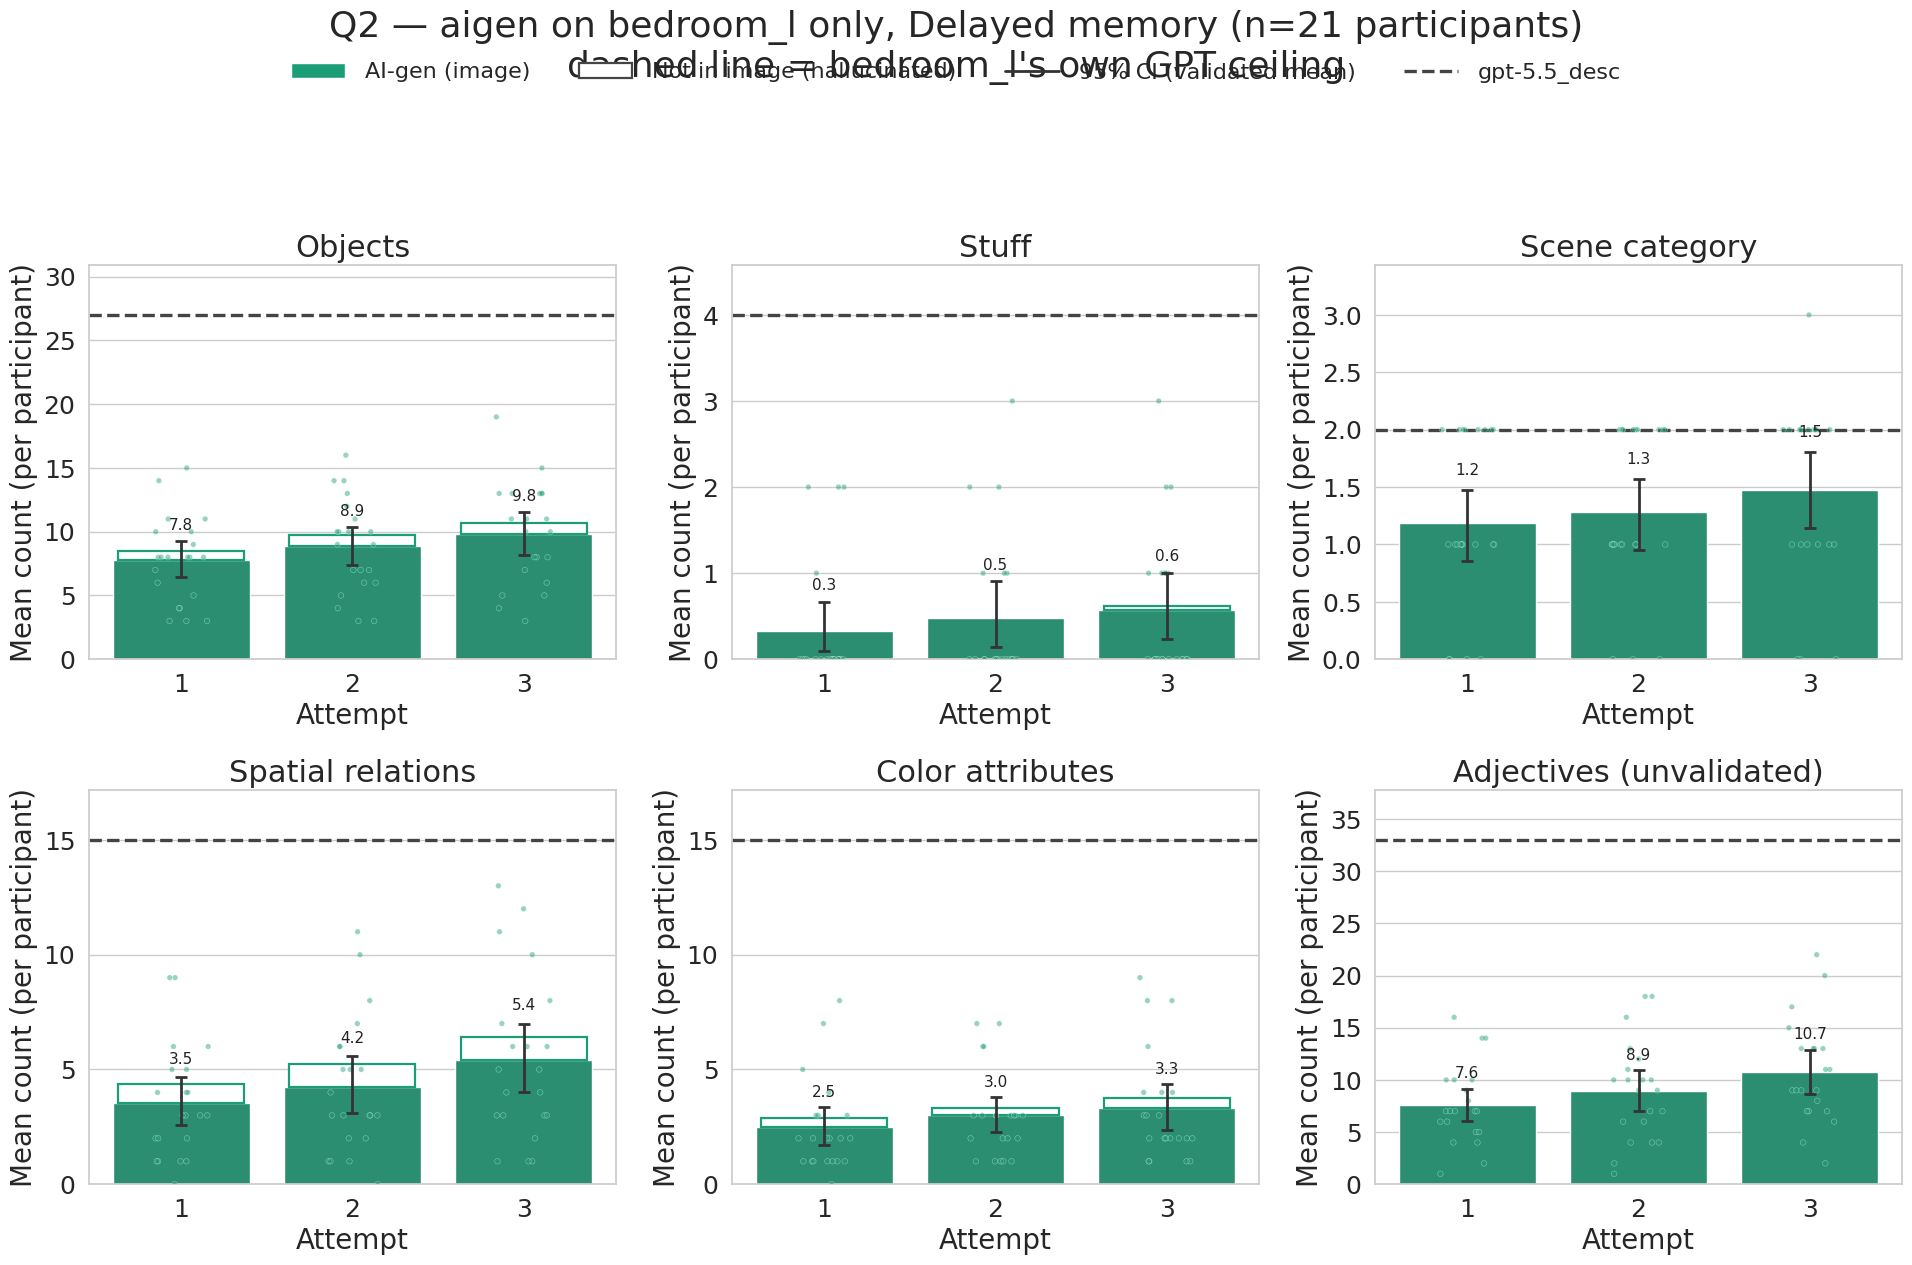

In [16]:
BEDROOM = "bedroom_l.jpg"


def plot_categories_grid(data, gens, attempts=ATTEMPTS, gt=None, ceil_row=None,
                         title=None, fname=None, save=True, by_task=True):
    """All six categories, x = attempt, one bar per generation. `gt` restricts to one image
    and `ceil_row` supplies that image's own ceiling instead of the 5-image mean."""
    d = data[data["gt"] == gt] if gt else data
    tasks = TASK_ORDER if by_task else [None]
    for task in tasks:
        sub = d[d["task"] == task] if task else d
        gg = [g for g in gens if g in set(sub["generation"])]
        if sub.empty or not gg:
            print(f"  (no rows for {gt} / {task} - skipped)")
            continue
        fig, axes = plt.subplots(2, 3, figsize=(19.5, 13))
        for ax, cat in zip(axes.ravel(), CATEGORIES):
            ppt = ppt_means(sub, ["generation", "uid", "attempt"], cat)
            vmax = draw_bars(ax, ppt, "attempt", attempts, "generation", gg, "count",
                             cap_col="cap" if is_validated(cat, COUNT_MODE) else None,
                             fmt="{:.1f}")
            ref = (ceil_row[f"n_{cat}"] if ceil_row is not None else GPT_MEAN.get(cat))
            if ref is not None and not np.isnan(ref):
                ax.axhline(ref, color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
                vmax = max(vmax, ref * 1.09)
            ax.set_title(cat_label(cat, COUNT_MODE))
            ax.set_xlabel("Attempt")
            ax.set_ylabel("Mean count (per participant)")
            style_count_axis(ax, vmax=vmax)
        n = sub[sub["attempt"] == 1]["uid"].nunique()
        fig.suptitle(title.format(task=TASK_LABELS.get(task, "all tasks"), n=n))
        figure_legend(fig, gg, marker="bar", caps=True, ci=True, gpt=True, y=0.955)
        fig.tight_layout(rect=(0, 0, 1, 0.91))
        if save and fname:
            save_fig(fig, GRAPHS / fname.format(task=task))
        plt.show()


bed_ceil = ceil[ceil["gt"] == BEDROOM].iloc[0] if ceil is not None else None
plot_categories_grid(df[df["generation"] == "aigen"], ["aigen"], gt=BEDROOM,
                     ceil_row=bed_ceil,
                     title="Q2 — aigen on bedroom_l only, {task} (n={n} participants)\n"
                           "dashed line = bedroom_l's own GPT ceiling",
                     fname="q2_bedroom_aigen_categories_{task}.png")

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q2_bedroom_aigen_categories_by_task.png


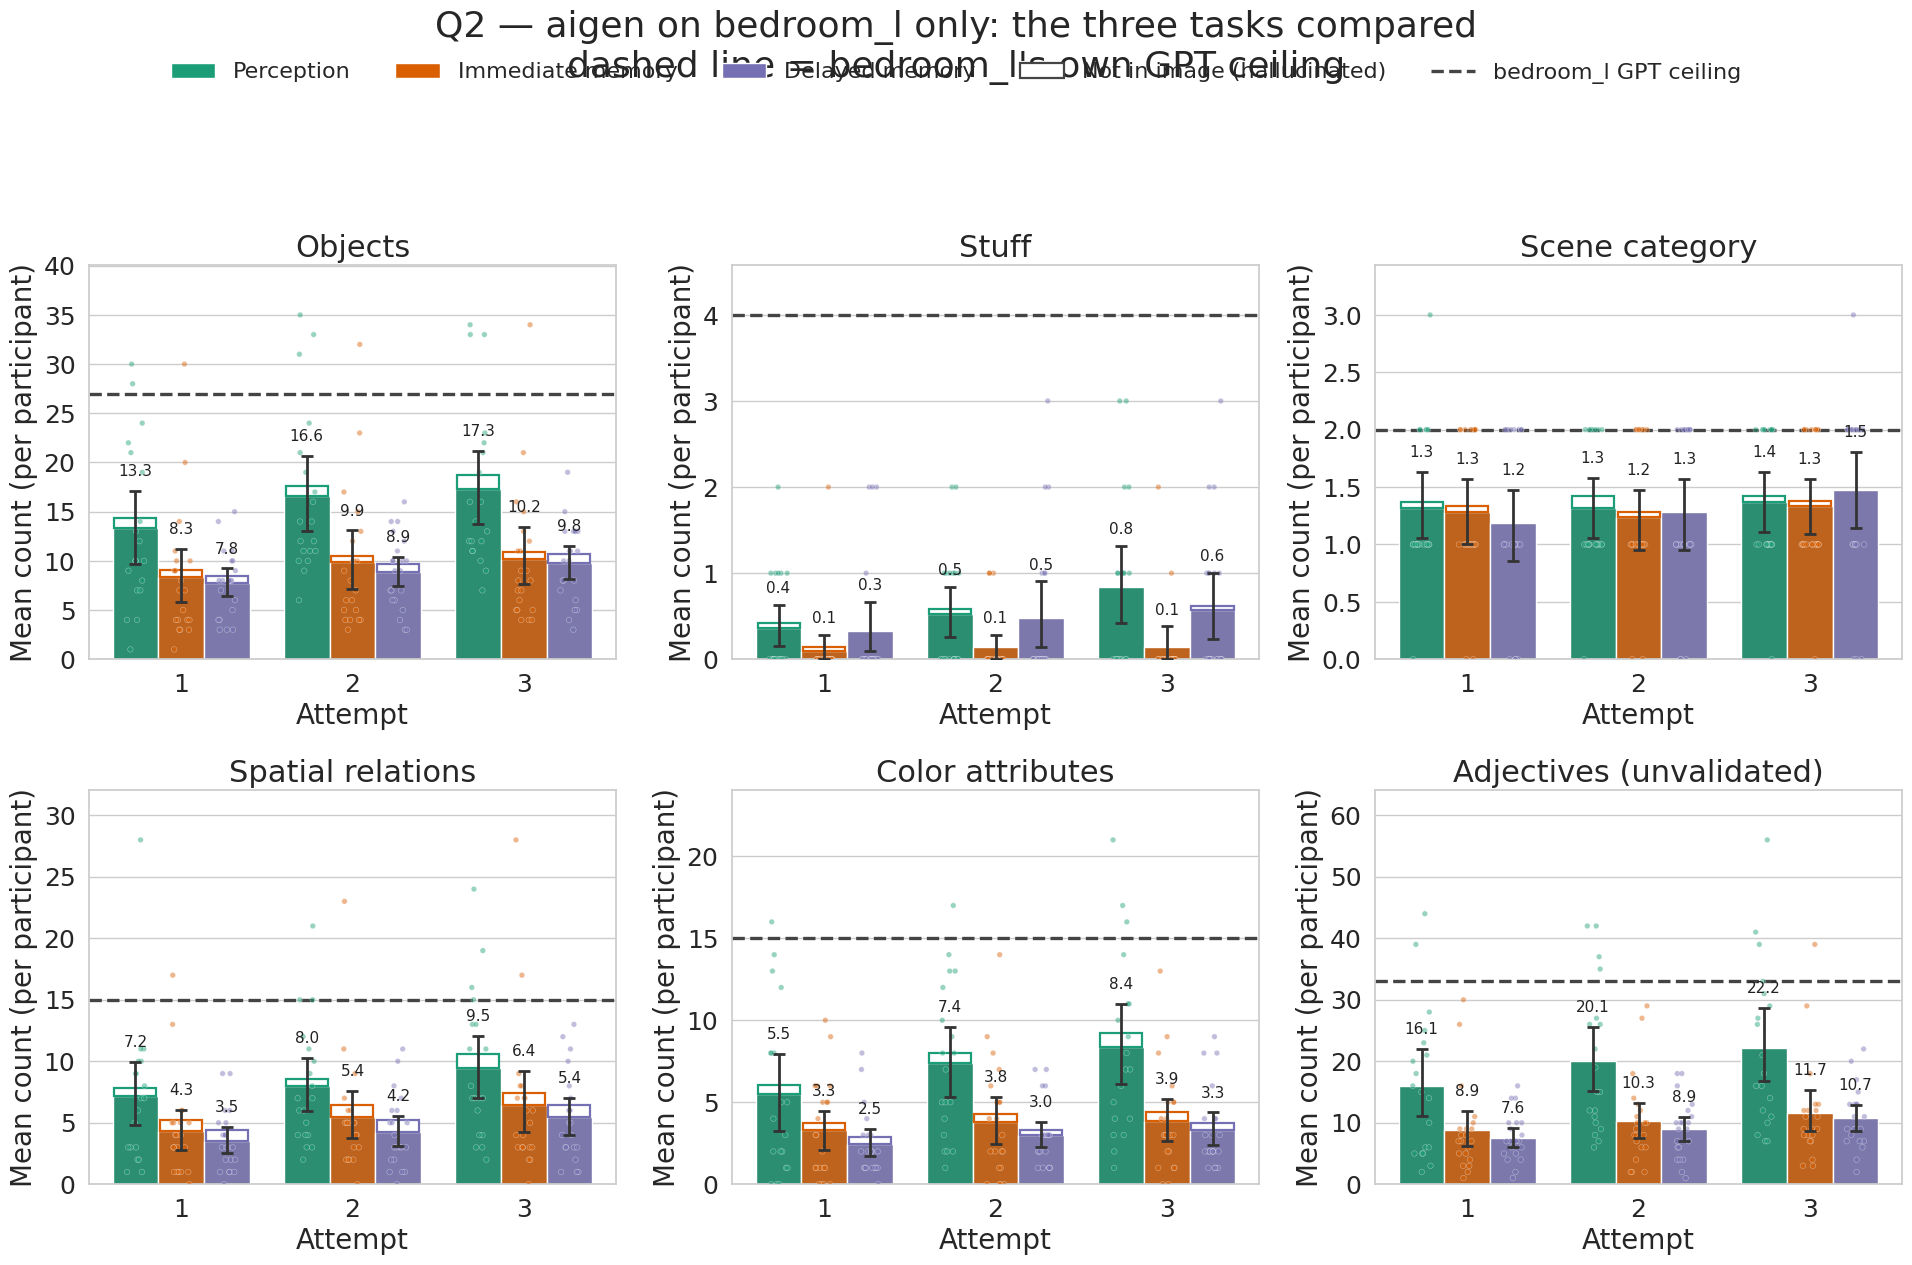

In [17]:
# The same grid with the three tasks side by side per category, so the immediate-vs-delayed
# comparison on bedroom_l can be read without flipping between figures.
bed = df[(df["gt"] == BEDROOM) & (df["generation"] == "aigen")]
fig, axes = plt.subplots(2, 3, figsize=(19.5, 13))
for ax, cat in zip(axes.ravel(), CATEGORIES):
    ppt = ppt_means(bed, ["task", "uid", "attempt"], cat)
    vmax = draw_bars(ax, ppt, "attempt", ATTEMPTS, "task", TASK_ORDER, "count",
                     cap_col="cap" if is_validated(cat, COUNT_MODE) else None,
                     palette=TASK_COLORS, fmt="{:.1f}")
    if bed_ceil is not None:
        ax.axhline(bed_ceil[f"n_{cat}"], color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
        vmax = max(vmax, bed_ceil[f"n_{cat}"] * 1.09)
    ax.set_title(cat_label(cat, COUNT_MODE))
    ax.set_xlabel("Attempt"); ax.set_ylabel("Mean count (per participant)")
    style_count_axis(ax, vmax=vmax)
fig.suptitle("Q2 — aigen on bedroom_l only: the three tasks compared\n"
             "dashed line = bedroom_l's own GPT ceiling")
handles = [Patch(facecolor=TASK_COLORS[t], label=TASK_LABELS[t]) for t in TASK_ORDER]
handles += [Patch(facecolor=CAP_FACE, edgecolor="#444444", linewidth=CAP_LW, label=CAP_LABEL),
            Line2D([], [], color=GPT_DESC_COLOR, lw=2.4, ls="--", label="bedroom_l GPT ceiling")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.955),
           ncol=len(handles), frameon=False, columnspacing=2.0)
fig.tight_layout(rect=(0, 0, 1, 0.91))
save_fig(fig, GRAPHS / "q2_bedroom_aigen_categories_by_task.png")
plt.show()

---
# 4. Q3 — which objects do people report, and do they agree?

Everything from here down runs on `objs`: one row per **object** tag, with the judge's
`in_image` verdict attached.

**The metric is participant share, not mention count.** Cells hold different numbers of
participants (17–25), so a raw count is not comparable across conditions. Share = the fraction
of participants in that cell who mentioned the item at least once, which is comparable and is
also the quantity "do people agree" is actually about.

In [18]:
def item_share(data, keys=("gt", "task"), attempts=(1,)):
    """Per key combination: each object's share of participants who mentioned it at least once.

    Deduplicating to (uid, item) first is what makes this a *participant* share rather than a
    mention count - a participant who writes "chair" three times counts once.
    """
    d = data[data["attempt"].isin(attempts)] if attempts else data
    keys = list(keys)
    n_ppt = d.groupby(keys)["uid"].nunique().rename("n_ppt")
    seen = d.drop_duplicates(keys + ["uid", "item"])
    out = (seen.groupby(keys + ["item"])
               .agg(n_mentioning=("uid", "nunique"),
                    frac_in_image=("in_image", "mean"))
               .reset_index()
               .join(n_ppt, on=keys))
    out["share"] = out["n_mentioning"] / out["n_ppt"]
    return out.sort_values(keys + ["share"], ascending=[True] * len(keys) + [False])


# Attempt-1 shares per image x task, pooling the three arms: at attempt 1 nobody has seen any
# feedback yet, so the arms are describing under identical conditions and pooling buys N.
share_gt_task = item_share(objs, keys=("gt", "task"))

# The same thing pooled over EVERYTHING for an image - all arms, tasks and attempts. This is
# the data-driven "typical set": what this participant pool says is in this scene, with no
# ground truth involved at all.
share_pooled = item_share(objs, keys=("gt",), attempts=None)

print(f"{len(share_gt_task)} (gt, task, item) rows | "
      f"{len(share_pooled)} (gt, item) rows in the pooled consensus")
display(share_pooled[share_pooled["gt"] == BEDROOM].head(15)
        [["item", "n_mentioning", "n_ppt", "share", "frac_in_image"]].round(3))

1792 (gt, task, item) rows | 1876 (gt, item) rows in the pooled consensus


,item,n_mentioning,n_ppt,share,frac_in_image
32,bed,148,178,0.831,1.000
468,wall,89,178,0.500,1.000
331,pillow,72,178,0.404,1.000
95,book,60,178,0.337,1.000
480,window,56,178,0.315,1.000
83,bench,53,178,0.298,1.000
136,corner,48,178,0.270,0.917
192,flower,46,178,0.258,1.000
454,tree,42,178,0.236,1.000
343,plant,41,178,0.230,1.000


### 4.1 The three typicality references

"Are these simply the most typical bedroom items?" needs something to be typical *relative to*.
Three references, deliberately different in kind:

| reference | what it is | what a hit means |
|---|---|---|
| **LabelMe** | polygons drawn on the GT photo by annotators | the object is objectively *in* the image |
| **GPT ceiling** | one description written *while looking at* the image | the object is *salient* in the image |
| **Pooled consensus** | top-K items across all 192 participants, all arms, all attempts | the object is what *this pool* says is in this scene — **no ground truth at all** |

LabelMe uses its own vocabulary (`bed post`, `picture`, `flowers`) which is not the tagger's,
so matching needs an explicit alignment. The synonym map below is small, hand-written and
**printed in full** — it is a judgement call, not a measurement, and it should be inspected
rather than trusted. Items that match nothing are reported as *no match*, never silently
counted as absent.

In [19]:
# Hand-written, deliberately conservative: only pairs that are the same thing under two names.
# Anything requiring an argument is left out and shows up as "no match".
SYNONYMS = {
    "picture": {"painting", "paintings", "artwork", "framed picture", "framed art", "print",
                "prints", "framed print", "wall art", "photo", "photograph", "frame",
                "picture frame", "botanical print"},
    "flowers": {"flower", "bouquet", "floral arrangement", "blossoms"},
    "magazines": {"magazine", "stack of magazines", "papers", "book", "books"},
    "books": {"book", "stack of books", "bookshelf"},
    "nightstand": {"bedside table", "night stand", "side table", "end table"},
    "wardrobe": {"cabinet", "armoire", "dresser", "chest of drawers", "closet", "cupboard"},
    "potted plant": {"plant", "plants", "houseplant", "tree", "indoor tree", "pot plant",
                     "potted tree", "foliage"},
    "rug": {"carpet", "area rug", "mat", "floor rug"},
    "pillow": {"pillows", "cushion", "cushions", "throw pillow"},
    "bed post": {"bedpost", "post", "posts", "four-poster", "bed frame"},
    "lamp": {"lampshade", "table lamp", "light", "lights", "light fixture"},
    "chair": {"chairs", "armchair", "seat", "bench", "stool"},
    "table": {"tables", "desk", "coffee table"},
    "window": {"windows", "windowpane", "arched window"},
    "wall": {"walls"},
    "floor": {"flooring", "ground"},
    "sofa": {"couch", "settee"},
    "vase": {"vases", "jar", "pot"},
    "basket": {"baskets", "wicker basket"},
    "bowl": {"bowls", "dish"},
}
print("Synonym map (LabelMe term <- participant terms treated as the same object):")
for k, v in SYNONYMS.items():
    print(f"  {k:15s} <- {', '.join(sorted(v))}")


def _expand(term):
    """A LabelMe/ceiling term plus every participant wording mapped onto it, and a naive
    singular/plural pair. Matching is on the whole normalised string; no substring matching,
    which would make 'bed' match 'bedside table'."""
    forms = {term}
    forms |= SYNONYMS.get(term, set())
    for f in list(forms):
        forms.add(f + "s")
        if f.endswith("s"):
            forms.add(f[:-1])
    return forms


def reference_sets(gt, top_k=15):
    """The three typicality reference sets for one GT image, as sets of participant wordings."""
    lm_terms = set(lm[lm["gt"] == gt]["object"])
    ceil_terms = set()
    if ceil is not None:
        row = ceil[ceil["gt"] == gt]
        if len(row):
            ceil_terms = {str(t).strip().lower()
                          for t in json.loads(row.iloc[0]["in_image_objects"])}
    pooled = set(share_pooled[share_pooled["gt"] == gt].head(top_k)["item"])
    return {
        "LabelMe": set().union(*(_expand(t) for t in lm_terms)) if lm_terms else set(),
        "GPT ceiling": set().union(*(_expand(t) for t in ceil_terms)) if ceil_terms else set(),
        f"Pooled top-{top_k}": pooled,
    }


REF_MARKERS = {"LabelMe": "s", "GPT ceiling": "o"}      # pooled key is built per call
REF_COLOR = {"LabelMe": "#2c3e50", "GPT ceiling": "#8e44ad"}
print("\nbedroom_l reference sizes:",
      {k: len(v) for k, v in reference_sets(BEDROOM).items()})

Synonym map (LabelMe term <- participant terms treated as the same object):
  picture         <- artwork, botanical print, frame, framed art, framed picture, framed print, painting, paintings, photo, photograph, picture frame, print, prints, wall art
  flowers         <- blossoms, bouquet, floral arrangement, flower
  magazines       <- book, books, magazine, papers, stack of magazines
  books           <- book, bookshelf, stack of books
  nightstand      <- bedside table, end table, night stand, side table
  wardrobe        <- armoire, cabinet, chest of drawers, closet, cupboard, dresser
  potted plant    <- foliage, houseplant, indoor tree, plant, plants, pot plant, potted tree, tree
  rug             <- area rug, carpet, floor rug, mat
  pillow          <- cushion, cushions, pillows, throw pillow
  bed post        <- bed frame, bedpost, four-poster, post, posts
  lamp            <- lampshade, light, light fixture, lights, table lamp
  chair           <- armchair, bench, chairs, seat

### 4.2 The most prominent objects at attempt 1

Top 15 objects per image, ordered by their **perception** share so the two memory conditions
read as departures from what people say with the picture in front of them. Bars are
participant share with a bootstrap CI.

The marker columns on the right are the three references: a filled marker means that object is
in that reference set. An item with **no markers at all** is one that many participants report
and no reference contains — either a genuine gap in the references, or a shared error.

Bar shading marks the judge's verdict: **hatched = the judge rejected it for most of the
participants who said it**, i.e. a commonly hallucinated object.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_top_objects_bedroom_l.png


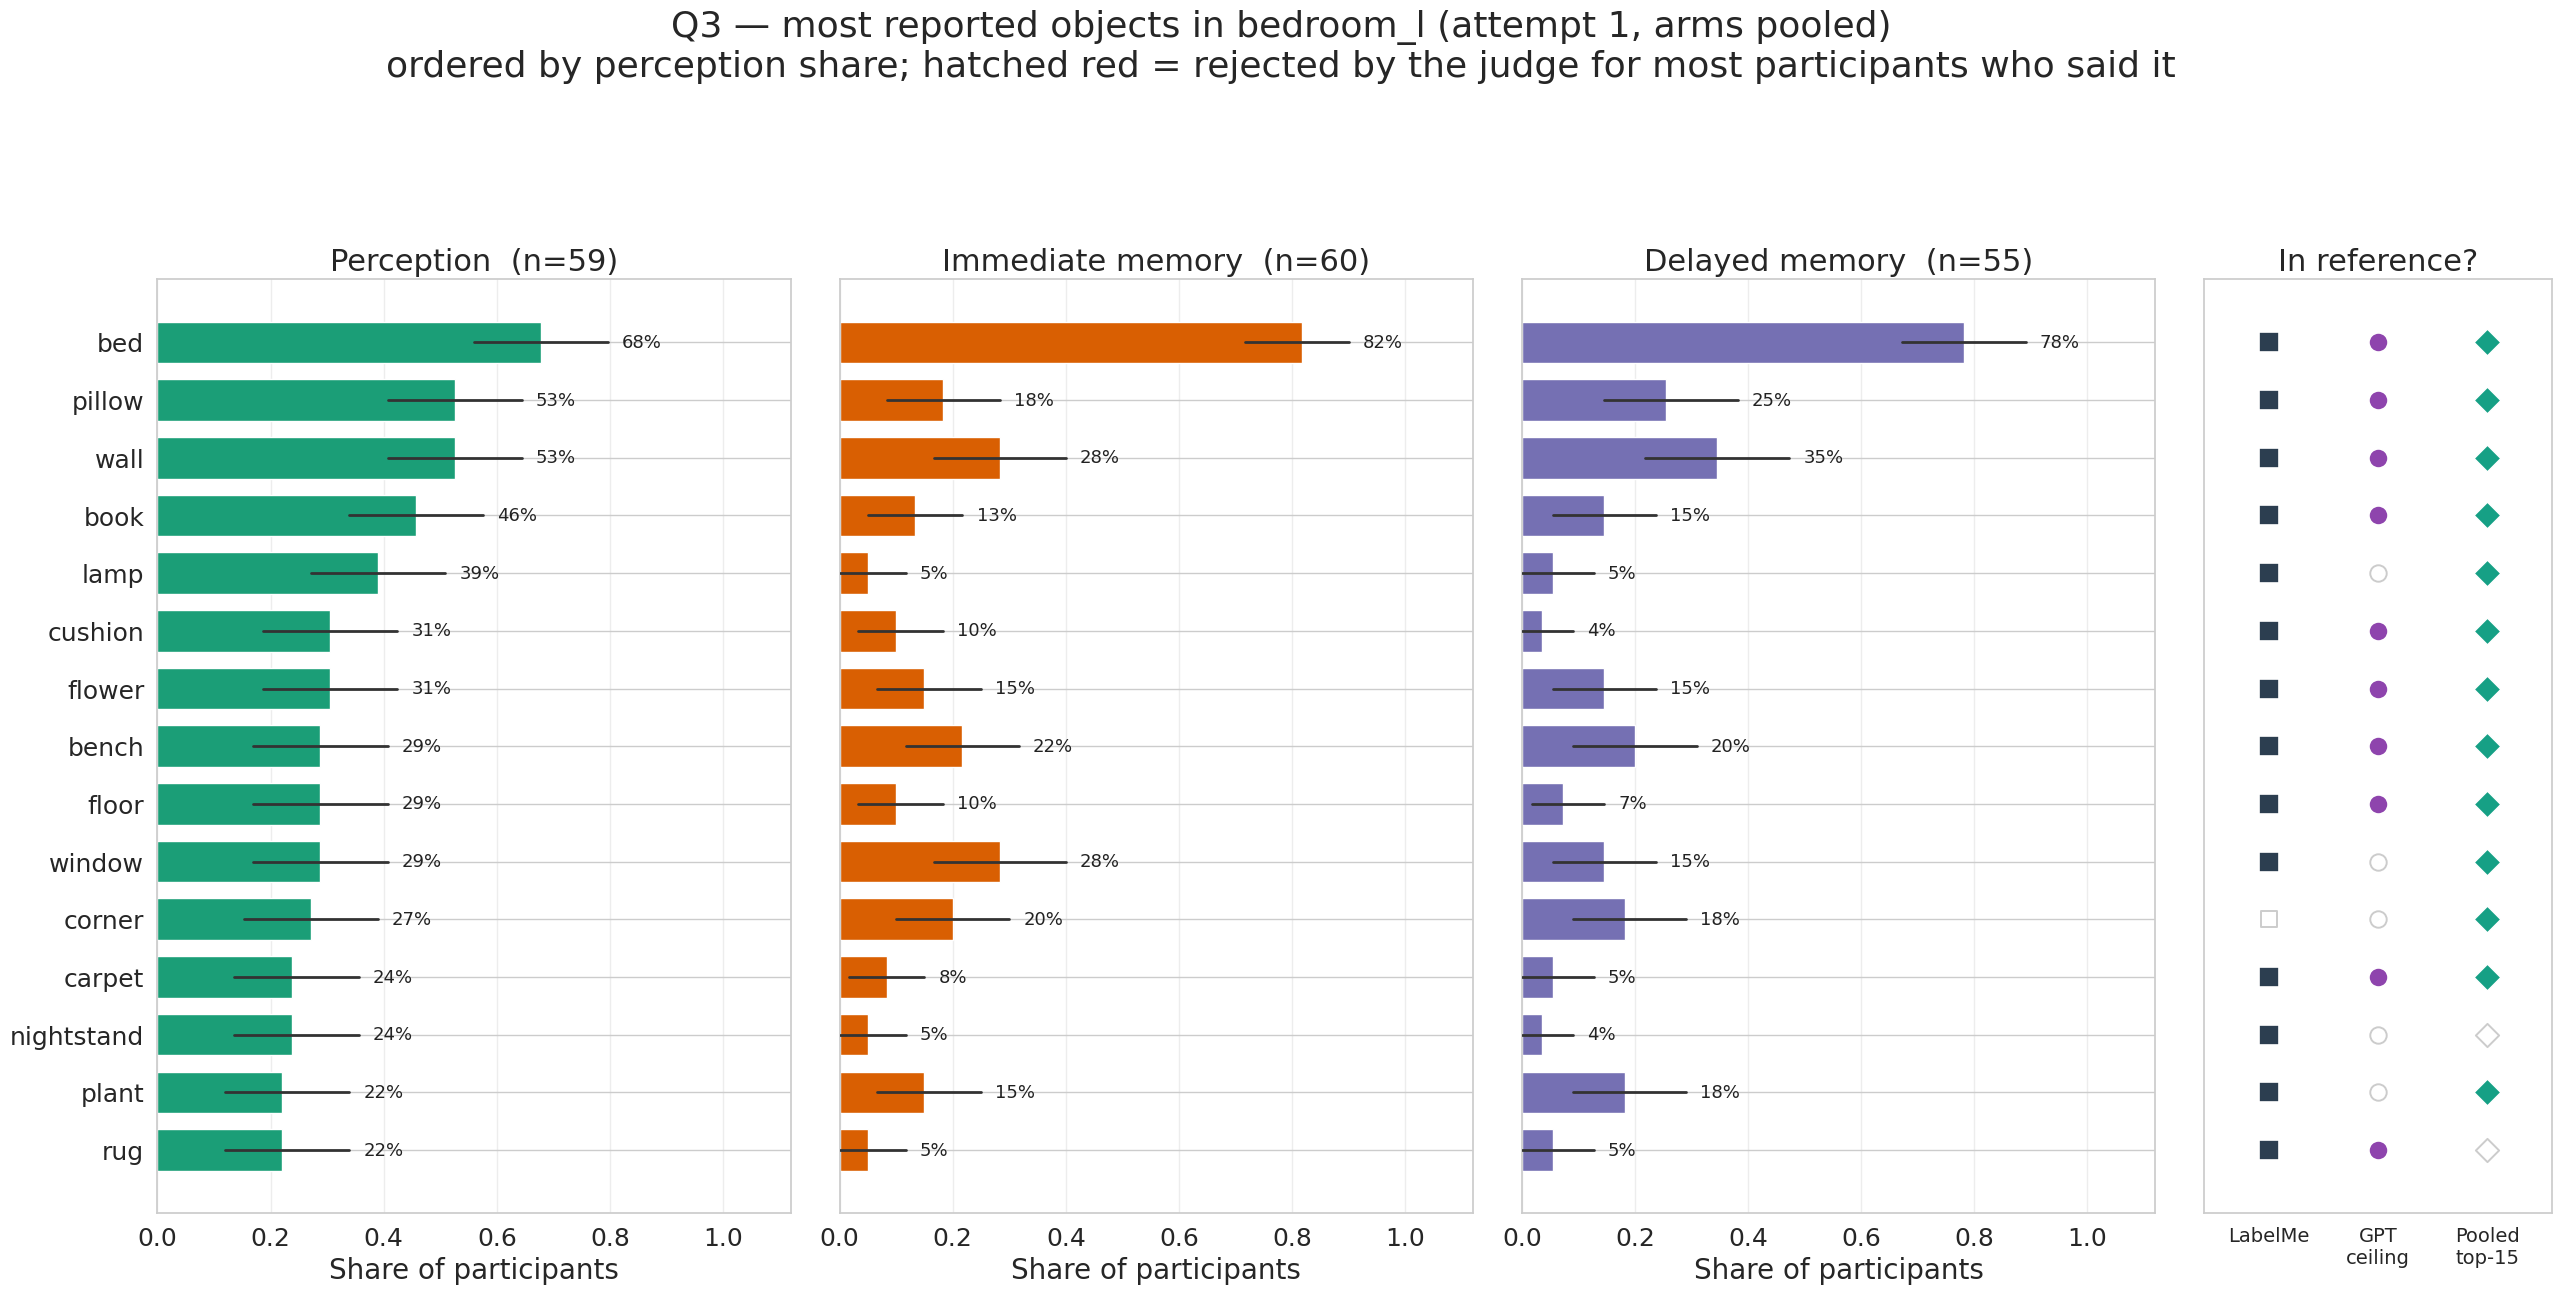

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_top_objects_living_room_h.png


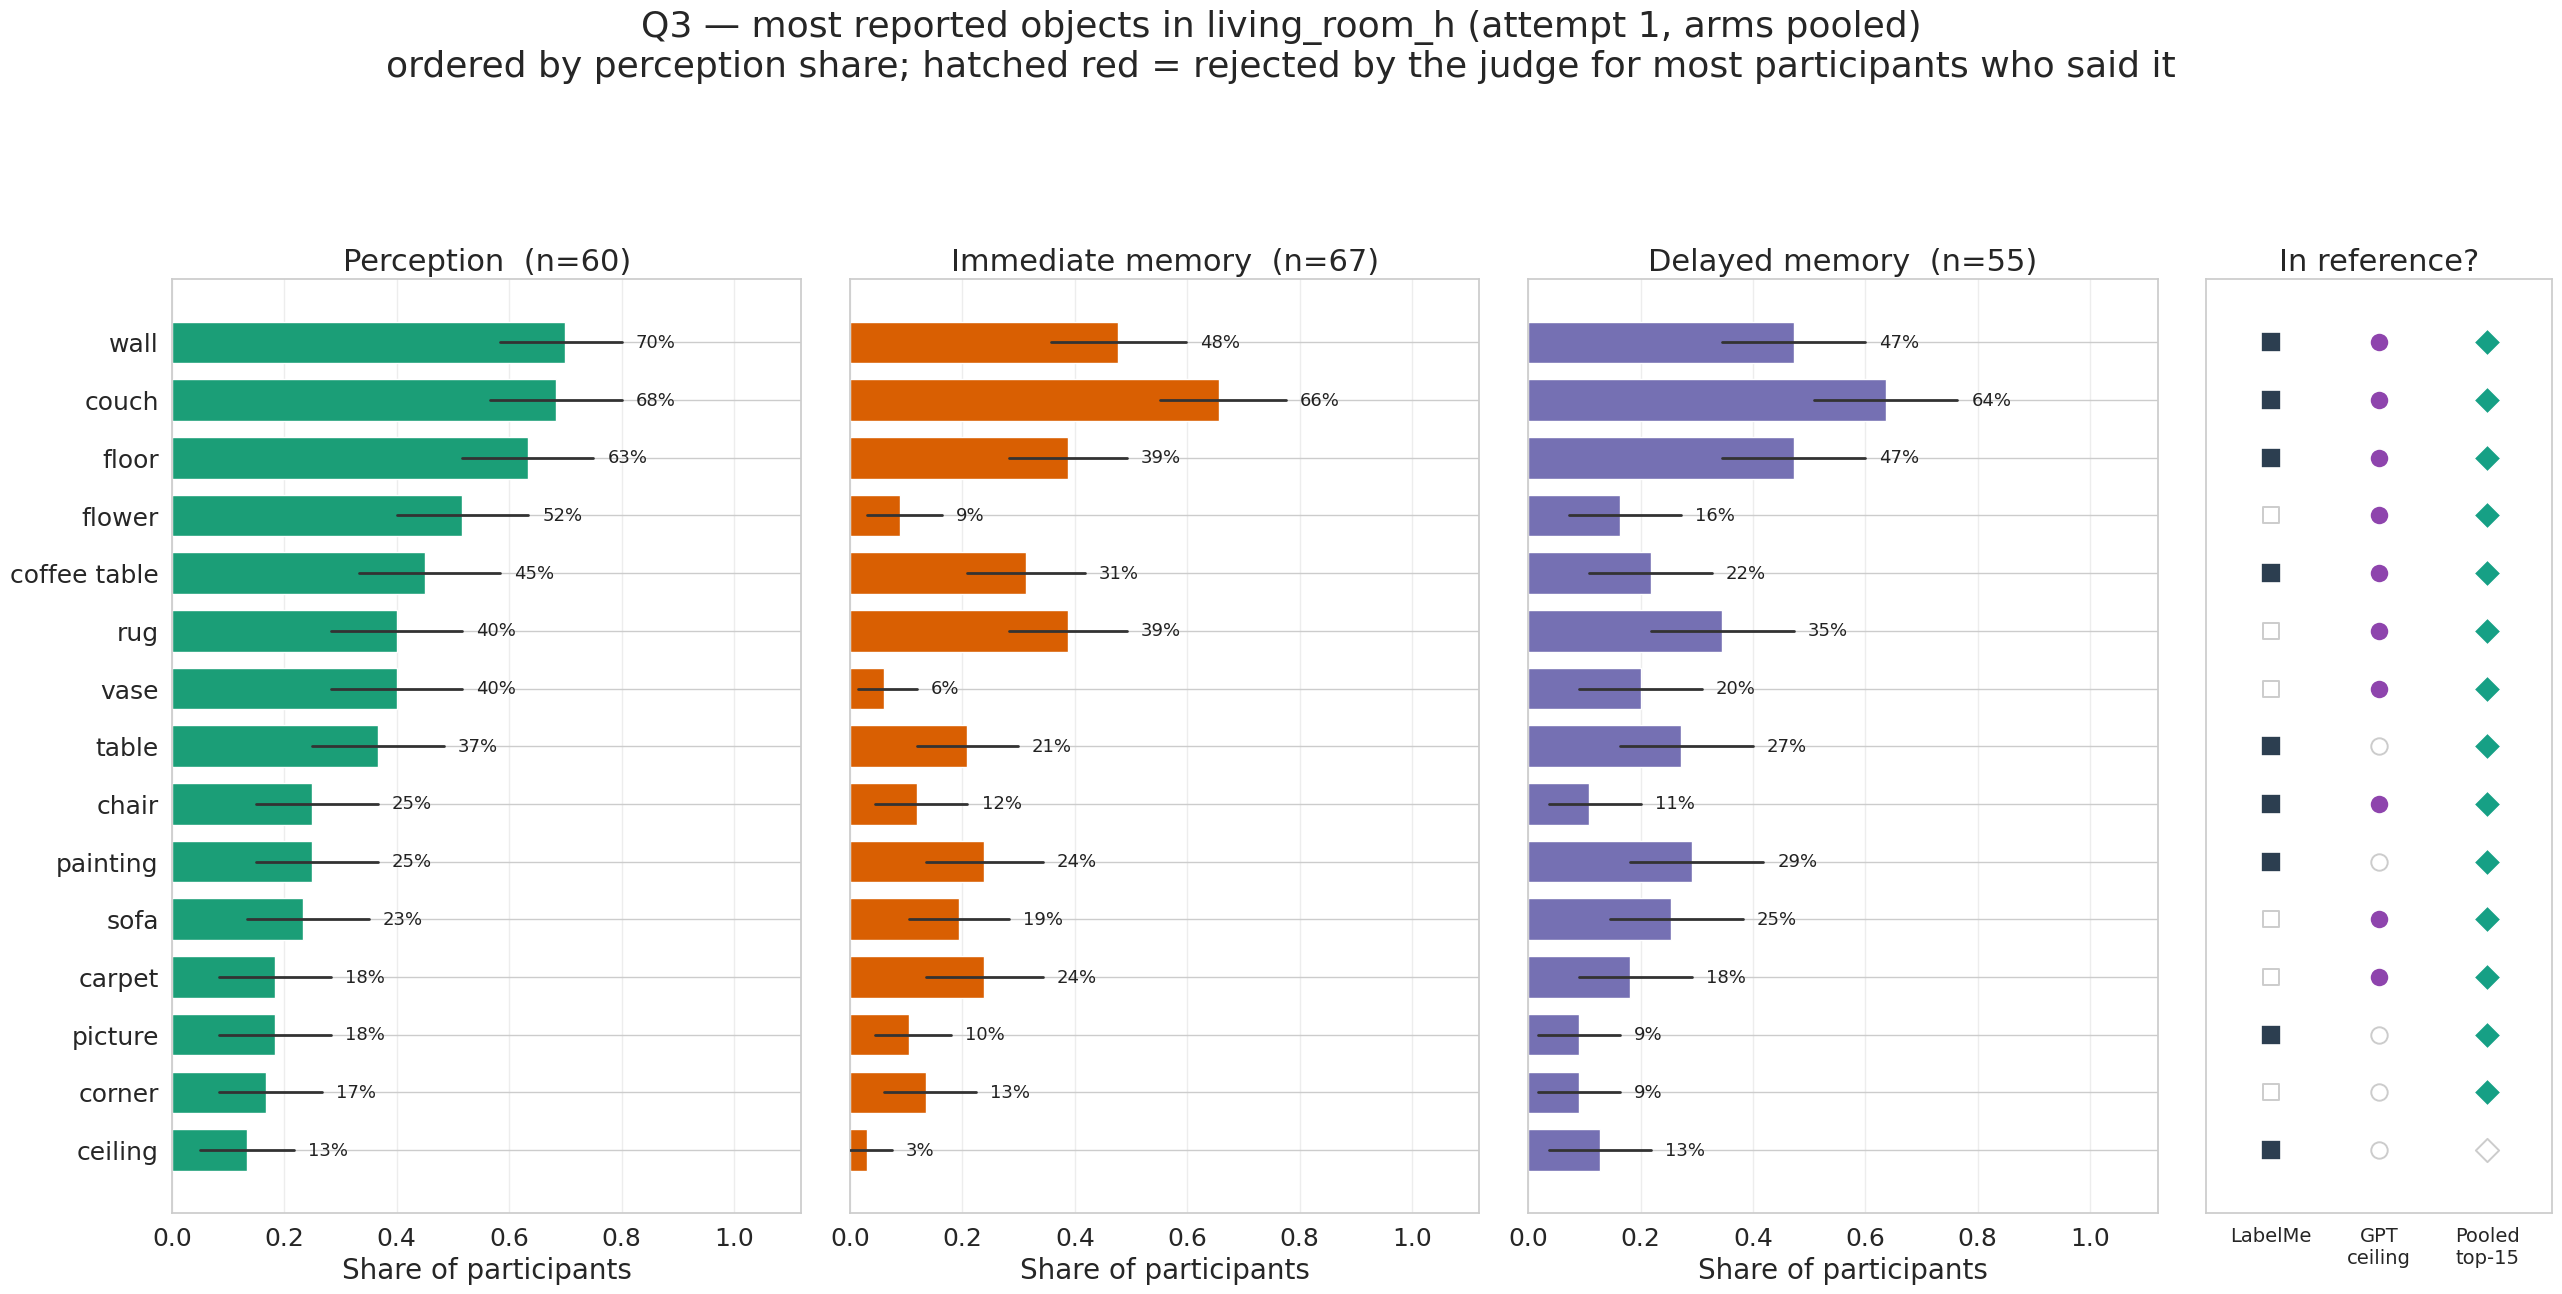

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_top_objects_conference_room_h.png


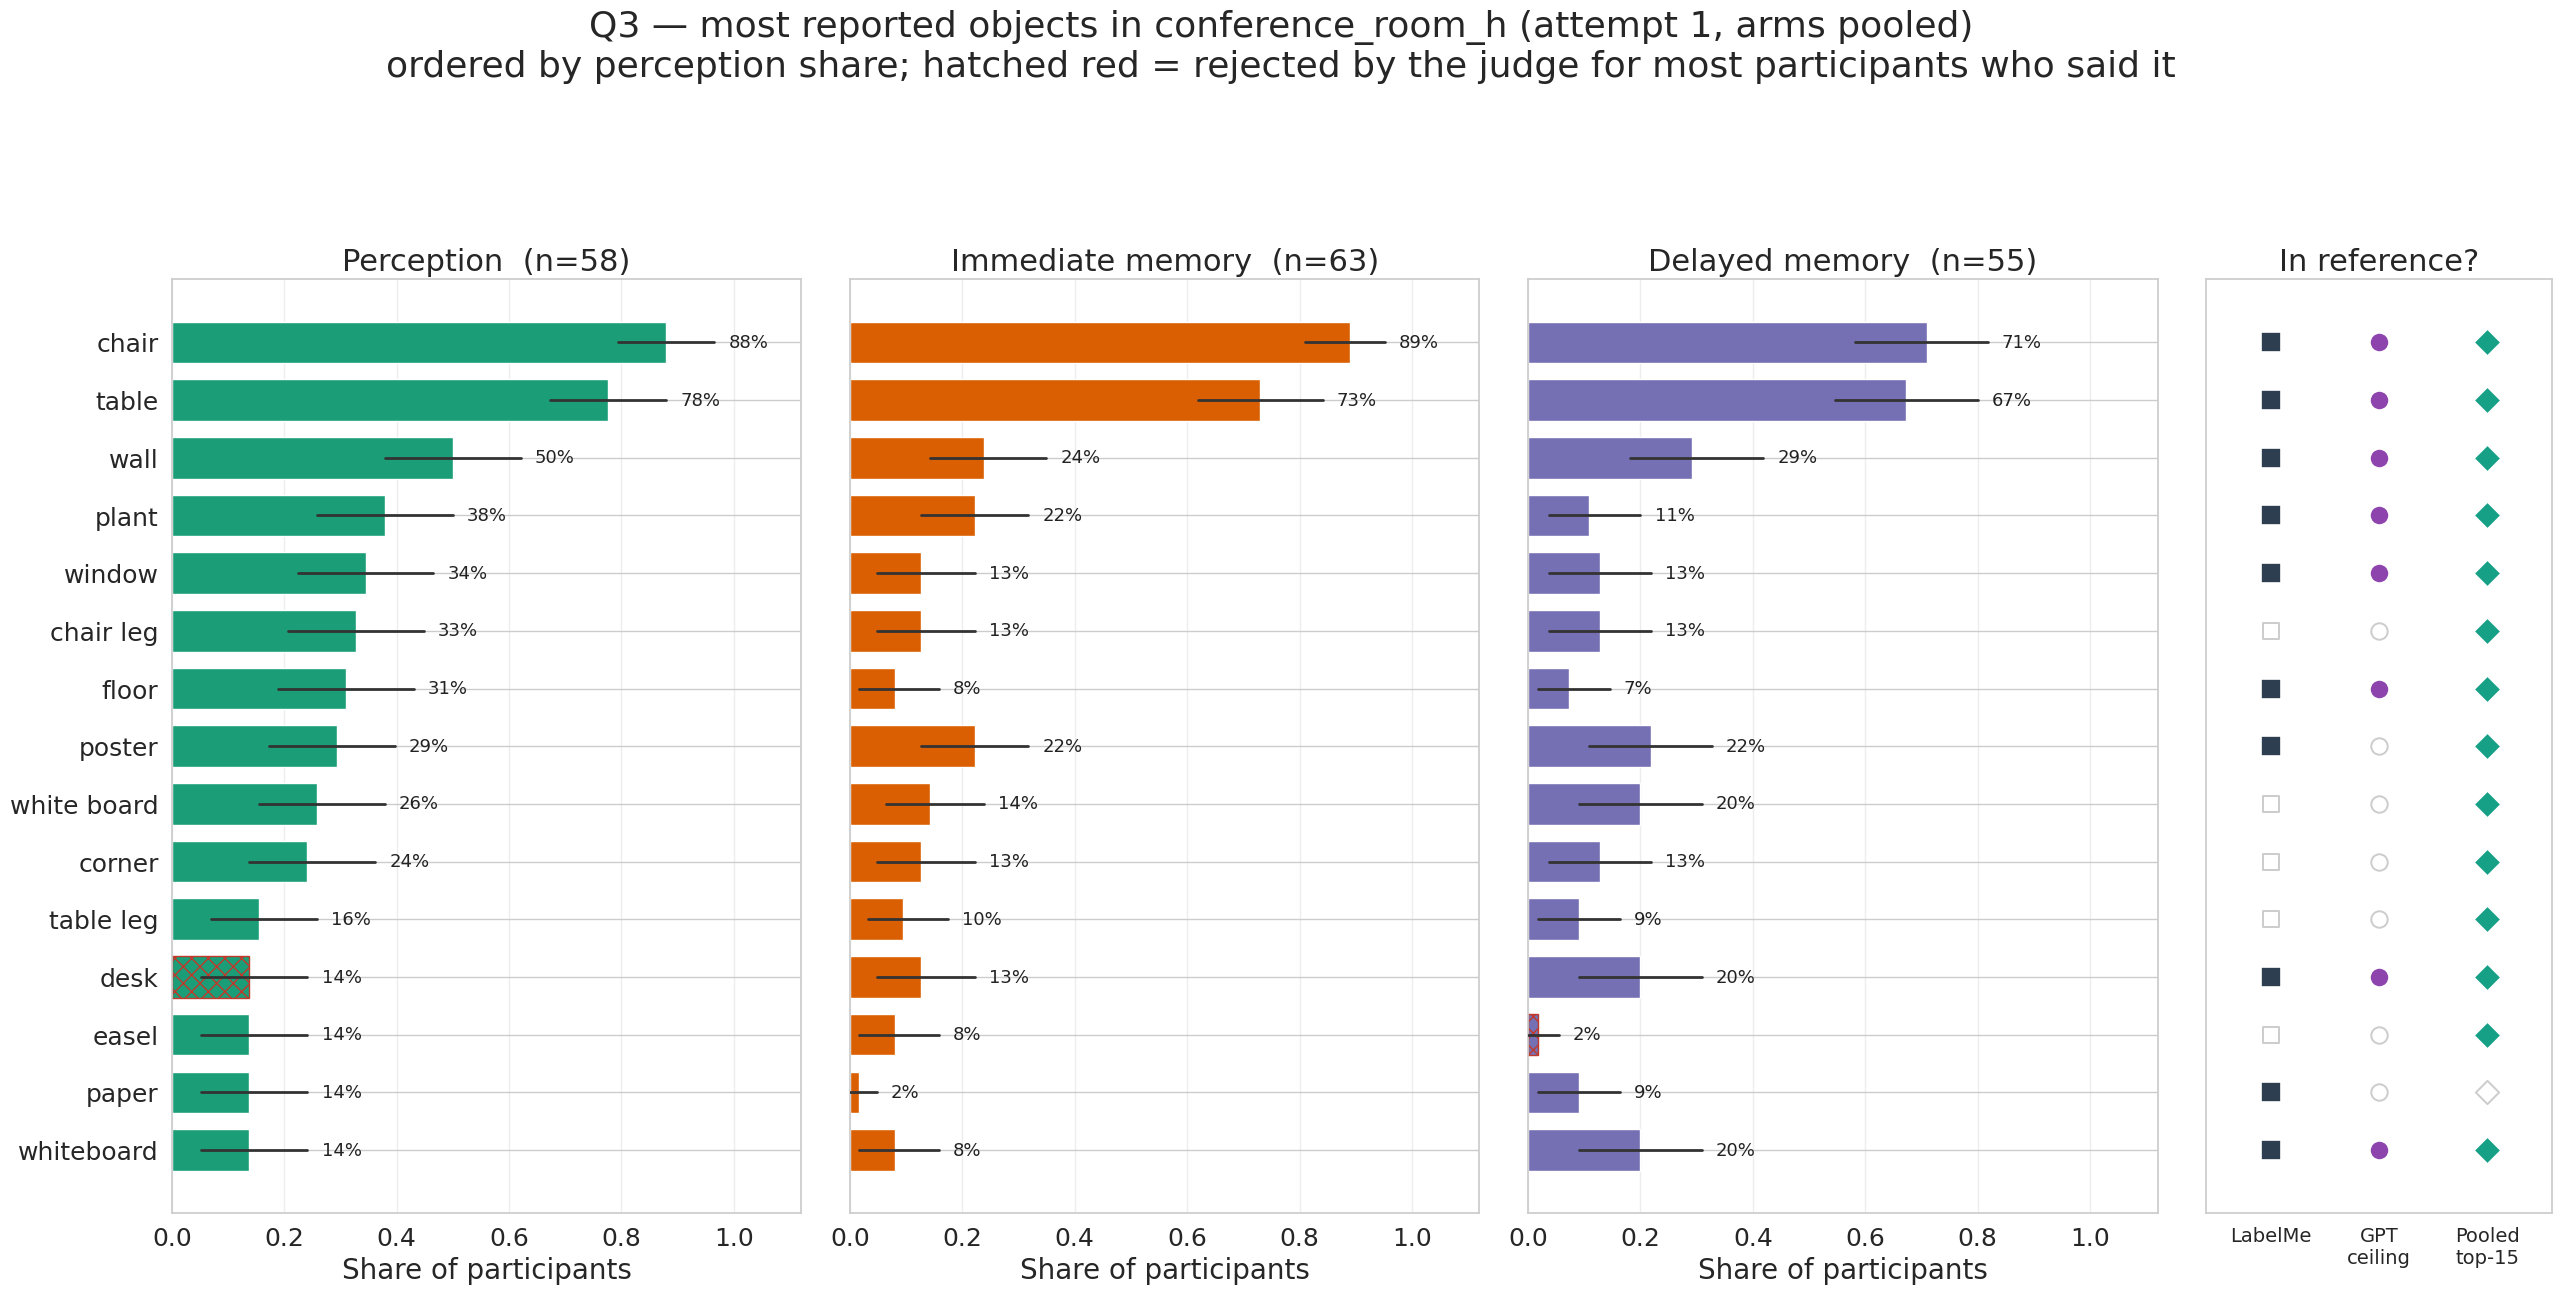

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_top_objects_lighthouse_h.png


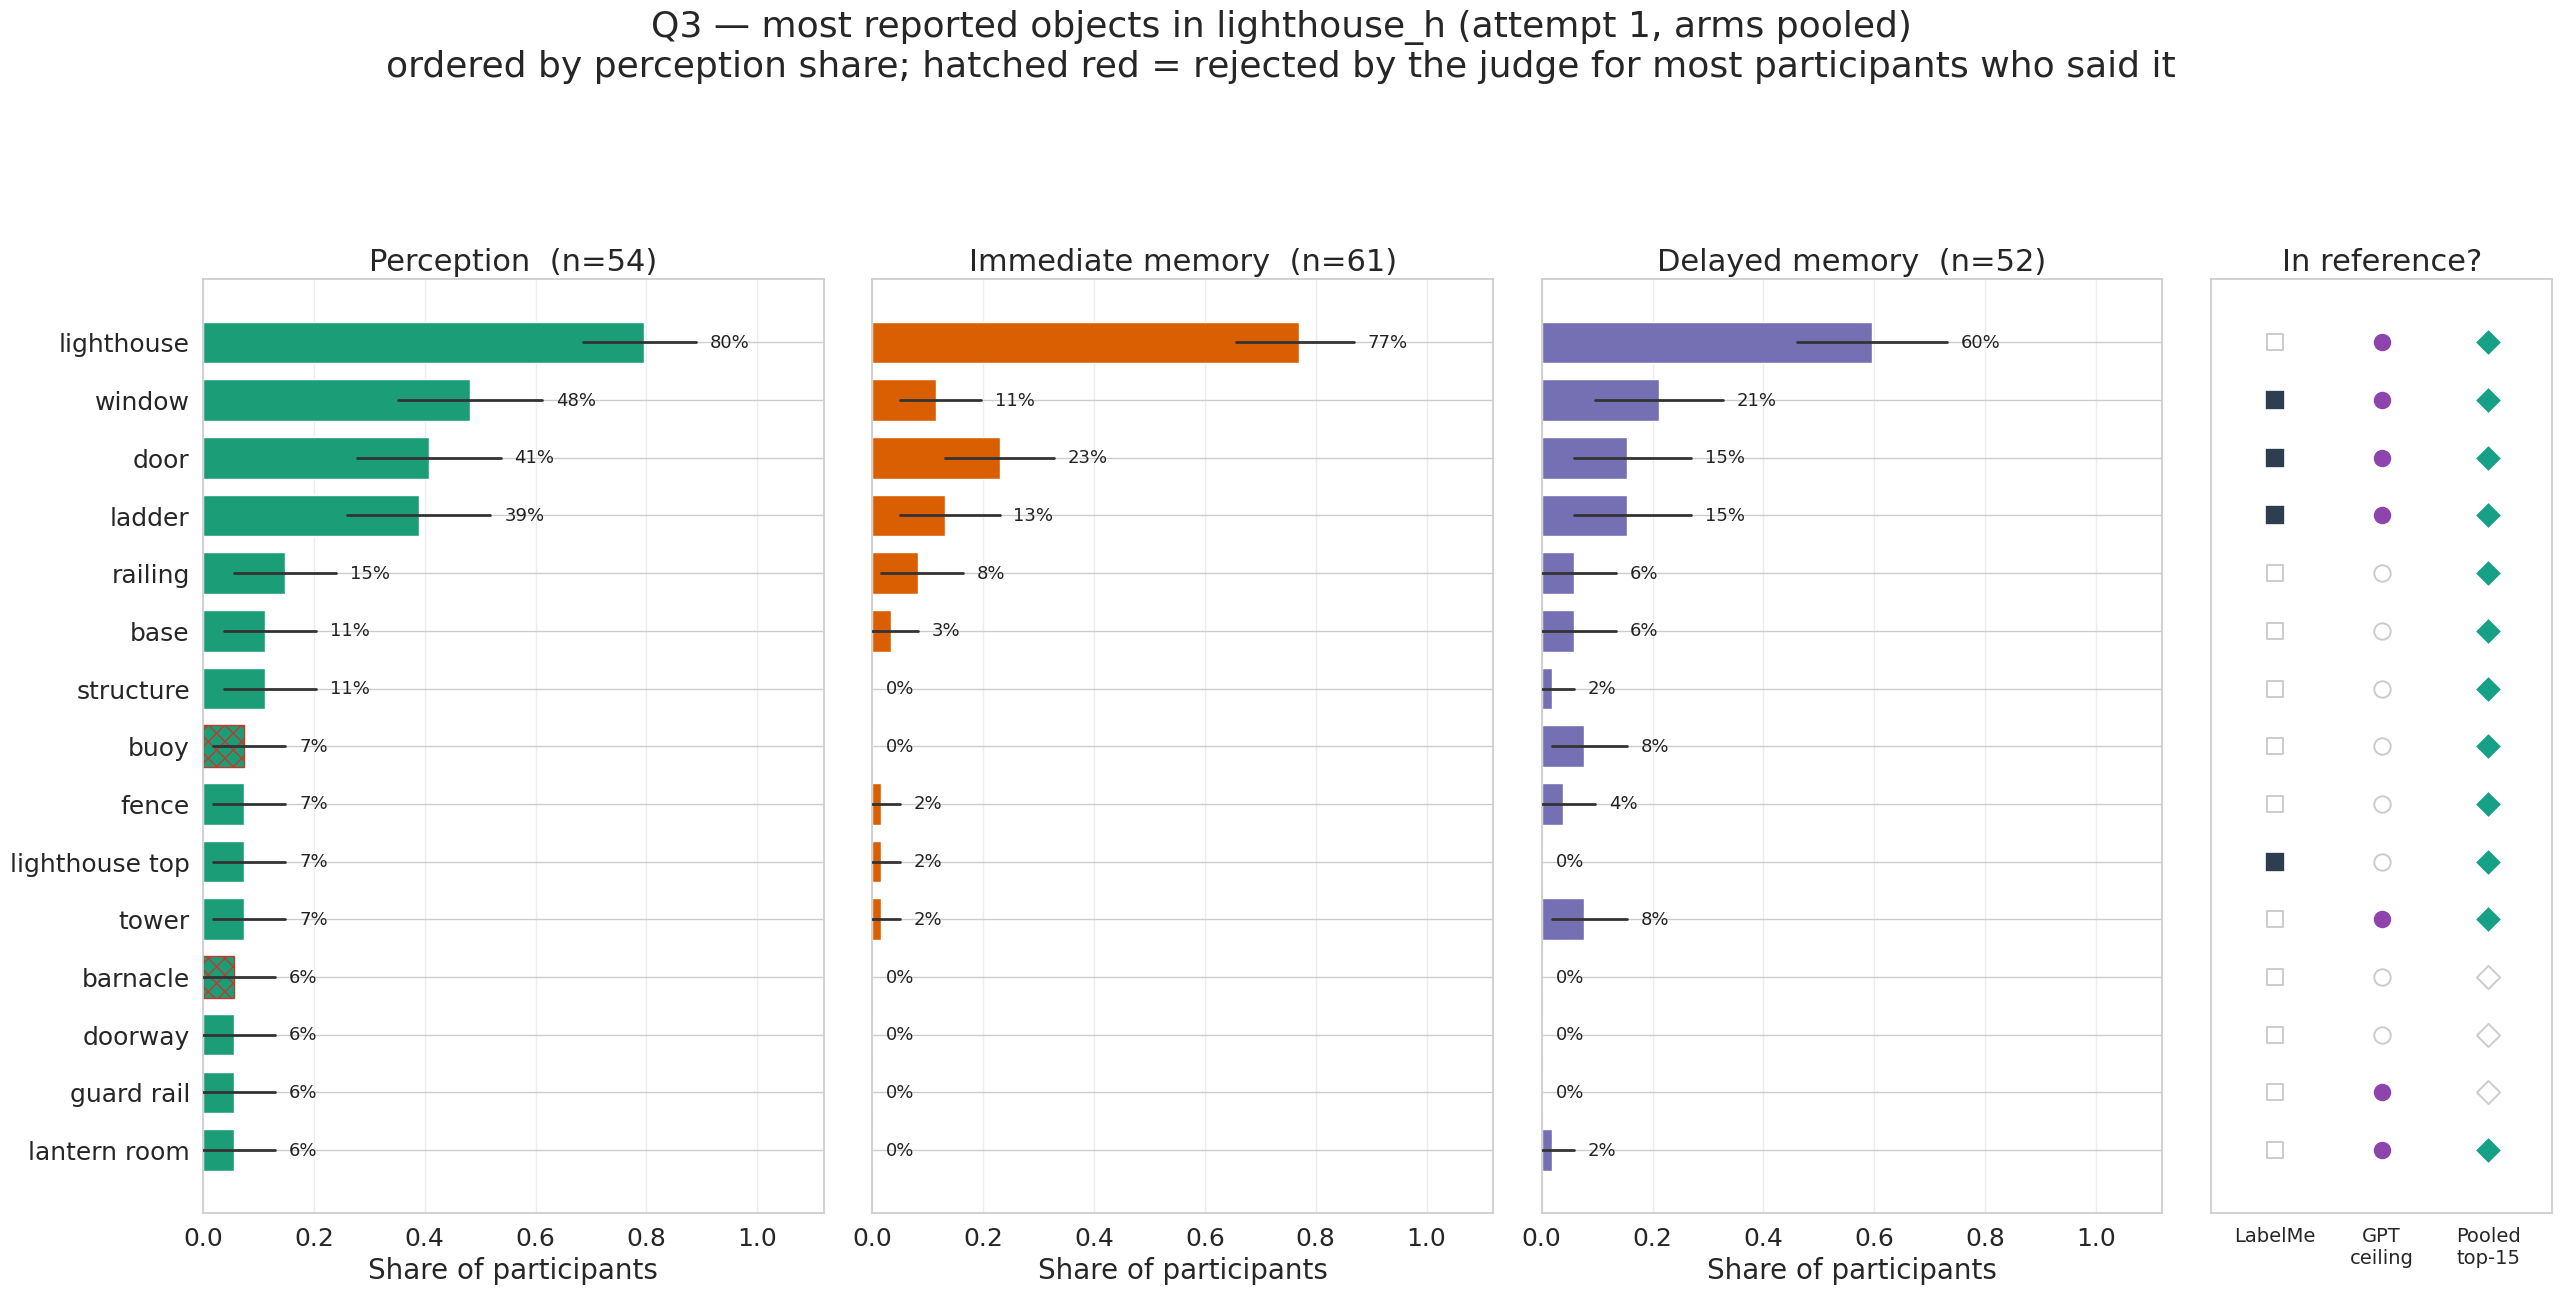

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_top_objects_playground_h.png


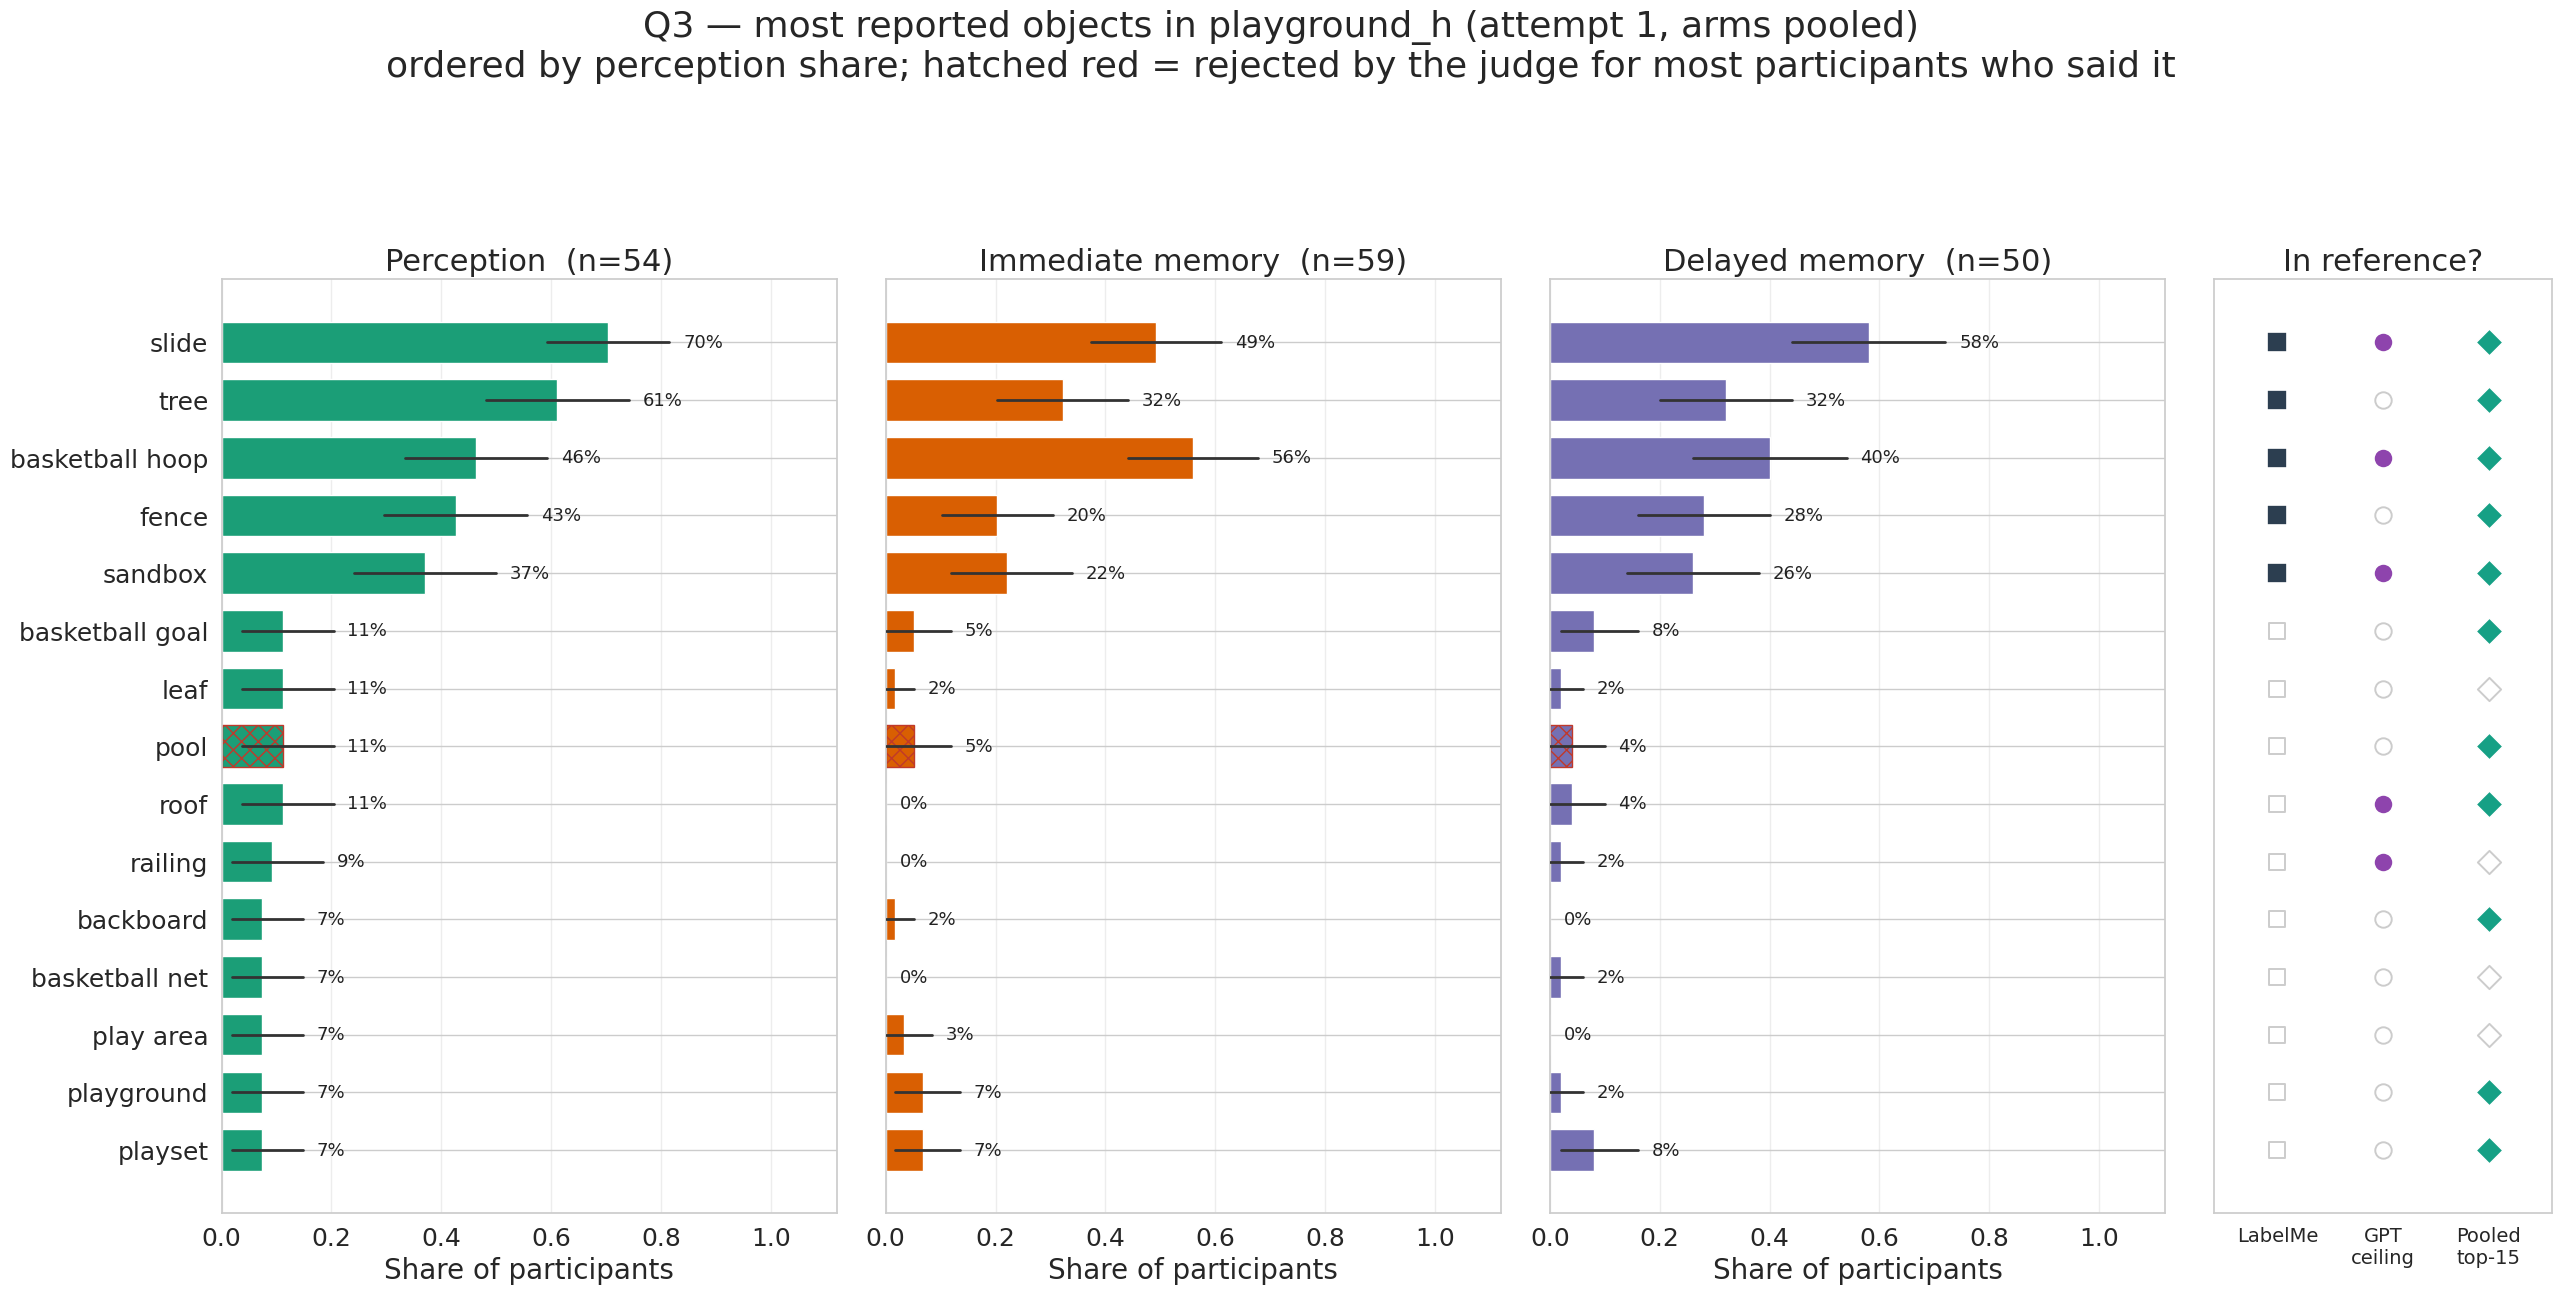

In [20]:
TOP_N = 15


def plot_top_objects(gt, top_n=TOP_N, save=True):
    s = share_gt_task[share_gt_task["gt"] == gt]
    order = (s[s["task"] == "perception"].head(top_n)["item"].tolist())
    # Fill up from the pooled ranking if perception alone does not reach top_n.
    for it in share_pooled[share_pooled["gt"] == gt]["item"]:
        if len(order) >= top_n:
            break
        if it not in order:
            order.append(it)
    order = order[:top_n][::-1]                 # reversed: highest share at the top of barh
    refs = reference_sets(gt, top_k=top_n)

    fig, axes = plt.subplots(1, 4, figsize=(26, 0.62 * top_n + 4),
                             gridspec_kw={"width_ratios": [1, 1, 1, 0.55]}, sharey=True)
    n_ppt = {}
    for ax, task in enumerate_tasks(axes[:3]):
        t = s[s["task"] == task].set_index("item")
        n_ppt[task] = int(t["n_ppt"].iloc[0]) if len(t) else 0
        shares = [t["share"].get(it, 0.0) for it in order]
        halluc = [t["frac_in_image"].get(it, np.nan) for it in order]
        colors = [TASK_COLORS[task]] * len(order)
        bars = ax.barh(range(len(order)), shares, color=colors, height=0.72,
                       edgecolor="white", zorder=2)
        for b, h in zip(bars, halluc):
            if not np.isnan(h) and h < 0.5:      # rejected for most who said it
                b.set_hatch("xx")
                b.set_edgecolor("#c0392b")
        # Bootstrap CI on a share = a proportion over participants. The label goes clear of
        # the whisker, not of the bar, or the two collide on every high-variance item.
        for i, it in enumerate(order):
            n = t["n_mentioning"].get(it, 0)
            N = n_ppt[task]
            if N < 2:
                continue
            lo, hi = boot_ci(np.r_[np.ones(int(n)), np.zeros(int(N - n))])
            right = shares[i]
            if not np.isnan(lo):
                ax.plot([lo, hi], [i, i], color=CI_COLOR, lw=2, zorder=4)
                right = max(right, hi)
            ax.text(right + 0.025, i, f"{shares[i]:.0%}", va="center", fontsize=13,
                    color=BAR_LABEL_COLOR)
        ax.set_yticks(range(len(order)))
        ax.set_yticklabels(order)
        ax.set_xlim(0, 1.12)
        ax.set_xlabel("Share of participants")
        ax.set_title(f"{TASK_LABELS[task]}  (n={n_ppt[task]})")
        ax.grid(True, axis="x", alpha=0.35)

    # Reference marker columns.
    ax = axes[3]
    names = list(refs)
    for j, name in enumerate(names):
        color = REF_COLOR.get(name, "#16a085")
        marker = REF_MARKERS.get(name, "D")
        hits = [it in refs[name] for it in order]
        ax.scatter([j] * sum(hits), [i for i, h in enumerate(hits) if h],
                   marker=marker, s=190, color=color, edgecolor="white", linewidth=1.2,
                   zorder=3)
        ax.scatter([j] * (len(order) - sum(hits)),
                   [i for i, h in enumerate(hits) if not h],
                   marker=marker, s=140, facecolor="white", edgecolor="#cccccc",
                   linewidth=1.4, zorder=2)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=14)
    ax.set_xlim(-0.6, len(names) - 0.4)
    ax.set_title("In reference?")
    ax.grid(False)

    fig.suptitle(f"Q3 — most reported objects in {GT_LABELS[gt]} (attempt 1, arms pooled)\n"
                 "ordered by perception share; hatched red = rejected by the judge for most "
                 "participants who said it")
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    if save:
        save_fig(fig, GRAPHS / f"q3_top_objects_{GT_LABELS[gt]}.png")
    plt.show()


for gt in GT_ORDER:
    plot_top_objects(gt)

### 4.3 The pooled consensus ranking

The data-driven object inventory the project does not currently have: for each image, what
share of the **whole pool** (all arms, tasks and attempts) reports each object. Bar colour is
the judge's verdict, so the items that are widely reported *and* widely rejected stand out —
those are the shared false memories, and they are the most interesting rows here.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_pooled_consensus_per_gt.png


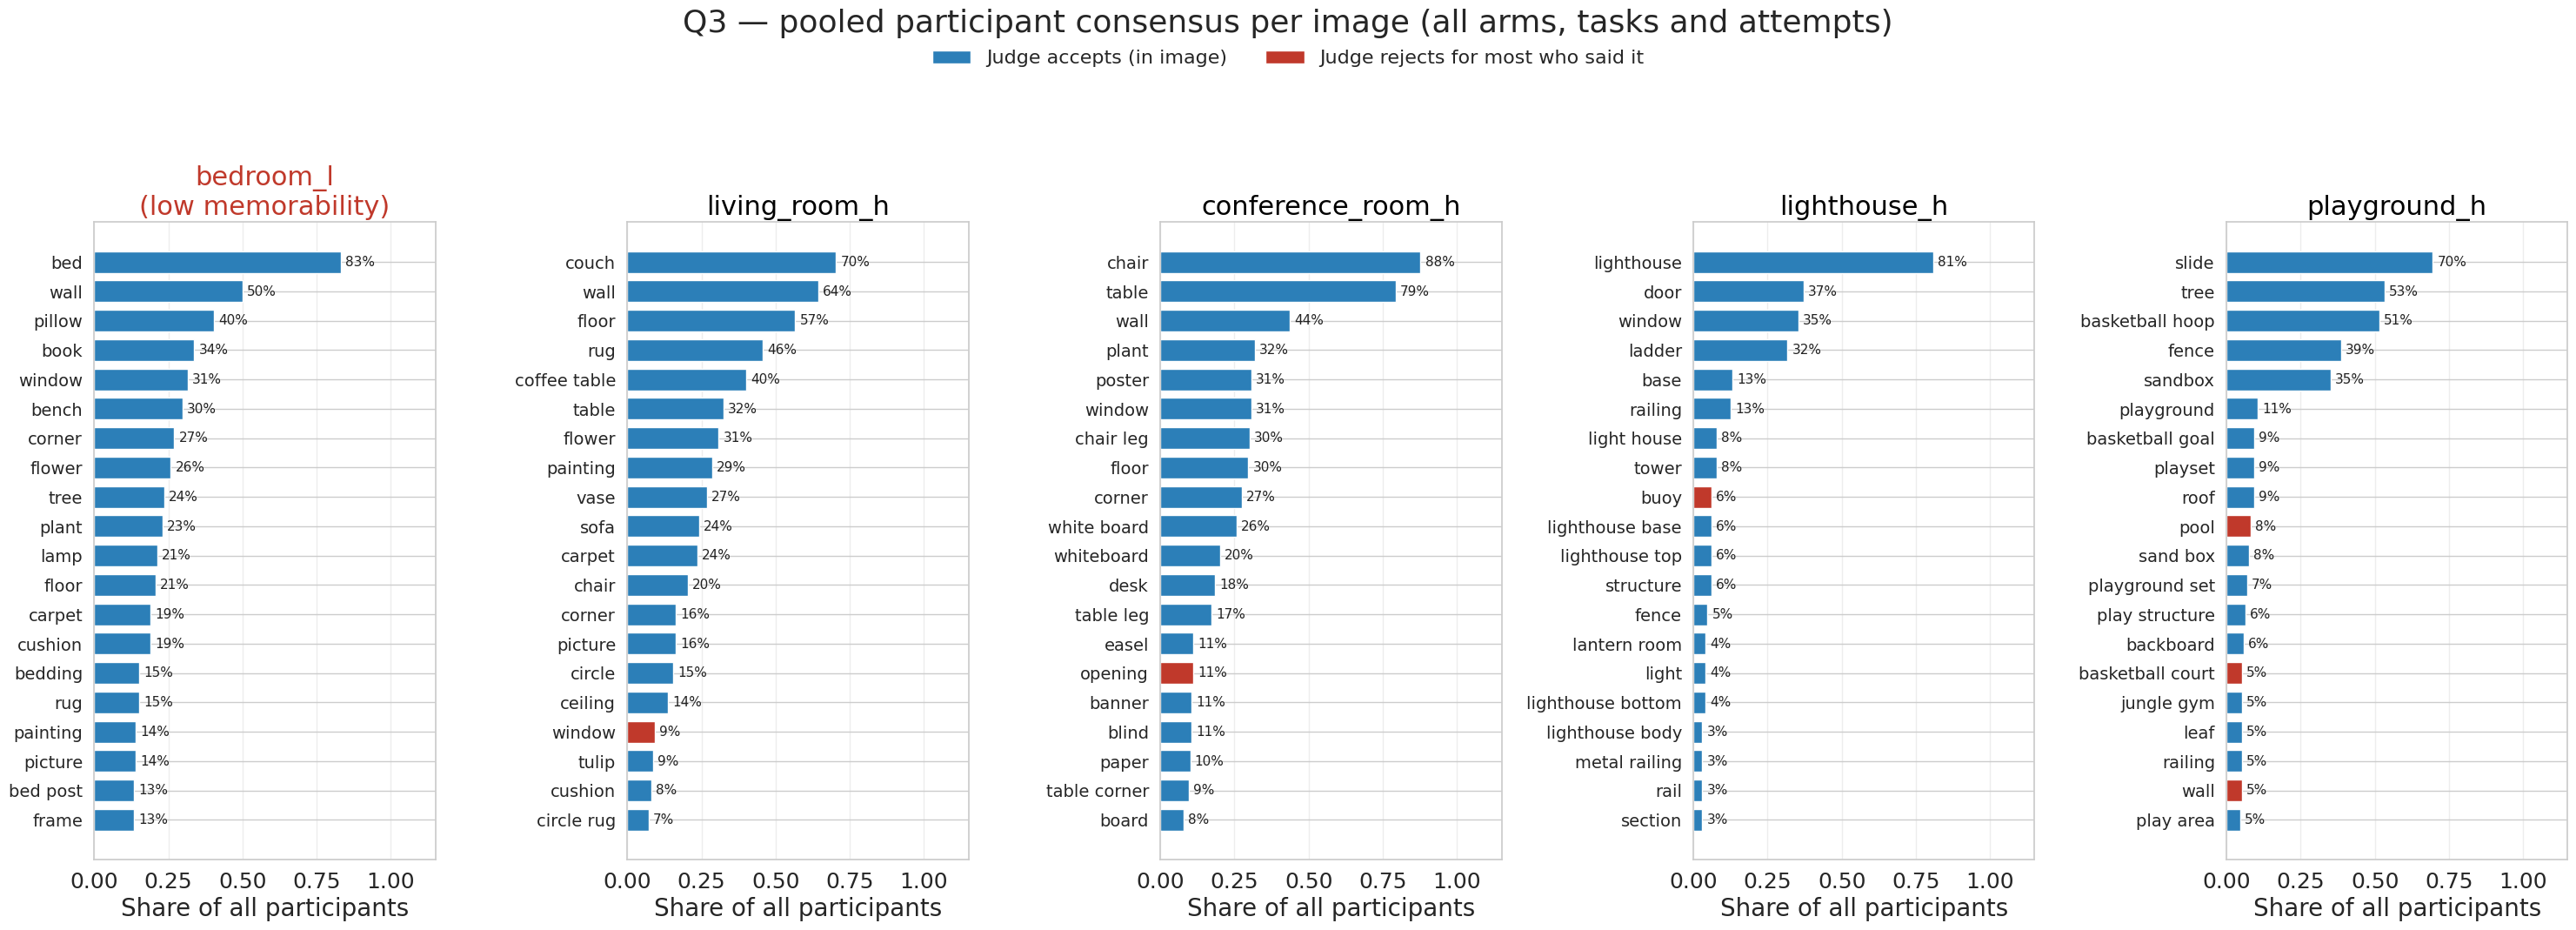

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(30, 11))
for ax, gt in zip(axes, GT_ORDER):
    s = share_pooled[share_pooled["gt"] == gt].head(20)[::-1]
    colors = ["#c0392b" if f < 0.5 else "#2c7fb8" for f in s["frac_in_image"]]
    ax.barh(range(len(s)), s["share"], color=colors, height=0.74, edgecolor="white")
    for i, (v, f) in enumerate(zip(s["share"], s["frac_in_image"])):
        ax.text(v + 0.015, i, f"{v:.0%}", va="center", fontsize=11, color=BAR_LABEL_COLOR)
    ax.set_yticks(range(len(s)))
    ax.set_yticklabels(s["item"], fontsize=14)
    ax.set_xlim(0, 1.15)
    ax.set_xlabel("Share of all participants")
    low = MEMORABILITY[gt] == "low"
    ax.set_title(GT_LABELS[gt] + ("\n(low memorability)" if low else ""),
                 color="#c0392b" if low else "black")
    ax.grid(True, axis="x", alpha=0.35)
handles = [Patch(facecolor="#2c7fb8", label="Judge accepts (in image)"),
           Patch(facecolor="#c0392b", label="Judge rejects for most who said it")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=2,
           frameon=False)
fig.suptitle("Q3 — pooled participant consensus per image (all arms, tasks and attempts)")
fig.tight_layout(rect=(0, 0, 1, 0.90))
save_fig(fig, GRAPHS / "q3_pooled_consensus_per_gt.png")
plt.show()

### 4.4 Do participants agree with each other?

Three views of the same question, because no single number captures it:

- **Consensus curve** — share against rank. A steep, short curve means everyone names the same
  few things; a long flat tail means idiosyncratic reporting.
- **Mean pairwise Jaccard** — for every pair of participants, |A∩B| / |A∪B| over their
  attempt-1 object sets, averaged. The direct measure of "did two people describe the same
  scene the same way". The CI resamples *participants*, which is what makes it a CI on the
  pool rather than on the pairs.
- **Top-5 concentration** — the share of all mentions captured by the five most common items.

In [22]:
def _mean_pairwise_jaccard(sets, ids=None):
    """Mean Jaccard over all distinct pairs.

    `ids` labels which original participant each set came from. Pairs sharing an id are
    skipped - this matters only in the bootstrap, where resampling with replacement draws the
    same participant twice and pairing them with themselves would contribute a spurious 1.0
    and bias the interval upward.
    """
    if len(sets) < 2:
        return np.nan
    idx = range(len(sets))
    vals = [len(sets[a] & sets[b]) / len(sets[a] | sets[b])
            for a, b in itertools.combinations(idx, 2)
            if (sets[a] | sets[b]) and (ids is None or ids[a] != ids[b])]
    return float(np.mean(vals)) if vals else np.nan


def jaccard_ci(sets, n_boot=500, seed=0):
    """Mean pairwise Jaccard, with a CI from resampling PARTICIPANTS (not pairs) - the pairs
    are not independent, so a CI over pairs would be far too narrow.

    The interval is asymmetric around the point estimate by construction, so callers draw it
    as a segment from lo to hi rather than as +/- error bars.
    """
    sets = [s for s in sets if s]
    m = _mean_pairwise_jaccard(sets)
    if np.isnan(m) or len(sets) < 3:
        return m, np.nan, np.nan
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(sets), len(sets))
        v = _mean_pairwise_jaccard([sets[i] for i in idx], ids=idx)
        if not np.isnan(v):
            boots.append(v)
    if not boots:
        return m, np.nan, np.nan
    return m, float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


def draw_interval(ax, x, lo, hi, width=0.10):
    """A lo-hi segment with end caps. Used instead of ax.errorbar wherever the interval is
    not symmetric about the mean, which errorbar's yerr cannot express."""
    if np.isnan(lo) or np.isnan(hi):
        return
    ax.plot([x, x], [lo, hi], color=CI_COLOR, lw=2.2, zorder=5, solid_capstyle="butt")
    for y in (lo, hi):
        ax.plot([x - width / 2, x + width / 2], [y, y], color=CI_COLOR, lw=2.2, zorder=5)


def participant_sets(data, keys, attempts=(1,)):
    """{key -> [set of objects per participant]}, the input to every Jaccard number below."""
    d = data[data["attempt"].isin(attempts)] if attempts else data
    out = {}
    for k, grp in d.groupby(list(keys)):
        out[k] = [set(g["item"]) for _, g in grp.groupby("uid")]
    return out

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_consensus_curves.png


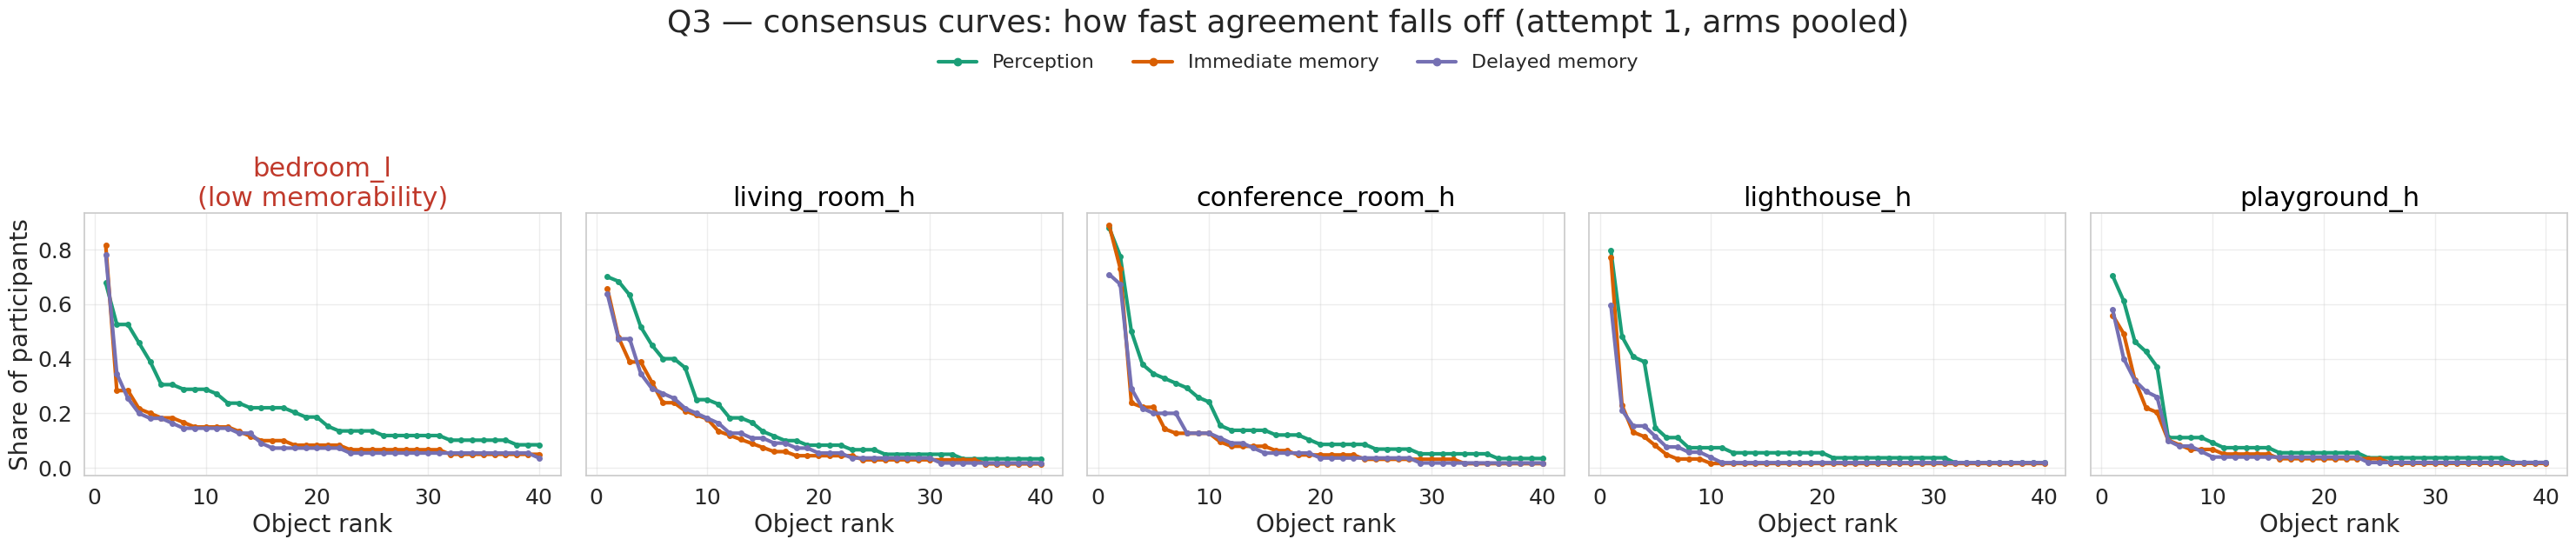

In [23]:
# --- consensus curves ---
fig, axes = plt.subplots(1, 5, figsize=(30, 6.5), sharey=True)
for ax, gt in zip(axes, GT_ORDER):
    for task in TASK_ORDER:
        s = share_gt_task[(share_gt_task["gt"] == gt) &
                          (share_gt_task["task"] == task)].head(40)
        ax.plot(range(1, len(s) + 1), s["share"].values, color=TASK_COLORS[task], lw=3,
                marker="o", markersize=4, label=TASK_LABELS[task])
    low = MEMORABILITY[gt] == "low"
    ax.set_title(GT_LABELS[gt] + ("\n(low memorability)" if low else ""),
                 color="#c0392b" if low else "black")
    ax.set_xlabel("Object rank")
    ax.set_ylabel("Share of participants" if ax is axes[0] else "")
    ax.grid(True, alpha=0.35)
fig.suptitle("Q3 — consensus curves: how fast agreement falls off (attempt 1, arms pooled)")
handles = [Line2D([], [], color=TASK_COLORS[t], lw=3, marker="o", label=TASK_LABELS[t])
           for t in TASK_ORDER]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=3,
           frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.86))
save_fig(fig, GRAPHS / "q3_consensus_curves.png")
plt.show()

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_agreement.png


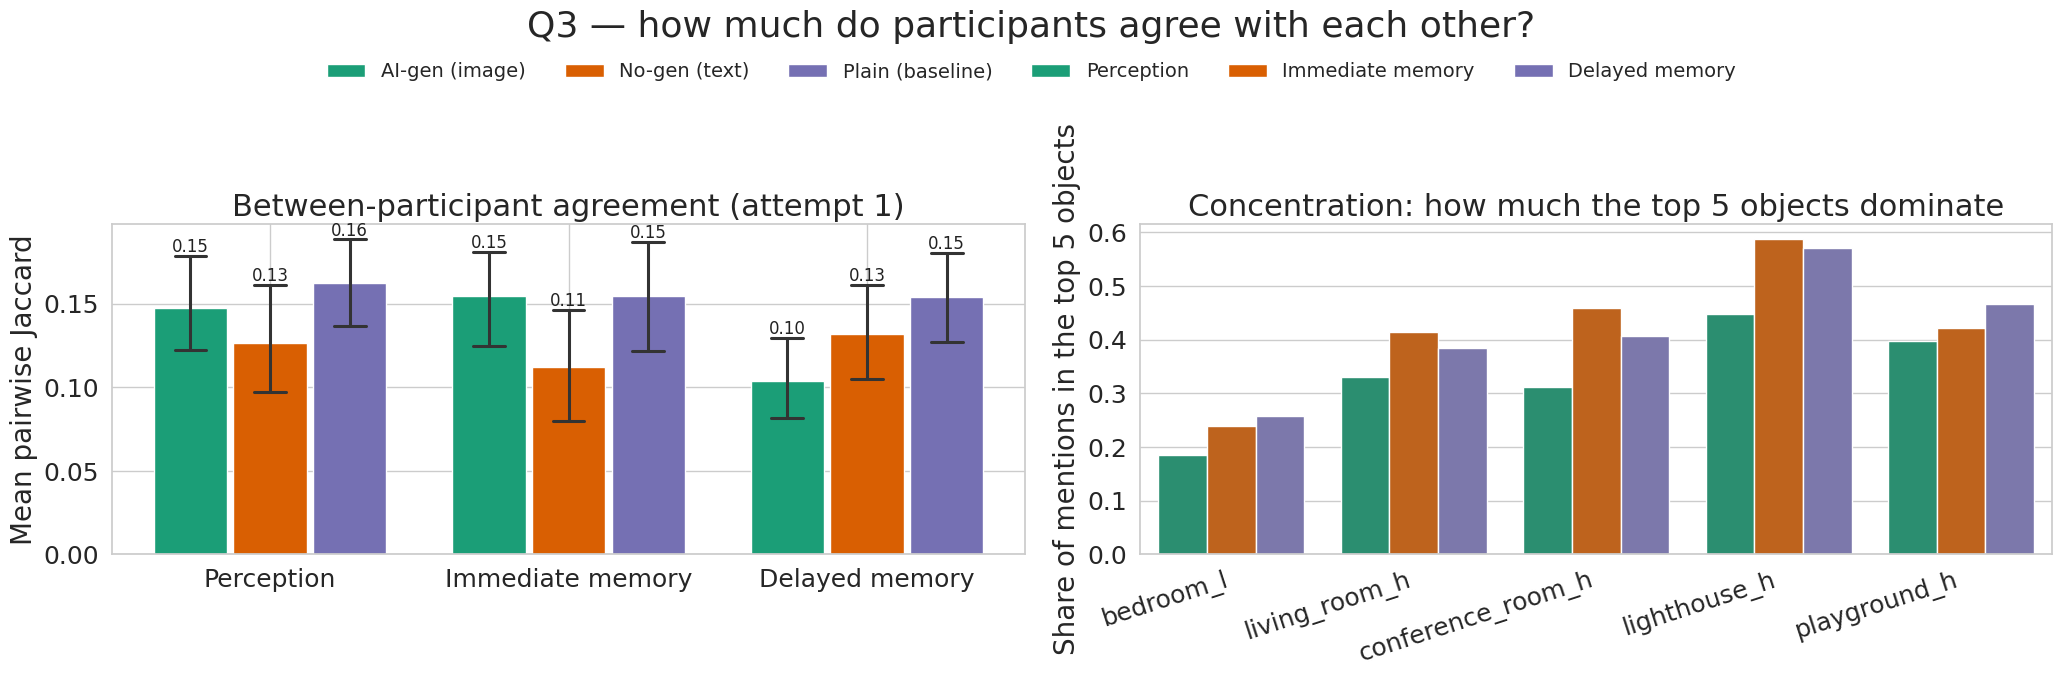

task,delay,immediate,perception
generation,,,
aigen,0.104,0.155,0.147
nogen,0.132,0.112,0.127
plain,0.154,0.155,0.163


In [24]:
# --- mean pairwise Jaccard + top-5 concentration ---
rows = []
for (gen, task), sets in participant_sets(objs, ["generation", "task"]).items():
    m, lo, hi = jaccard_ci(sets)
    rows.append({"generation": gen, "task": task, "jaccard": m, "lo": lo, "hi": hi,
                 "n": len(sets)})
jac = pd.DataFrame(rows)

conc = []
for (gt, task), grp in share_gt_task.groupby(["gt", "task"]):
    tot = grp["n_mentioning"].sum()
    conc.append({"gt": gt, "task": task,
                 "top5_share": grp.head(5)["n_mentioning"].sum() / tot if tot else np.nan})
conc = pd.DataFrame(conc)

fig, axes = plt.subplots(1, 2, figsize=(21, 7))
ax = axes[0]
gens = gens_present(jac)
g_ = geom(gens)
offsets, width = g_
for i, task in enumerate(TASK_ORDER):
    for gen in gens:
        r = jac[(jac["task"] == task) & (jac["generation"] == gen)]
        if r.empty or np.isnan(r["jaccard"].iloc[0]):
            continue
        r = r.iloc[0]
        ax.bar(i + offsets[gen], r["jaccard"], width=width * 0.92, color=GEN_COLORS[gen],
               zorder=2)
        draw_interval(ax, i + offsets[gen], r["lo"], r["hi"], width=width * 0.4)
        ax.text(i + offsets[gen], max(r["hi"], r["jaccard"]) if not np.isnan(r["hi"])
                else r["jaccard"],
                f"{r['jaccard']:.2f}", ha="center", va="bottom", fontsize=12,
                color=BAR_LABEL_COLOR)
ax.set_xticks(range(len(TASK_ORDER)))
ax.set_xticklabels([TASK_LABELS[t] for t in TASK_ORDER])
ax.set_ylabel("Mean pairwise Jaccard")
ax.set_title("Between-participant agreement (attempt 1)")
style_count_axis(ax)

ax = axes[1]
sns.barplot(data=conc, x="gt", y="top5_share", hue="task", order=GT_ORDER,
            hue_order=TASK_ORDER, palette=TASK_COLORS, errorbar=None, legend=False, ax=ax)
ax.set_xticks(range(len(GT_ORDER)))
ax.set_xticklabels([GT_LABELS[g] for g in GT_ORDER], rotation=18, ha="right")
ax.set_xlabel(""); ax.set_ylabel("Share of mentions in the top 5 objects")
ax.set_title("Concentration: how much the top 5 objects dominate")
style_count_axis(ax)

fig.suptitle("Q3 — how much do participants agree with each other?")
handles = [Patch(facecolor=GEN_COLORS[g], label=GEN_LABELS[g]) for g in gens]
handles += [Patch(facecolor=TASK_COLORS[t], label=TASK_LABELS[t]) for t in TASK_ORDER]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.93),
           ncol=len(handles), frameon=False, fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.85))
save_fig(fig, GRAPHS / "q3_agreement.png")
plt.show()

display(jac.pivot_table(index="generation", columns="task", values="jaccard").round(3))

### 4.5 Widely reported, and not in the image

The qualitative payoff: objects that many participants report but the judge rejects — candidate
**shared false memories**, as opposed to the one-off errors the aggregate hallucination rate in
§1.2 is mostly made of.

The first number below is itself a result: consensus and accuracy go together, so the threshold
has to be dropped into the 10–20% band before any rejected item appears at all.

> **These are probably not false memories.** Almost all of them come from the **perception**
> condition, where the participant had the picture in front of them — the one condition in
> which a false memory is least plausible. A `desk` in a conference room, a `window` in a
> living room and a `door` in a bedroom are far more likely judge/vocabulary disagreements
> about near-synonyms and partly-visible objects than things people wrongly remembered. Treat
> this table as an **audit of the judge**, and check the flagged items against the images
> before reading anything psychological into them.

In [25]:
# How far down the consensus ranking do you have to go before the judge starts disagreeing?
for thr in (0.30, 0.20, 0.15, 0.10, 0.05):
    band = share_gt_task[share_gt_task["share"] >= thr]
    bad = band[band["frac_in_image"] < 0.5]
    print(f"share >= {thr:.0%}: {len(band):4d} (gt, task, item) combinations, "
          f"{len(bad):3d} rejected for most who said them "
          f"(lowest acceptance in the band: {band['frac_in_image'].min():.2f})")

SHARED_THR = 0.08     # low enough to surface the shared errors, high enough to exclude one-offs
shared_halluc = (share_gt_task[(share_gt_task["share"] >= SHARED_THR) &
                               (share_gt_task["frac_in_image"] < 0.6)]
                 .sort_values("share", ascending=False))
print(f"\nObjects reported by >={SHARED_THR:.0%} of participants and accepted for fewer than "
      f"60% of them ({len(shared_halluc)} combinations):")
display(shared_halluc[["gt", "task", "item", "n_mentioning", "n_ppt", "share",
                       "frac_in_image"]].round(3).reset_index(drop=True))

share >= 30%:   55 (gt, task, item) combinations,   0 rejected for most who said them (lowest acceptance in the band: 1.00)
share >= 20%:  100 (gt, task, item) combinations,   0 rejected for most who said them (lowest acceptance in the band: 0.81)
share >= 15%:  123 (gt, task, item) combinations,   0 rejected for most who said them (lowest acceptance in the band: 0.67)
share >= 10%:  191 (gt, task, item) combinations,   3 rejected for most who said them (lowest acceptance in the band: 0.00)
share >= 5%:  376 (gt, task, item) combinations,  19 rejected for most who said them (lowest acceptance in the band: 0.00)

Objects reported by >=8% of participants and accepted for fewer than 60% of them (6 combinations):


,gt,task,item,n_mentioning,n_ppt,share,frac_in_image
0,conference_room_h.jpg,perception,desk,8,58,0.138,0.375
1,bedroom_l.jpg,perception,door,8,59,0.136,0.125
2,playground_h.jpg,perception,pool,6,54,0.111,0.000
3,bedroom_l.jpg,perception,rose,5,59,0.085,0.400
4,bedroom_l.jpg,immediate,table,5,60,0.083,0.400
5,living_room_h.jpg,perception,window,5,60,0.083,0.000


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q3_consensus_vs_accuracy.png


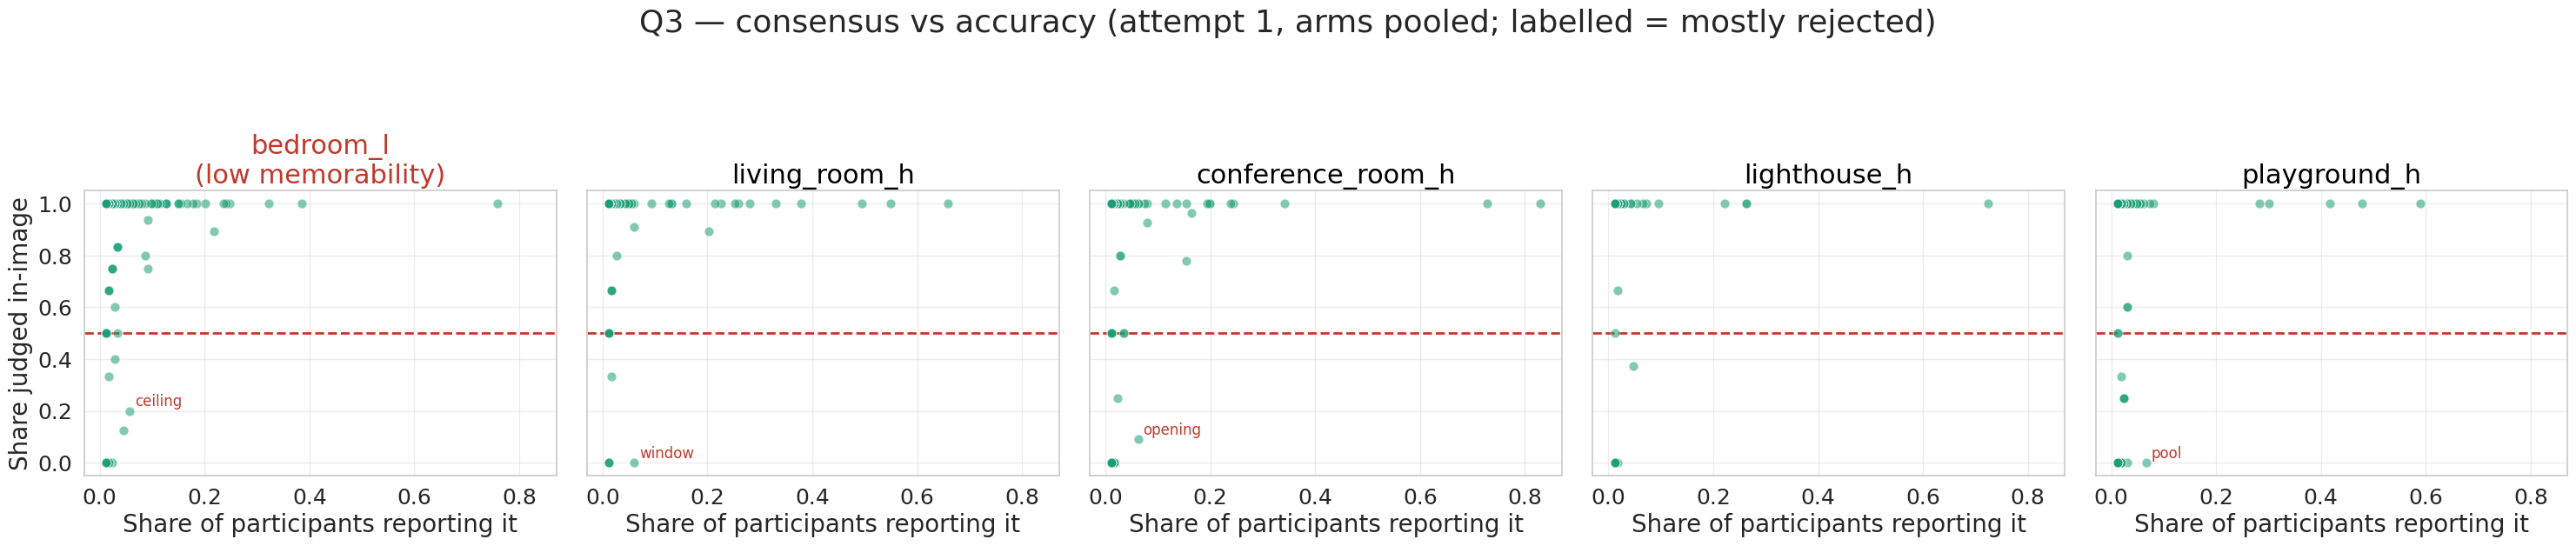

In [26]:
# The same thing as a picture, pooled over tasks: consensus on the x axis, the judge's
# acceptance on the y. The bottom-right corner is where shared false memories live.
pool_acc = item_share(objs, keys=("gt",), attempts=(1,))
fig, axes = plt.subplots(1, 5, figsize=(30, 6.5), sharey=True, sharex=True)
for ax, gt in zip(axes, GT_ORDER):
    s = pool_acc[(pool_acc["gt"] == gt) & (pool_acc["n_mentioning"] >= 2)]
    ax.scatter(s["share"], s["frac_in_image"], s=60, alpha=0.55,
               color=TASK_COLORS["perception"], edgecolor="white", linewidth=0.6, zorder=3)
    for _, r in s[(s["frac_in_image"] < 0.6) & (s["share"] >= 0.05)].iterrows():
        ax.annotate(r["item"], (r["share"], r["frac_in_image"]), fontsize=12,
                    xytext=(4, 4), textcoords="offset points", color="#c0392b")
    ax.axhline(0.5, color="#c0392b", ls="--", lw=2, zorder=1)
    low = MEMORABILITY[gt] == "low"
    ax.set_title(GT_LABELS[gt] + ("\n(low memorability)" if low else ""),
                 color="#c0392b" if low else "black")
    ax.set_xlabel("Share of participants reporting it")
    ax.set_ylabel("Share judged in-image" if ax is axes[0] else "")
    ax.grid(True, alpha=0.35)
fig.suptitle("Q3 — consensus vs accuracy (attempt 1, arms pooled; labelled = mostly rejected)")
fig.tight_layout(rect=(0, 0, 1, 0.90))
save_fig(fig, GRAPHS / "q3_consensus_vs_accuracy.png")
plt.show()

---
# 5. Q4 — what gets *added* on attempts 2 and 3?

Counts rise across attempts. This section asks what that rise is made of: whether it is the
**same objects arriving late for everyone** (typical items people simply had not got to yet),
or **idiosyncratic per-participant elaboration**, and whether the additions are accurate.

Per participant × image, the object set at each attempt gives three quantities per transition:
`added = A(n) − A(n−1)`, `dropped = A(n−1) − A(n)`, `kept = A(n) ∩ A(n−1)`. aigen + nogen only.

In [28]:
def transitions(data, gens=FB_GENS):
    """One row per (uid, gt, transition) with the added / dropped / kept item sets."""
    d = data[data["generation"].isin(gens)]
    rows = []
    for (gen, task, uid, gt), grp in d.groupby(["generation", "task", "uid", "gt"]):
        by_att = {a: set(g["item"]) for a, g in grp.groupby("attempt")}
        halluc = {(a, i): (not ok) for a, g in grp.groupby("attempt")
                  for i, ok in zip(g["item"], g["in_image"])}
        for a in (2, 3):
            if a not in by_att or (a - 1) not in by_att:
                continue
            prev, cur = by_att[a - 1], by_att[a]
            added = cur - prev
            rows.append({
                "generation": gen, "task": task, "uid": uid, "gt": gt,
                "transition": f"{a - 1}→{a}", "attempt": a,
                "added_set": added, "dropped_set": prev - cur, "kept_set": cur & prev,
                "n_added": len(added), "n_dropped": len(prev - cur), "n_kept": len(cur & prev),
                # Accuracy of the additions, judged on this attempt's verdicts.
                "n_added_halluc": sum(halluc.get((a, i), False) for i in added),
            })
    t = pd.DataFrame(rows)
    t["halluc_rate_added"] = np.where(t["n_added"] > 0,
                                      t["n_added_halluc"] / t["n_added"].replace(0, np.nan),
                                      np.nan)
    return t


trans = transitions(objs)
print(f"{len(trans)} participant x image x transition rows, "
      f"{trans['uid'].nunique()} participants")
TRANS_ORDER = ["1→2", "2→3"]

1081 participant x image x transition rows, 122 participants


### 5.1 Is the rise addition, or churn?

Mean objects kept, added and dropped per transition. If `dropped` is close to `added`, the
count is not really growing — people are swapping objects in and out, and the feedback is
changing *what* is described rather than *how much*.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q4_churn_decomposition.png


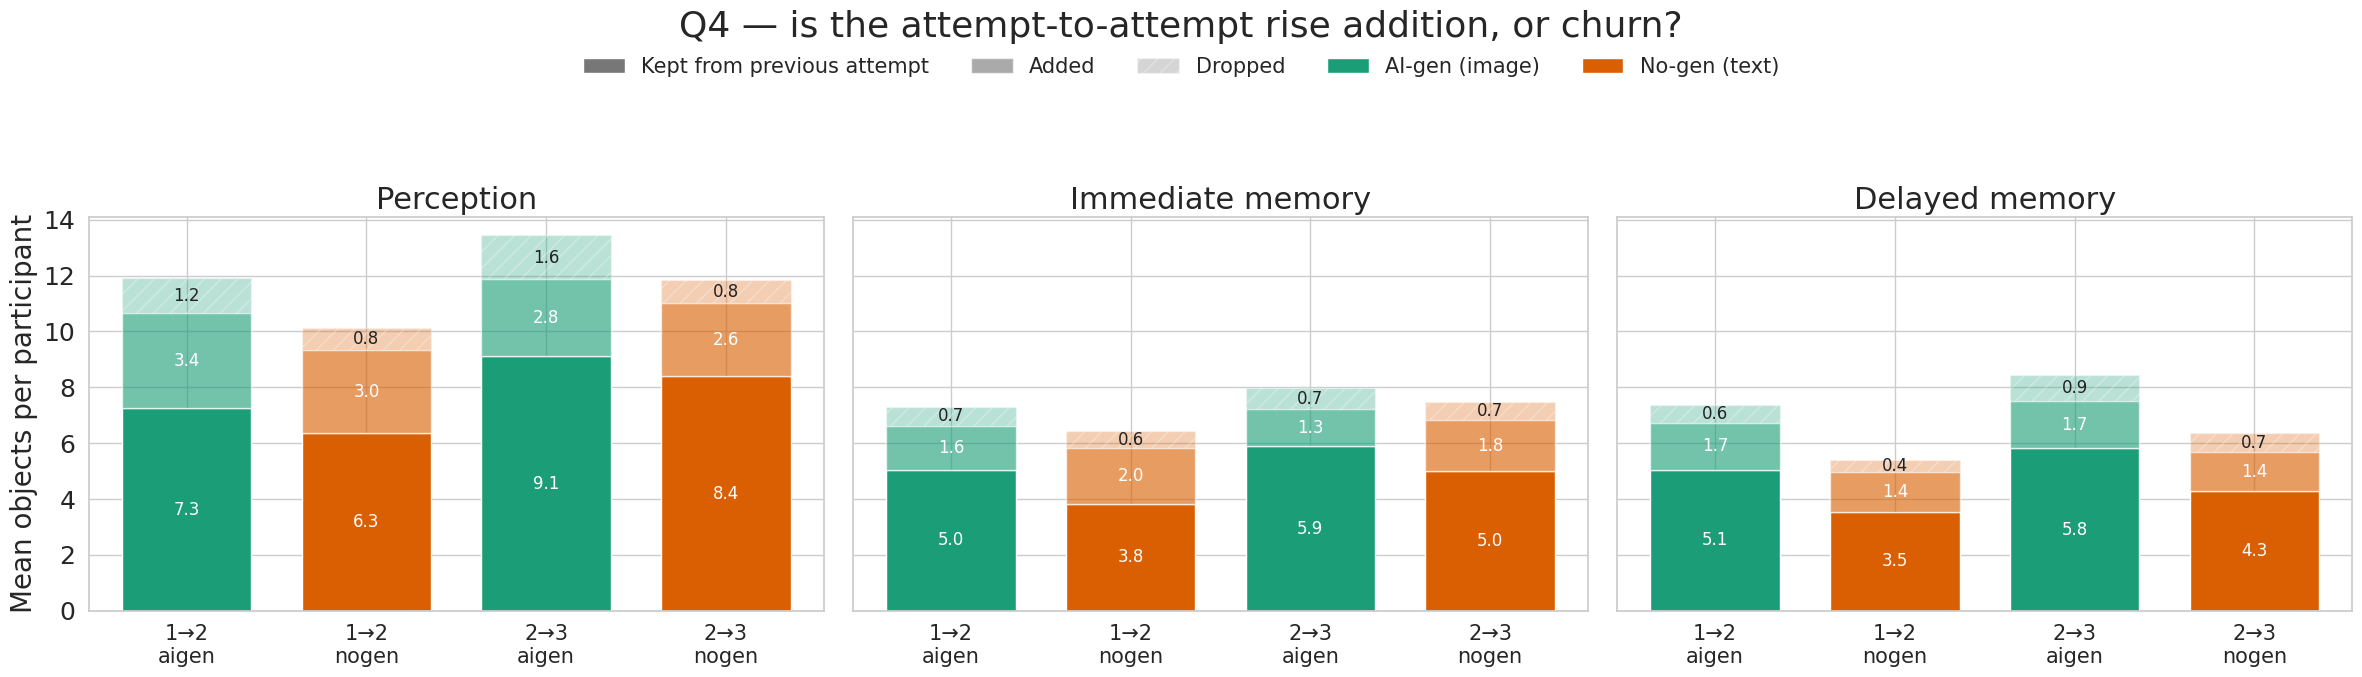

In [29]:
churn = (trans.groupby(["generation", "task", "transition", "uid"], as_index=False)
              [["n_kept", "n_added", "n_dropped"]].mean())

fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharey=True)
for ax, task in enumerate_tasks(axes):
    sub = churn[churn["task"] == task]
    x_labels, xs = [], []
    for i, (tr, gen) in enumerate(itertools.product(TRANS_ORDER, FB_GENS)):
        s = sub[(sub["transition"] == tr) & (sub["generation"] == gen)]
        if s.empty:
            continue
        bottom = 0
        for col, alpha, hatch in [("n_kept", 1.0, None), ("n_added", 0.62, None),
                                  ("n_dropped", 0.30, "//")]:
            v = s[col].mean()
            ax.bar(i, v, bottom=bottom, width=0.72, color=GEN_COLORS[gen], alpha=alpha,
                   hatch=hatch, edgecolor="white", linewidth=1.0, zorder=2)
            if v > 0.25:
                ax.text(i, bottom + v / 2, f"{v:.1f}", ha="center", va="center",
                        fontsize=12, color="white" if alpha > 0.5 else BAR_LABEL_COLOR)
            bottom += v
        xs.append(i); x_labels.append(f"{tr}\n{gen}")
    ax.set_xticks(xs); ax.set_xticklabels(x_labels, fontsize=15)
    ax.set_title(TASK_LABELS[task])
    ax.set_ylabel("Mean objects per participant" if ax is axes[0] else "")
    style_count_axis(ax)
handles = [Patch(facecolor="#777777", alpha=a, hatch=h, label=l)
           for a, h, l in [(1.0, None, "Kept from previous attempt"),
                           (0.62, None, "Added"), (0.30, "//", "Dropped")]]
handles += [Patch(facecolor=GEN_COLORS[g], label=GEN_LABELS[g]) for g in FB_GENS]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=5,
           frameon=False, fontsize=15)
fig.suptitle("Q4 — is the attempt-to-attempt rise addition, or churn?")
fig.tight_layout(rect=(0, 0, 1, 0.86))
save_fig(fig, GRAPHS / "q4_churn_decomposition.png")
plt.show()

### 5.2 Are the added objects the same across participants?

Left column: the top objects at **attempt 1**. Right column: the top objects **added** at
attempt 2 or 3, as a share of the participants who made any addition.

- Same objects on both sides → typical items simply arriving late.
- Different objects, with much lower shares on the right → genuine individual elaboration.

The reference markers are carried over from §4.1, so it is visible whether the added items are
in the image at all.

2220 added-object events, 927 distinct items
saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q4_added_vs_first_bedroom_l.png


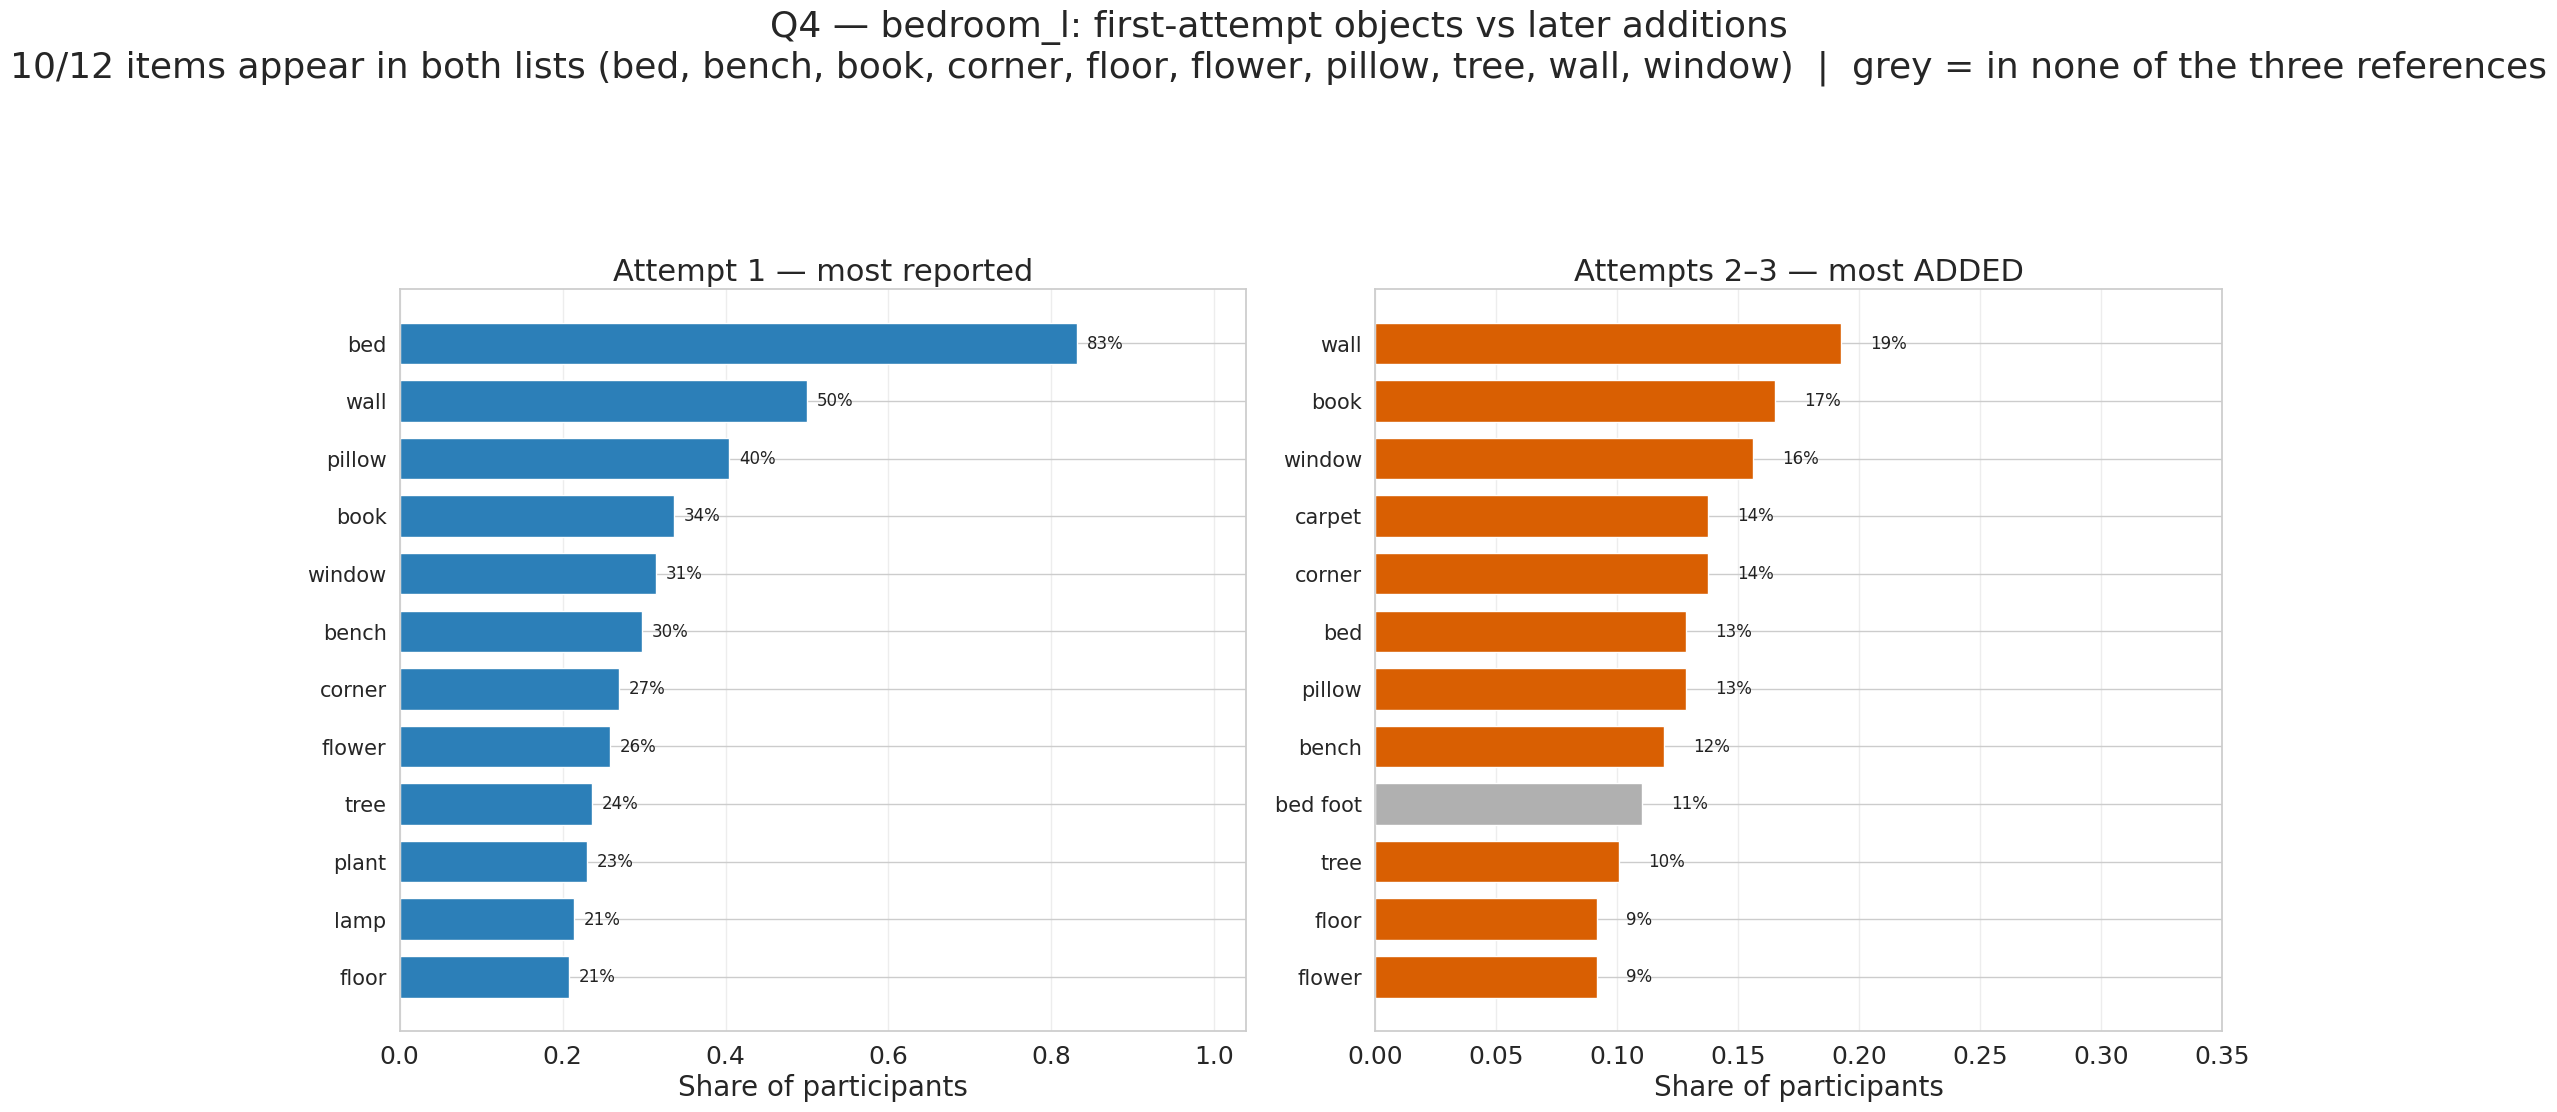

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q4_added_vs_first_living_room_h.png


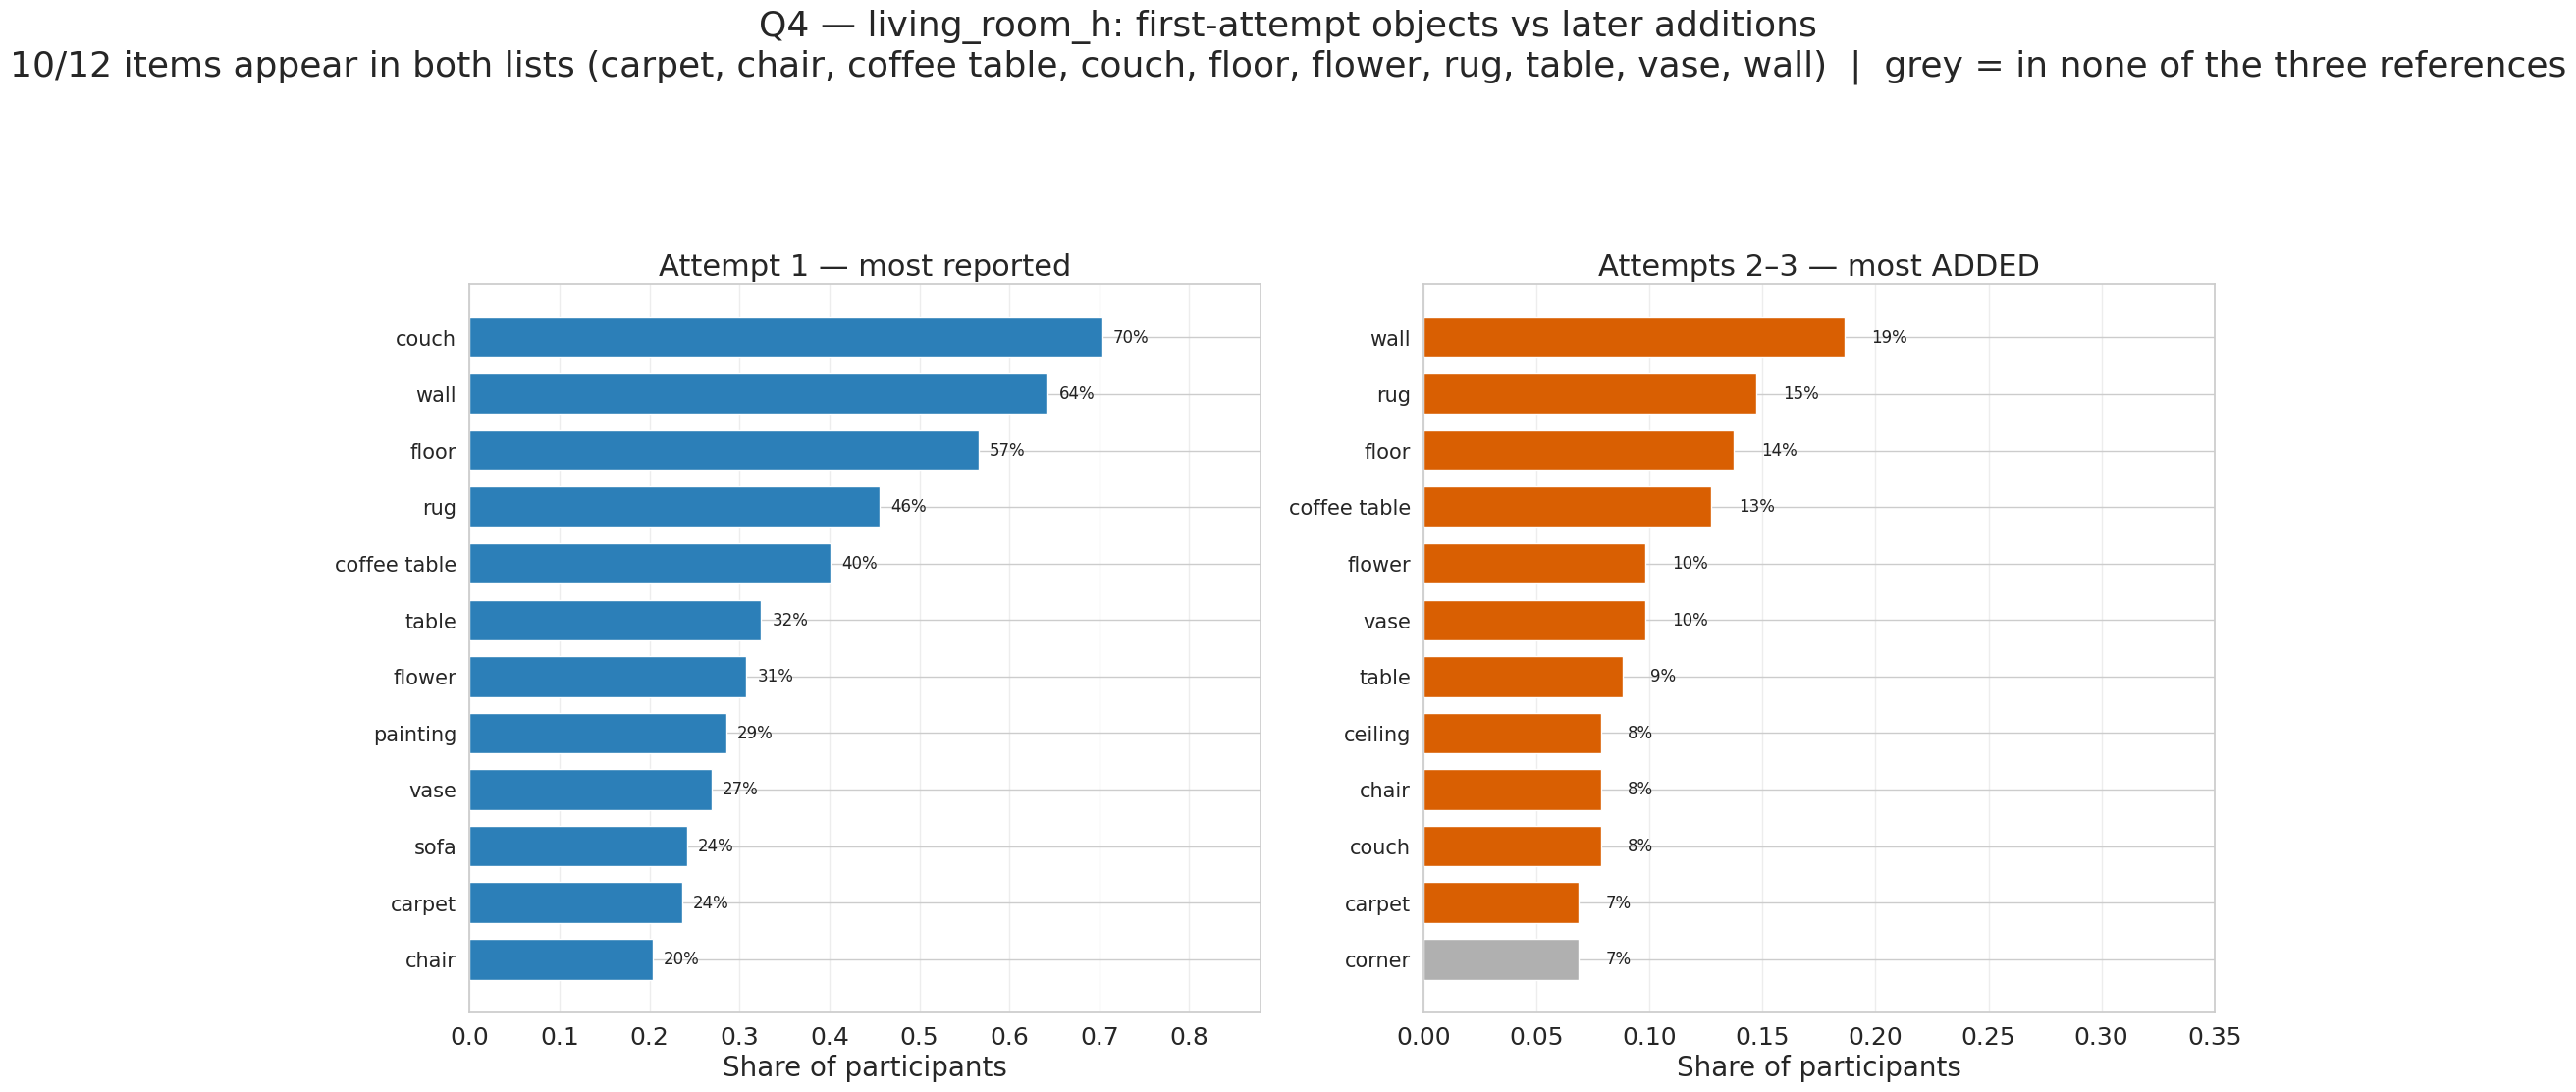

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q4_added_vs_first_conference_room_h.png


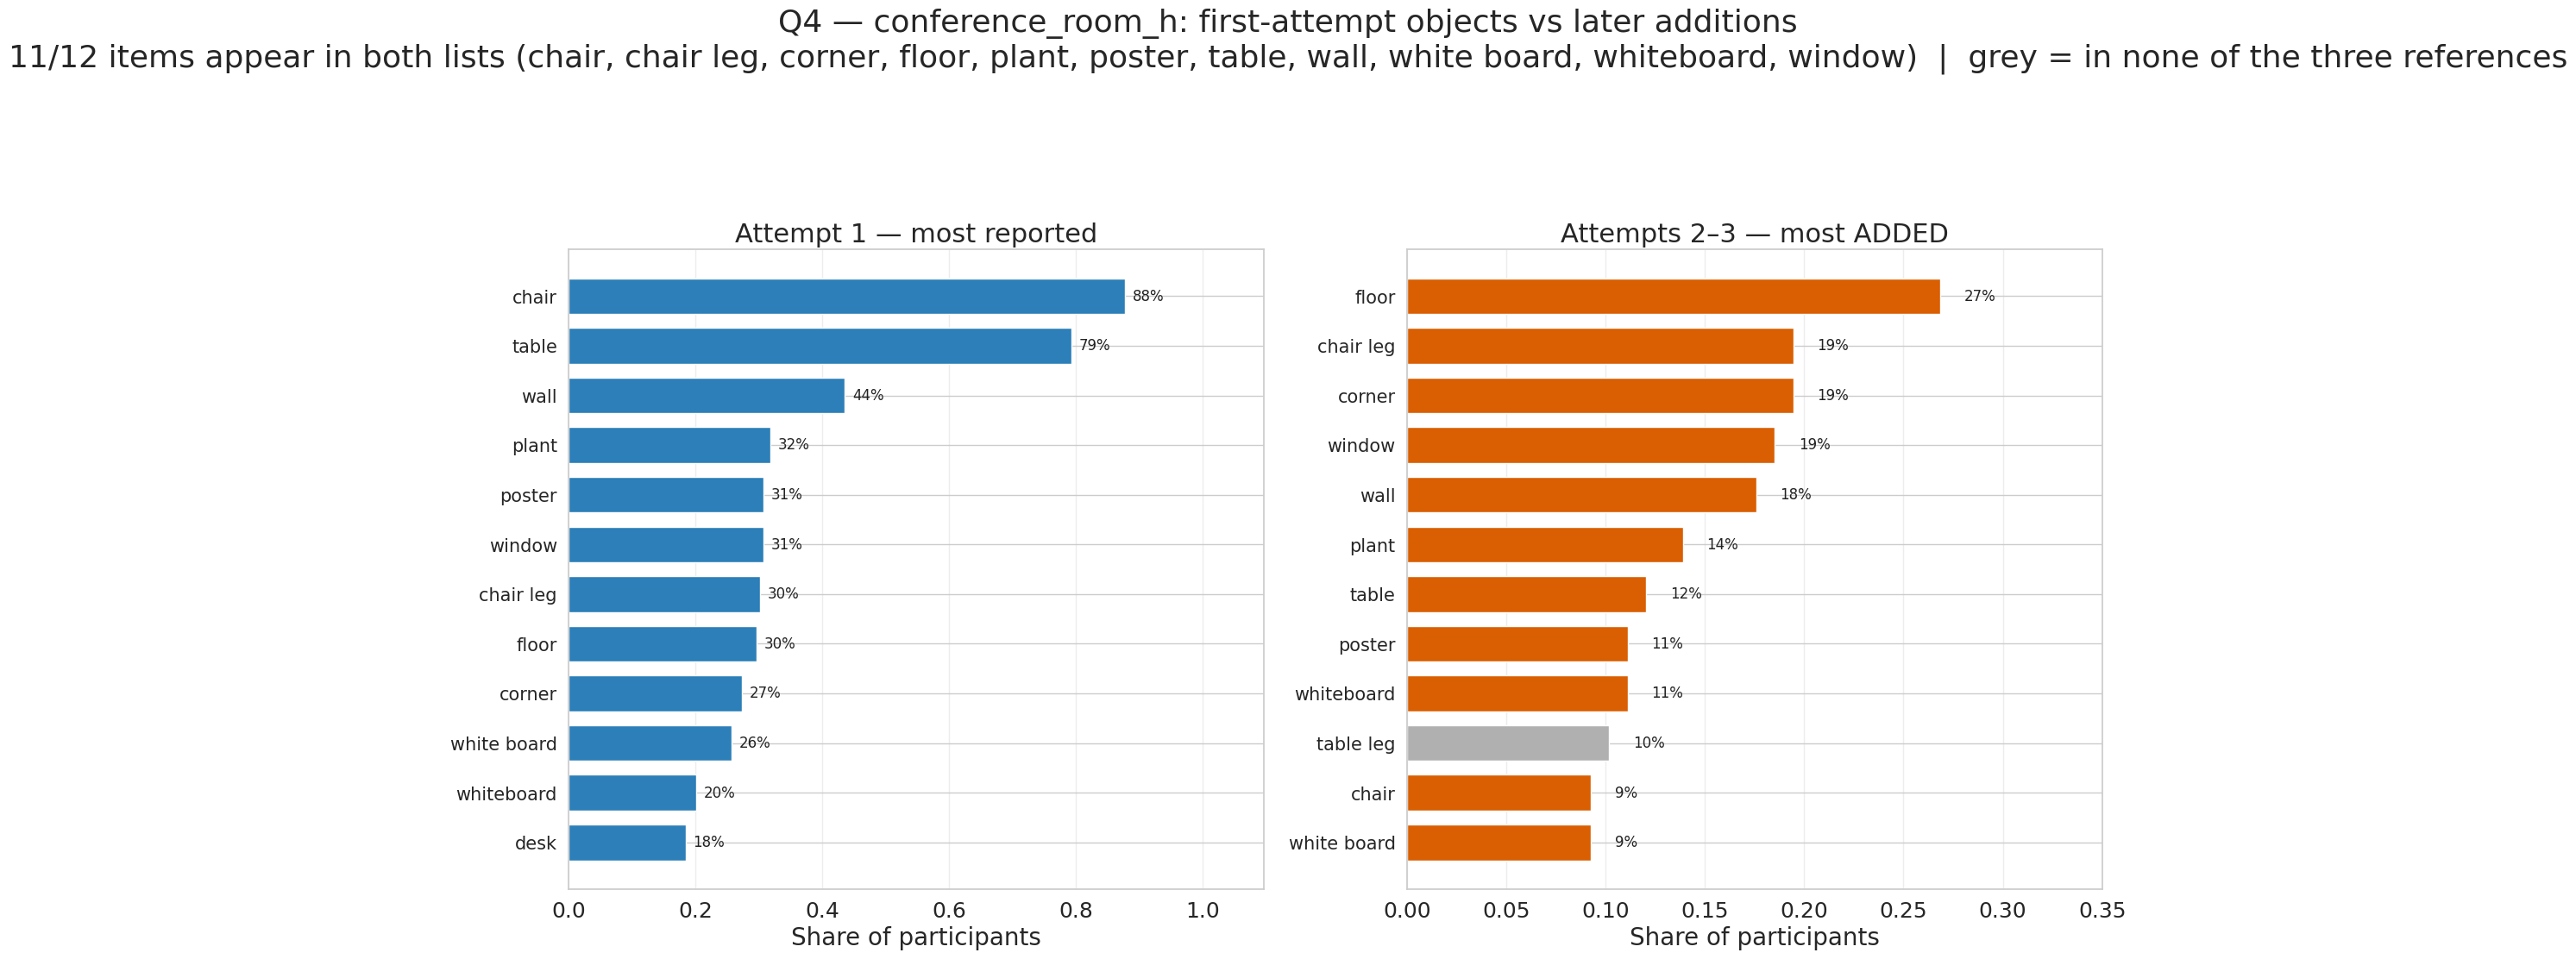

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q4_added_vs_first_lighthouse_h.png


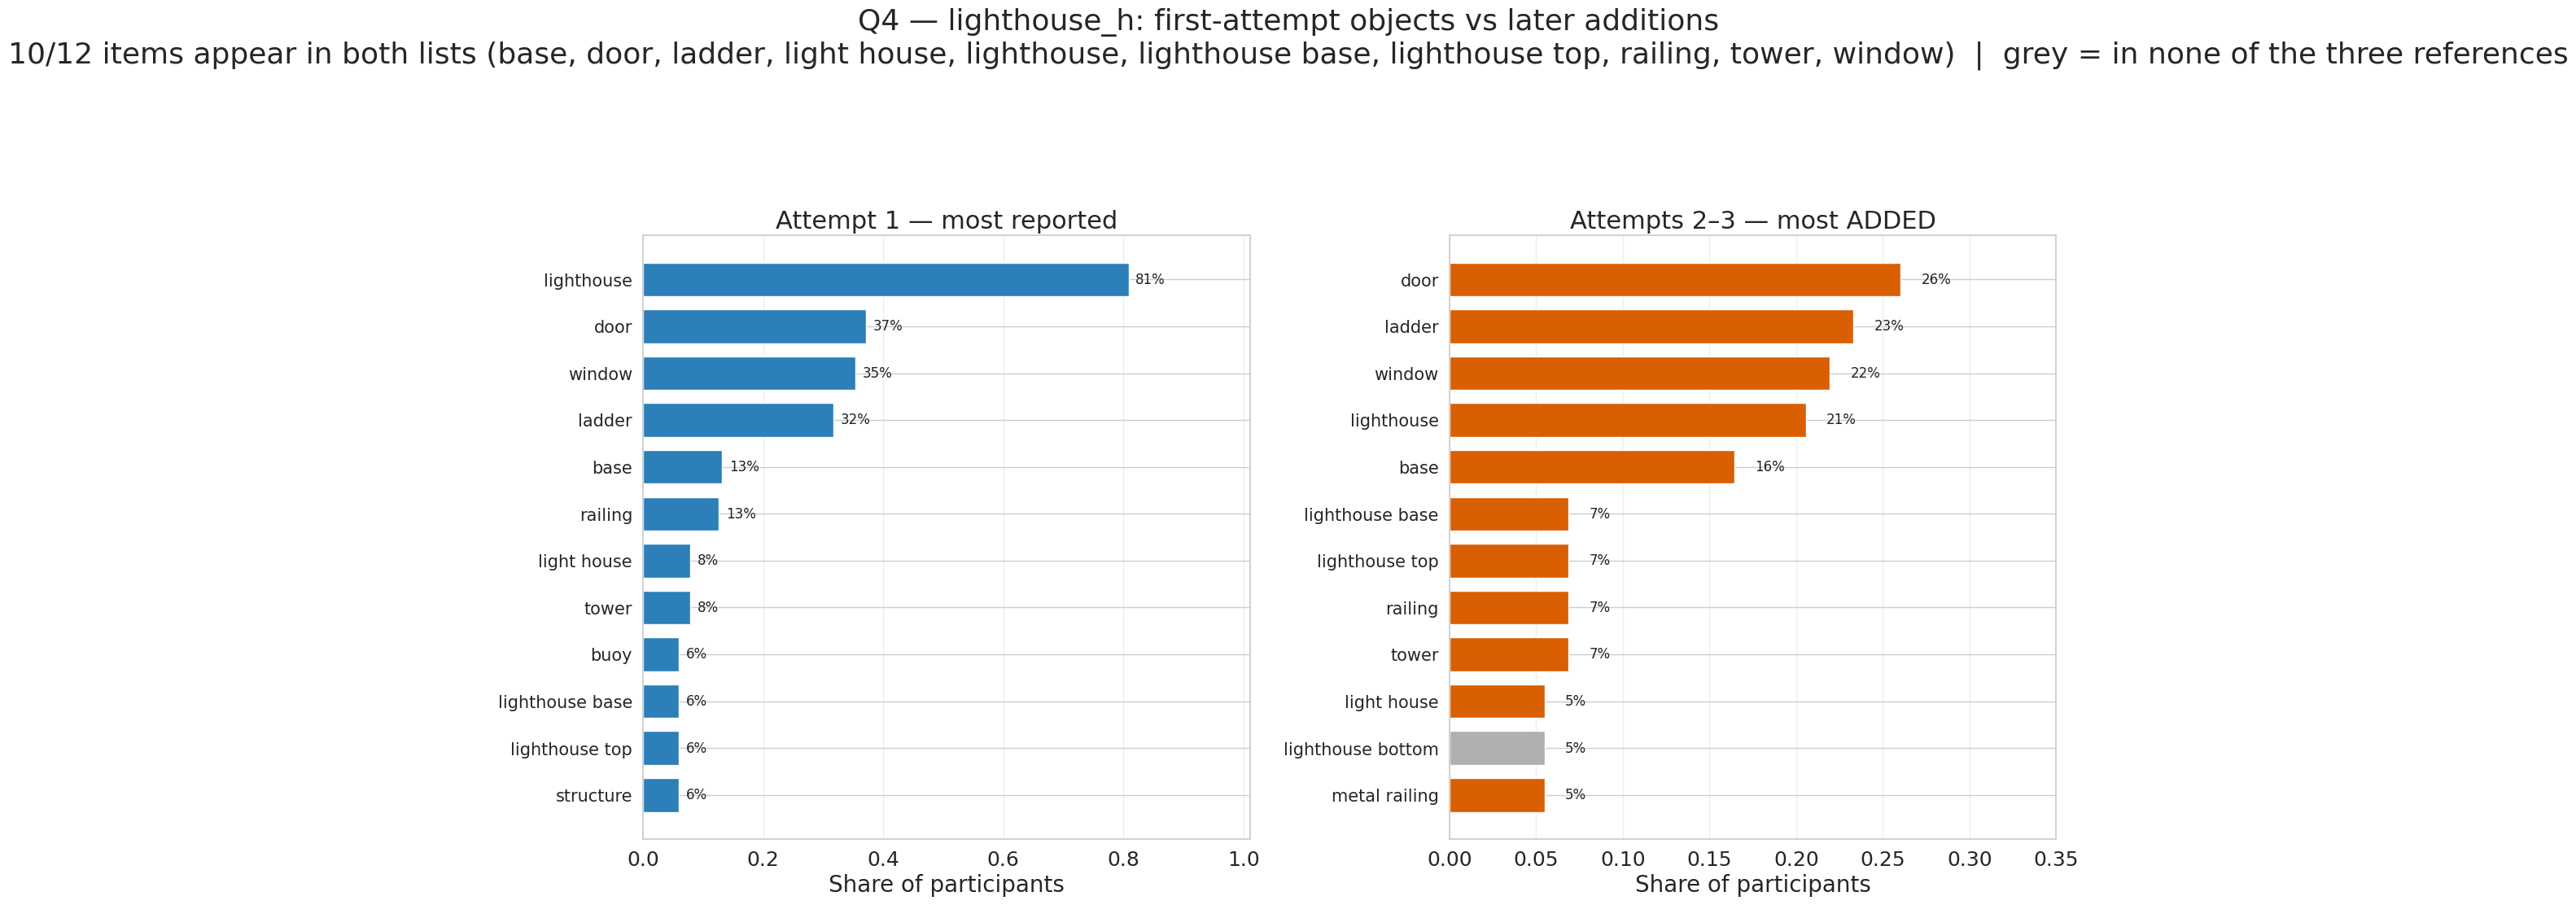

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q4_added_vs_first_playground_h.png


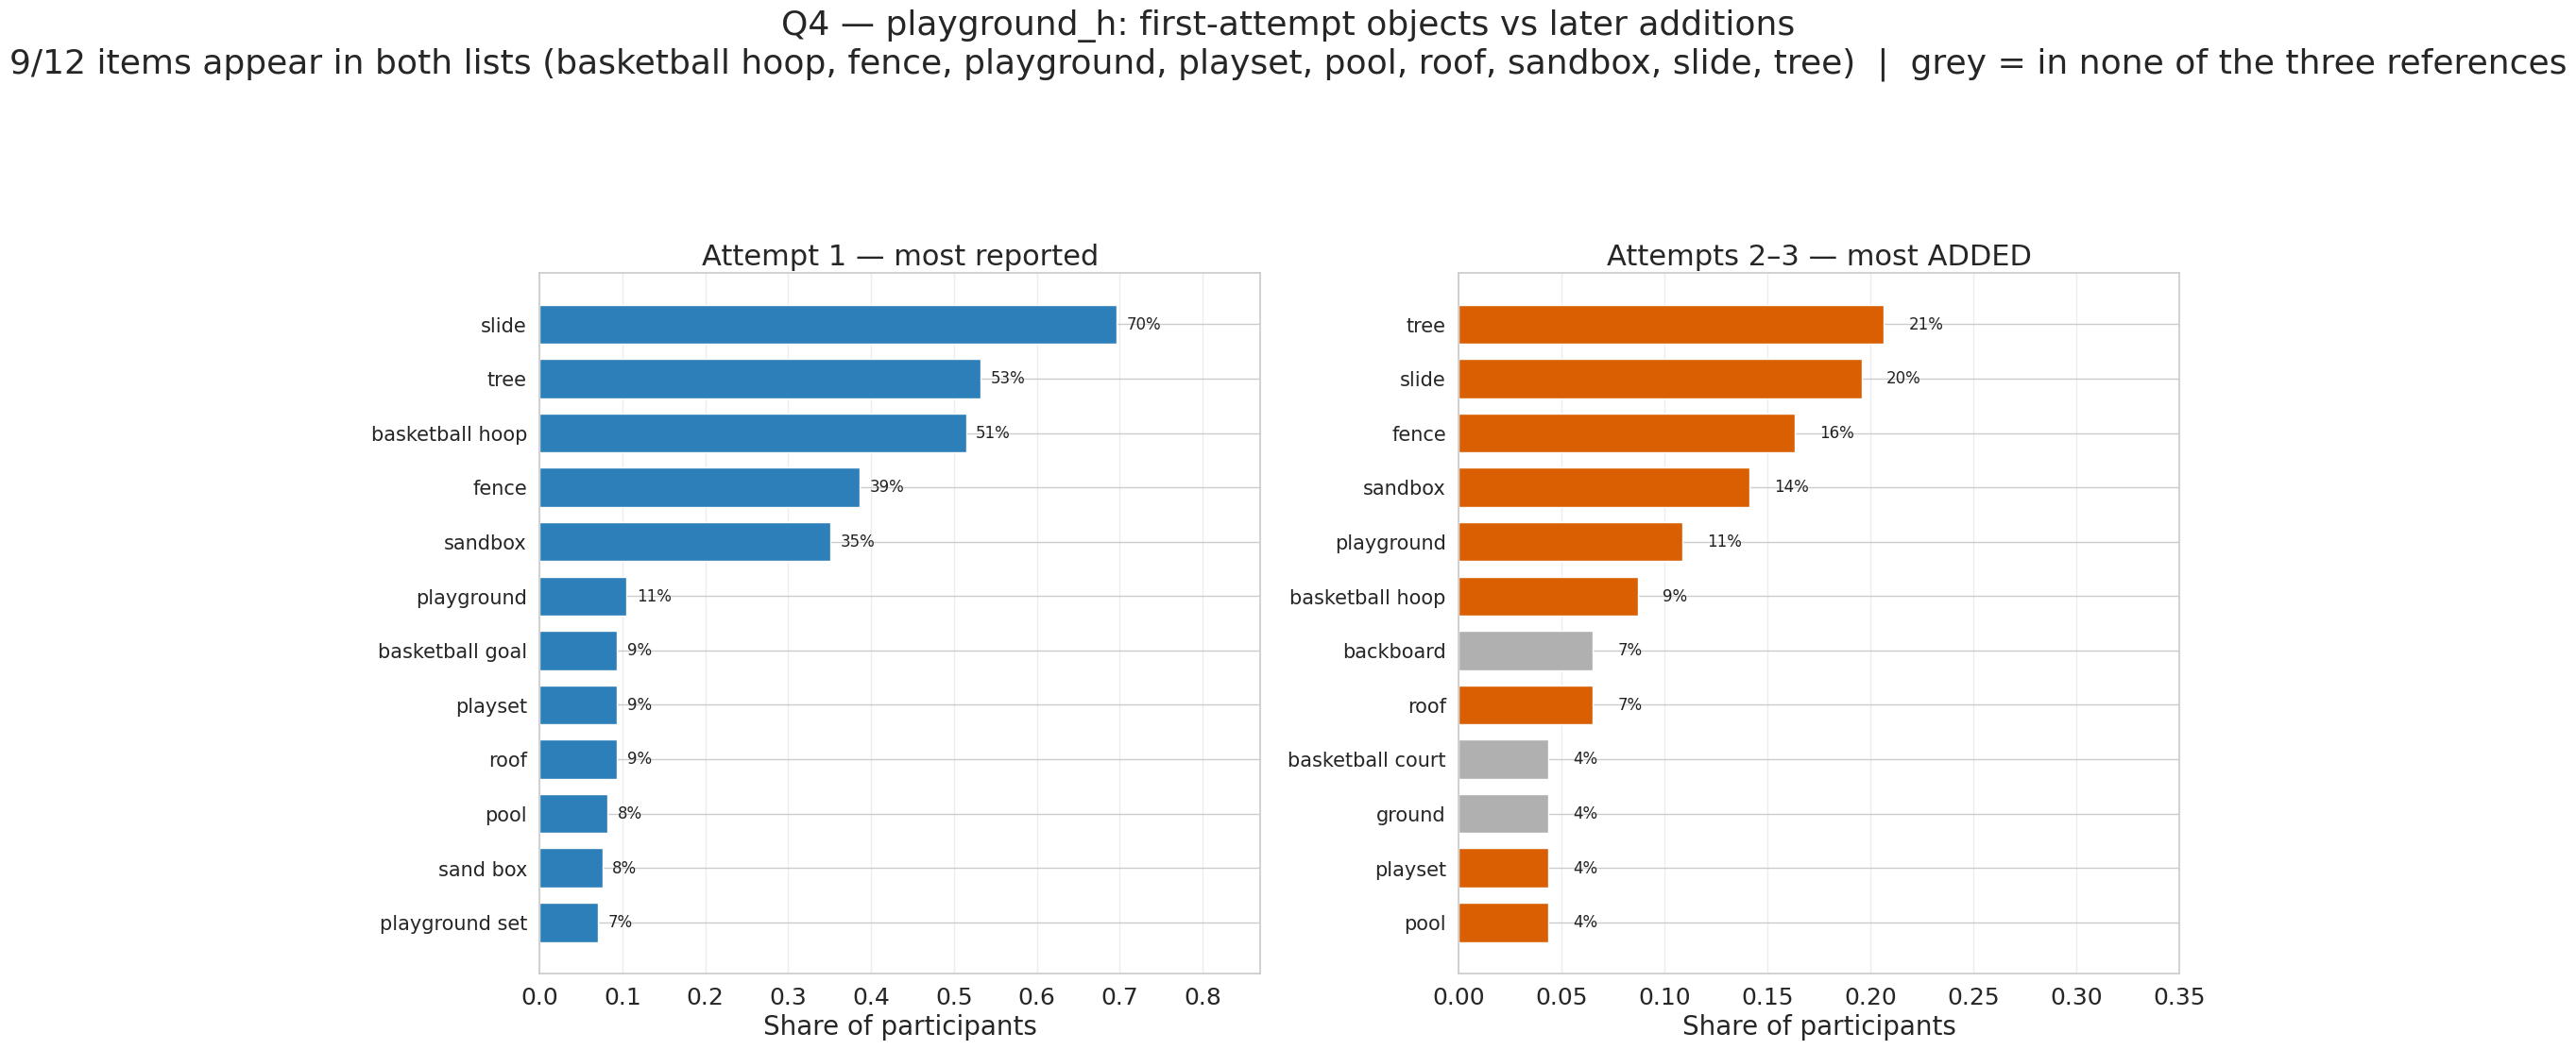

In [32]:
# One row per added object, with the judge's verdict for that item on the attempt it was
# added - merged back from `objs`, since the transition frame carries only the item strings.
added_long = (trans[["generation", "task", "uid", "gt", "attempt", "added_set"]]
              .explode("added_set")
              .dropna(subset=["added_set"])
              .rename(columns={"added_set": "item"})
              .merge(objs[["uid", "gt", "attempt", "item", "in_image"]]
                     .drop_duplicates(["uid", "gt", "attempt", "item"]),
                     on=["uid", "gt", "attempt", "item"], how="left", validate="m:1"))
assert added_long["in_image"].notna().all(), "an added item has no judge verdict"

share_added = item_share(added_long, keys=("gt",), attempts=None)
print(f"{len(added_long)} added-object events, {share_added['item'].nunique()} distinct items")


def plot_added_vs_first(gt, top_n=12, save=True):
    first = share_pooled[share_pooled["gt"] == gt].head(top_n)[::-1]
    add = share_added[share_added["gt"] == gt].head(top_n)[::-1]
    refs = reference_sets(gt, top_k=top_n)
    in_any = lambda it: any(it in s for s in refs.values())

    fig, axes = plt.subplots(1, 2, figsize=(20, 0.62 * top_n + 4))
    for ax, (data, title, color) in zip(axes, [
        (first, "Attempt 1 — most reported", "#2c7fb8"),
        (add, "Attempts 2–3 — most ADDED", "#d95f02"),
    ]):
        if data.empty:
            ax.set_visible(False)
            continue
        colors = [color if in_any(it) else "#b0b0b0" for it in data["item"]]
        ax.barh(range(len(data)), data["share"], color=colors, height=0.72,
                edgecolor="white", zorder=2)
        for i, (v, f) in enumerate(zip(data["share"], data["frac_in_image"])):
            ax.text(v + 0.012, i, f"{v:.0%}", va="center", fontsize=12,
                    color=BAR_LABEL_COLOR)
        ax.set_yticks(range(len(data)))
        ax.set_yticklabels(data["item"], fontsize=15)
        ax.set_xlim(0, max(0.35, data["share"].max() * 1.25))
        ax.set_xlabel("Share of participants")
        ax.set_title(title)
        ax.grid(True, axis="x", alpha=0.35)
    overlap = set(first["item"]) & set(add["item"])
    fig.suptitle(f"Q4 — {GT_LABELS[gt]}: first-attempt objects vs later additions\n"
                 f"{len(overlap)}/{top_n} items appear in both lists "
                 f"({', '.join(sorted(overlap)) if overlap else 'none'})  |  "
                 "grey = in none of the three references")
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    if save:
        save_fig(fig, GRAPHS / f"q4_added_vs_first_{GT_LABELS[gt]}.png")
    plt.show()


for gt in GT_ORDER:
    plot_added_vs_first(gt)

### 5.3 Do people converge on the same additions?

Mean pairwise Jaccard of the **added** sets, against the same statistic on the attempt-1 sets.
Additions that are idiosyncratic will sit well below the attempt-1 bar; additions that are the
same typical items arriving late will sit at or above it.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q4_convergence_jaccard.png


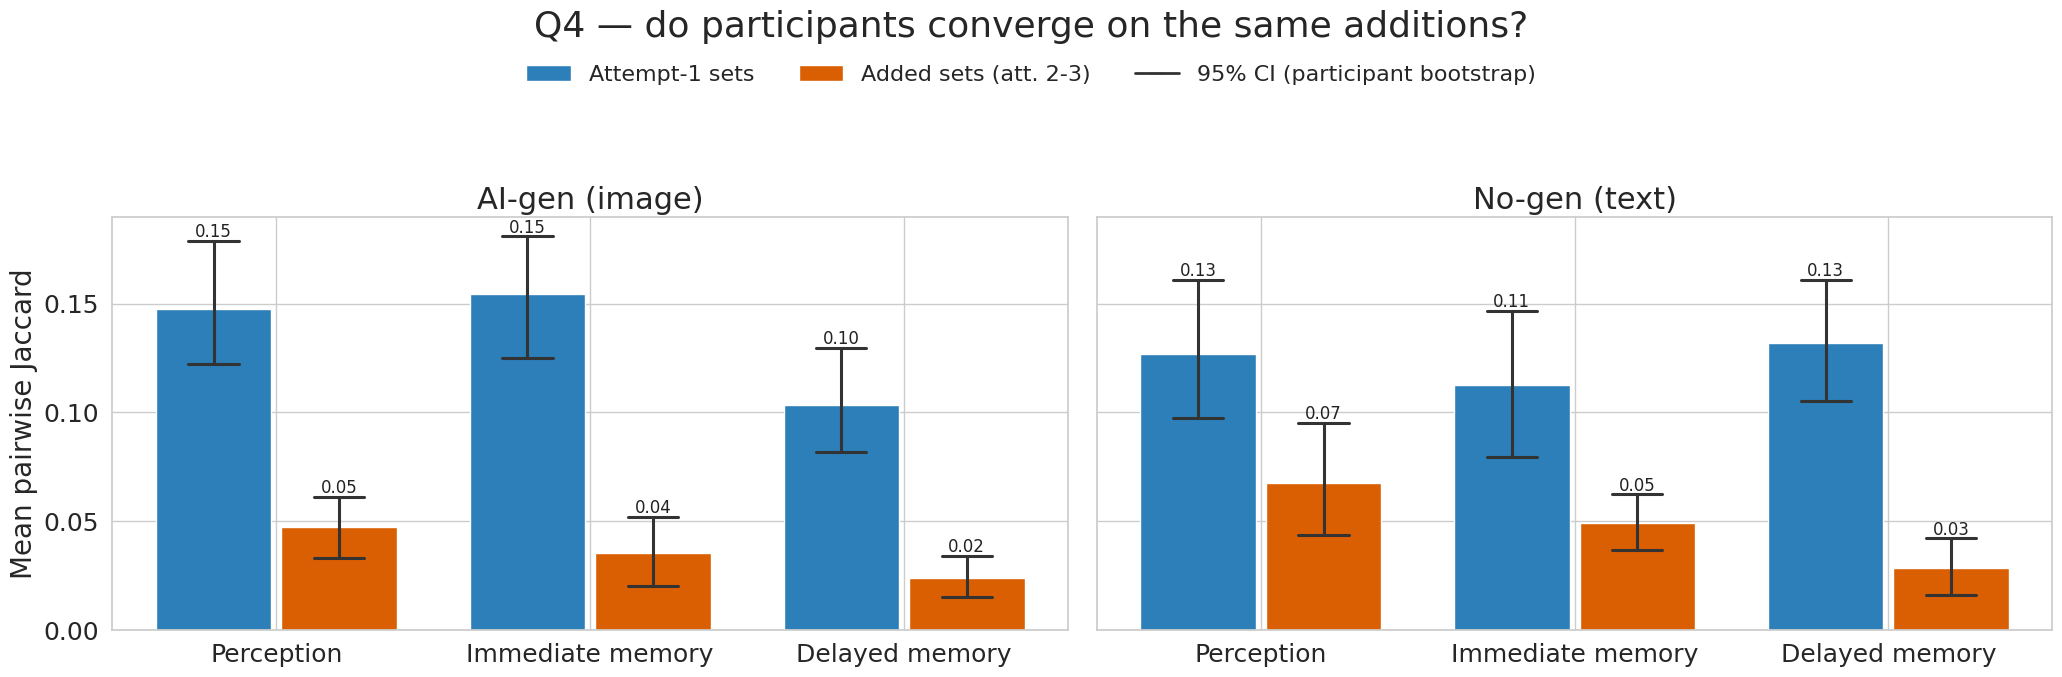

task                              delay  immediate  perception
generation what                                               
aigen      Added sets (att. 2-3)  0.024      0.035       0.047
           Attempt-1 sets         0.104      0.155       0.147
nogen      Added sets (att. 2-3)  0.028      0.049       0.067
           Attempt-1 sets         0.132      0.112       0.127

In [33]:
rows = []
for (gen, task), sets in participant_sets(objs, ["generation", "task"]).items():
    if gen not in FB_GENS:
        continue
    m, lo, hi = jaccard_ci(sets)
    rows.append({"generation": gen, "task": task, "what": "Attempt-1 sets",
                 "jaccard": m, "lo": lo, "hi": hi, "n": len(sets)})
for (gen, task), grp in trans.groupby(["generation", "task"]):
    sets = [set().union(*g["added_set"]) if len(g) else set()
            for _, g in grp.groupby("uid")]
    m, lo, hi = jaccard_ci(sets)
    rows.append({"generation": gen, "task": task, "what": "Added sets (att. 2-3)",
                 "jaccard": m, "lo": lo, "hi": hi, "n": len(sets)})
conv = pd.DataFrame(rows)

WHAT_ORDER = ["Attempt-1 sets", "Added sets (att. 2-3)"]
WHAT_COLORS = {"Attempt-1 sets": "#2c7fb8", "Added sets (att. 2-3)": "#d95f02"}

fig, axes = plt.subplots(1, 2, figsize=(21, 7), sharey=True)
for ax, gen in zip(axes, FB_GENS):
    sub = conv[conv["generation"] == gen]
    offsets, width = geom(WHAT_ORDER)
    for i, task in enumerate(TASK_ORDER):
        for what in WHAT_ORDER:
            r = sub[(sub["task"] == task) & (sub["what"] == what)]
            if r.empty or np.isnan(r["jaccard"].iloc[0]):
                continue
            r = r.iloc[0]
            ax.bar(i + offsets[what], r["jaccard"], width=width * 0.92,
                   color=WHAT_COLORS[what], zorder=2)
            draw_interval(ax, i + offsets[what], r["lo"], r["hi"], width=width * 0.4)
            ax.text(i + offsets[what],
                    max(r["hi"], r["jaccard"]) if not np.isnan(r["hi"]) else r["jaccard"],
                    f"{r['jaccard']:.2f}", ha="center",
                    va="bottom", fontsize=12, color=BAR_LABEL_COLOR, zorder=6)
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t] for t in TASK_ORDER])
    ax.set_title(GEN_LABELS[gen])
    ax.set_ylabel("Mean pairwise Jaccard" if ax is axes[0] else "")
    style_count_axis(ax)
handles = [Patch(facecolor=WHAT_COLORS[w], label=w) for w in WHAT_ORDER]
handles.append(Line2D([], [], color=CI_COLOR, lw=2, marker="_", markersize=10,
                      label="95% CI (participant bootstrap)"))
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=3,
           frameon=False)
fig.suptitle("Q4 — do participants converge on the same additions?")
fig.tight_layout(rect=(0, 0, 1, 0.86))
save_fig(fig, GRAPHS / "q4_convergence_jaccard.png")
plt.show()

display(conv.pivot_table(index=["generation", "what"], columns="task",
                         values="jaccard").round(3))

### 5.4 Are the additions accurate?

The sharpest test of the feedback loop. Of the objects a participant *adds* at attempt 2 or 3,
what fraction does the judge reject — and how does that compare with their attempt-1 objects?

- Added items **less** hallucinated than attempt-1 items → feedback is recruiting real detail.
- Added items **more** hallucinated → the loop is buying confabulation.
- **aigen vs nogen is the contrast that matters**: only aigen participants saw a picture, so a
  difference here is what the generated image is actually contributing.

NameError: name 'FLOOR' is not defined

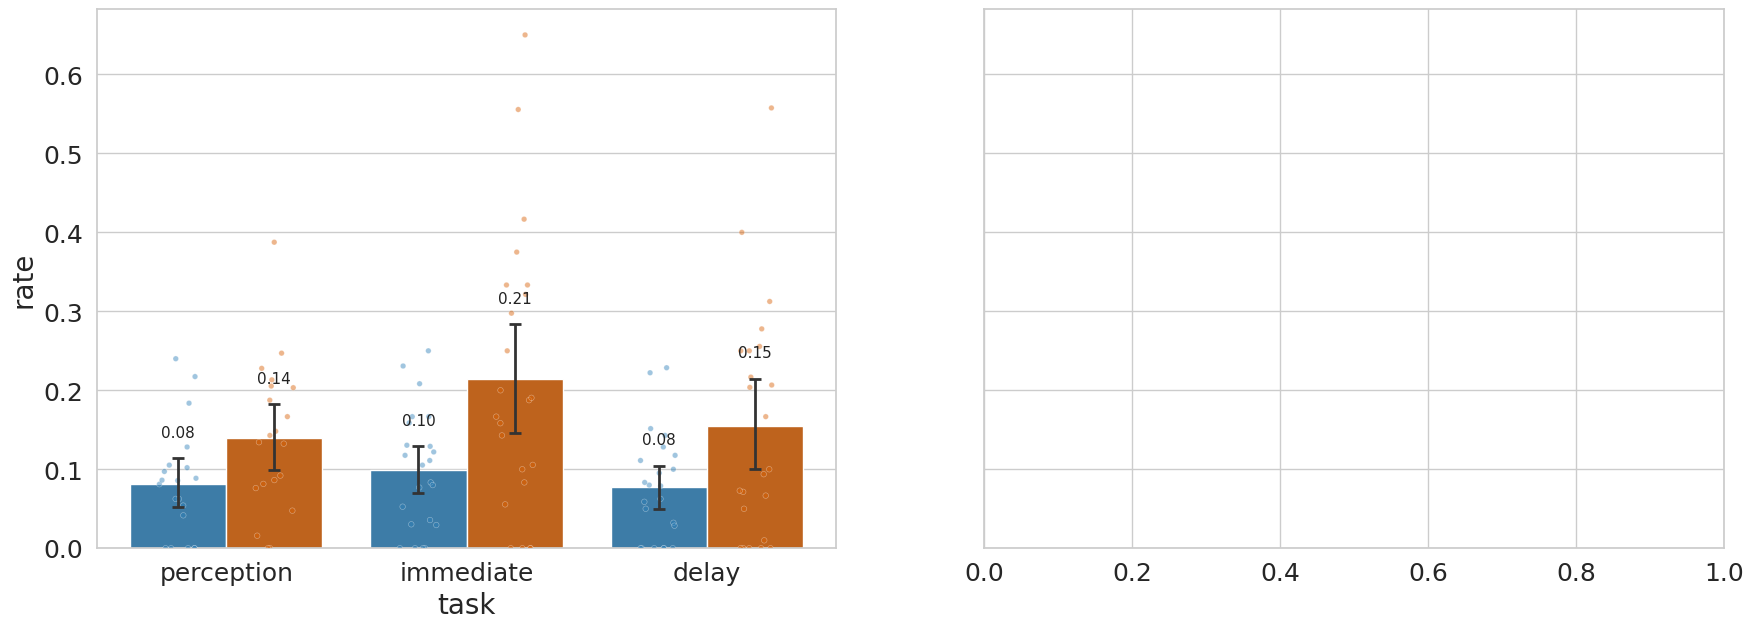

In [34]:
base = (objs[(objs["attempt"] == 1) & objs["generation"].isin(FB_GENS)]
        .groupby(["generation", "task", "uid"], as_index=False)["in_image"]
        .mean().rename(columns={"in_image": "rate"}))
base["rate"] = 1 - base["rate"]
base["what"] = "Attempt-1 objects"

add_rate = (trans.groupby(["generation", "task", "uid"], as_index=False)["halluc_rate_added"]
                 .mean().rename(columns={"halluc_rate_added": "rate"}).dropna(subset=["rate"]))
add_rate["what"] = "Objects added at 2-3"

acc = pd.concat([base, add_rate], ignore_index=True)
ACC_ORDER = ["Attempt-1 objects", "Objects added at 2-3"]
ACC_COLORS = {"Attempt-1 objects": "#2c7fb8", "Objects added at 2-3": "#d95f02"}

fig, axes = plt.subplots(1, 2, figsize=(21, 7), sharey=True)
for ax, gen in zip(axes, FB_GENS):
    sub = acc[acc["generation"] == gen]
    vmax = draw_bars(ax, sub, "task", TASK_ORDER, "what", ACC_ORDER, "rate",
                     palette=ACC_COLORS, fmt="{:.2f}")
    if FLOOR is not None:
        ax.axhline(FLOOR, color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t] for t in TASK_ORDER])
    ax.set_xlabel(""); ax.set_title(GEN_LABELS[gen])
    ax.set_ylabel("Share rejected by the judge" if ax is axes[0] else "")
    style_count_axis(ax, vmax=vmax)
handles = [Patch(facecolor=ACC_COLORS[w], label=w) for w in ACC_ORDER]
handles.append(Line2D([], [], color=CI_COLOR, lw=2, marker="_", markersize=10,
                      label="95% CI"))
if FLOOR is not None:
    handles.append(Line2D([], [], color=GPT_DESC_COLOR, lw=2.4, ls="--",
                          label="Judge false-positive floor"))
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.93),
           ncol=len(handles), frameon=False, fontsize=15)
fig.suptitle("Q4 — are the objects added under feedback accurate?")
fig.tight_layout(rect=(0, 0, 1, 0.86))
save_fig(fig, GRAPHS / "q4_addition_accuracy.png")
plt.show()

### 5.5 Are the additions *typical*?

The last piece: do added objects hit the three reference sets from §4.1 at a higher or lower
rate than attempt-1 objects? A drop on the **pooled consensus** reference is the clearest
signal that later attempts move away from the shared core and into personal detail.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/exploratory_hypotheses/q4_addition_typicality.png


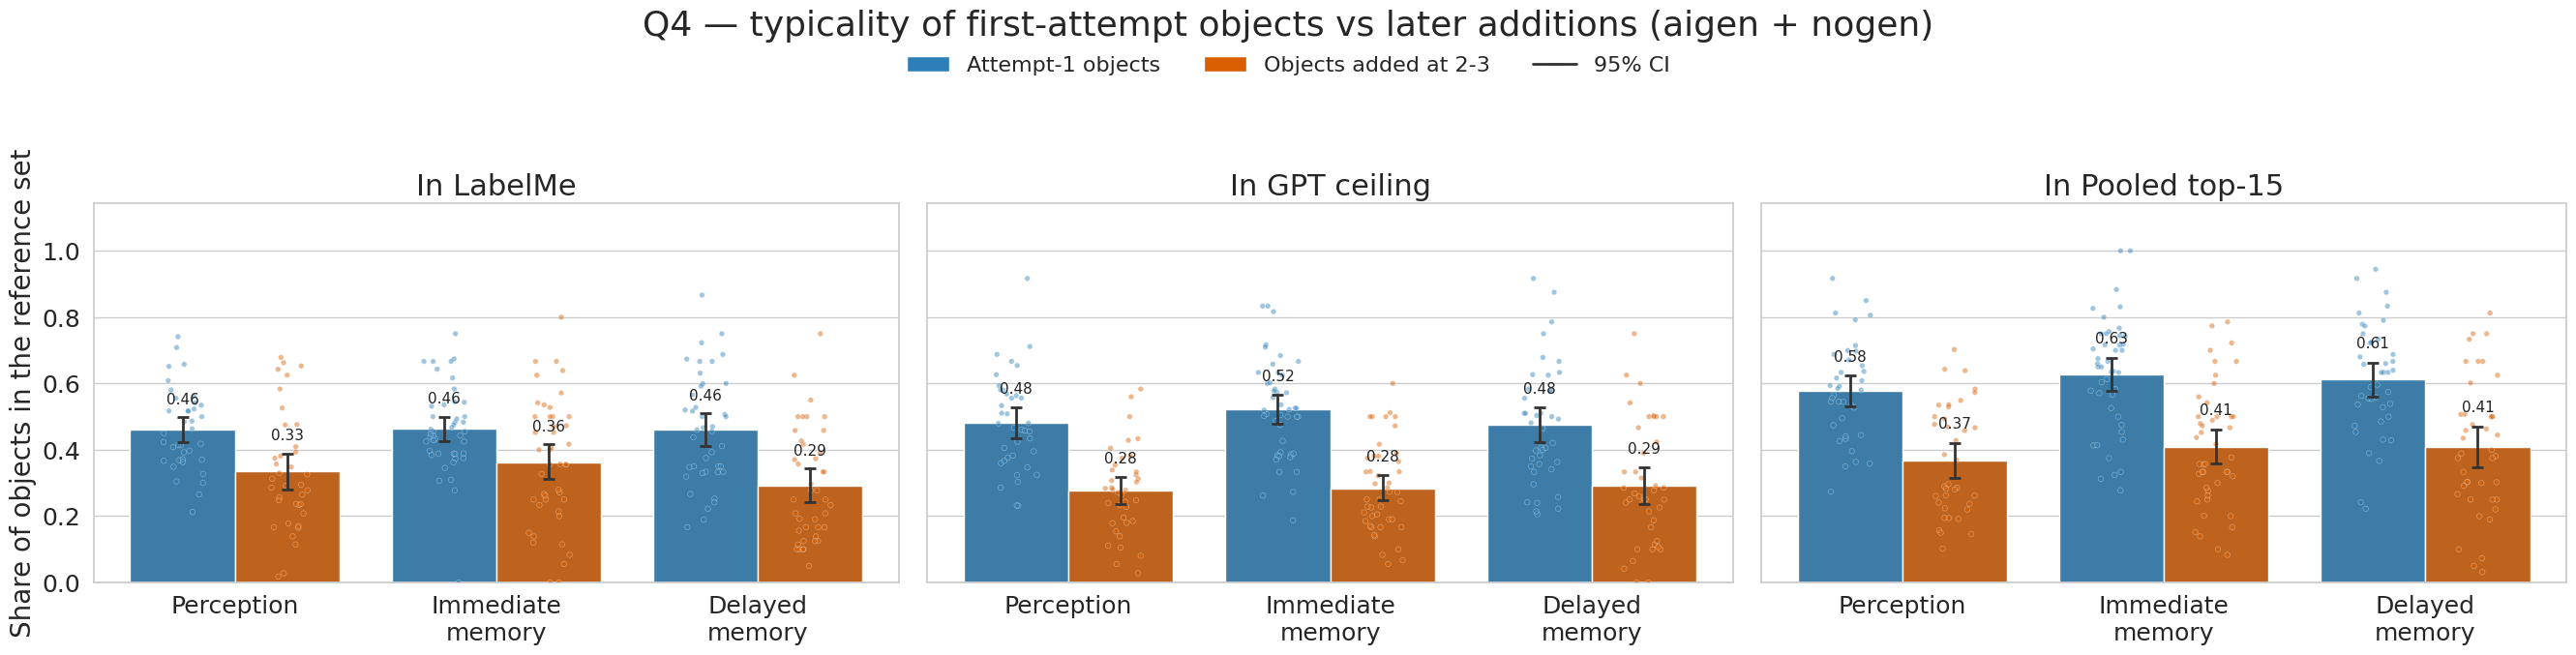

In [35]:
REF_NAMES = list(reference_sets(GT_ORDER[0], top_k=TOP_N))
REFS = {gt: reference_sets(gt, top_k=TOP_N) for gt in GT_ORDER}


def ref_hit_rates(pairs, label):
    """pairs: iterable of (generation, task, uid, gt, items) -> mean hit rate per reference."""
    rows = []
    for gen, task, uid, gt, its in pairs:
        its = list(its)
        if not its:
            continue
        r = {"generation": gen, "task": task, "uid": uid, "what": label}
        for name in REF_NAMES:
            s = REFS[gt][name]
            r[name] = np.mean([i in s for i in its]) if s else np.nan
        rows.append(r)
    return pd.DataFrame(rows)


first_pairs = ((g, t, u, gt, grp["item"].tolist())
               for (g, t, u, gt), grp in
               objs[(objs["attempt"] == 1) & objs["generation"].isin(FB_GENS)]
               .groupby(["generation", "task", "uid", "gt"]))
added_pairs = ((r.generation, r.task, r.uid, r.gt, r.added_set)
               for r in trans.itertuples(index=False))

hits = pd.concat([ref_hit_rates(first_pairs, "Attempt-1 objects"),
                  ref_hit_rates(added_pairs, "Objects added at 2-3")], ignore_index=True)
hits = hits.groupby(["generation", "task", "uid", "what"], as_index=False)[REF_NAMES].mean()

fig, axes = plt.subplots(1, len(REF_NAMES), figsize=(9 * len(REF_NAMES), 7), sharey=True)
for ax, name in zip(np.atleast_1d(axes), REF_NAMES):
    sub = hits.dropna(subset=[name])
    if sub.empty:
        ax.set_visible(False)
        continue
    vmax = draw_bars(ax, sub, "task", TASK_ORDER, "what", ACC_ORDER, name,
                     palette=ACC_COLORS, fmt="{:.2f}")
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t].replace(" ", "\n") for t in TASK_ORDER])
    ax.set_xlabel(""); ax.set_title(f"In {name}")
    ax.set_ylabel("Share of objects in the reference set")
    style_count_axis(ax, vmax=vmax)
handles = [Patch(facecolor=ACC_COLORS[w], label=w) for w in ACC_ORDER]
handles.append(Line2D([], [], color=CI_COLOR, lw=2, marker="_", markersize=10, label="95% CI"))
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=3,
           frameon=False)
fig.suptitle("Q4 — typicality of first-attempt objects vs later additions (aigen + nogen)")
fig.tight_layout(rect=(0, 0, 1, 0.87))
save_fig(fig, GRAPHS / "q4_addition_typicality.png")
plt.show()

---
## Notes and caveats

- **Stale semantic data.** 1981 of 2101 trials. Re-run pipeline stages 6–7
  (`semantic_tagging.py`, `object_accuracy_detector.py`, `export_full_data.py`) and re-execute
  this notebook; nothing here needs editing.
- **§3 rests on one image.** `bedroom_l` is the only low-memorability GT, so memorability and
  image identity are perfectly confounded. §3.1 also shows `bedroom_l` has the *highest* GPT
  ceiling object count of the five, so it is the richest scene as well as the least memorable —
  another reason to treat §3 as a reason to run more low-memorability images, not as a result.
- **The synonym map in §4.1 is a judgement call.** It is printed in full so it can be argued
  with. Every LabelMe / ceiling number in §4–§5 depends on it; the pooled-consensus reference
  does not, which is part of why it is there.
- **No inferential tests anywhere.** Every interval is a percentile bootstrap over
  participants. Nothing here is corrected for multiple comparisons, and with 9 cells × many
  measures some intervals will exclude zero by chance. Use this to decide what to model, not
  as evidence.
- **`subjective_score` is aigen-only** — it is a rating of an image the participant was shown,
  and nogen/plain participants were shown none.